# Multimodal depression analysis on DAIC-WOZ
Two parts. **Part A (Sections 1 to 8)** explores the two case-study sessions, 303 (PHQ-8 binary 0, not depressed) and 319 (binary 1, depressed): text, voice, face, gaze and head movement. **Part B (Sections 9 to 16)** works on a whole cohort of other sessions: a stratified 80/10/10 split by session, LSTM and BiLSTM text models on three input representations, selection of the best text model, fusion of its score with the other modalities, and a final Depressed or Not depressed decision, with the case sessions as untouched examples.

## How to run it
Run Section 1 first. Part A blocks need Section 2. Part B needs only Section 1 and runs on its own.

| Block | What it does | Needs |
|---|---|---|
| 1 Setup | libraries, paths, sessions, cohort list | none |
| 2 Data loading | case-session transcripts, labels, Ellie's question for each answer | 1 |
| 3 Behaviour and text preparation | PHQ-8 items, talk and grammar features, questions matched to PHQ-8 items | 2 |
| 4 Text analysis | tone per answer, distinctive wording, PHQ-8 symptom evidence | 2 |
| 5 to 8 Voice, face, gaze and head, fusion | descriptors for the case sessions | 2 |
| 9 Cohort and split | unzip the needed files, labels, stratified 80/10/10 split by session | 1 |
| 10 Text data and representations | windows of participant text, raw tokens, Word2Vec, Word2Vec with positional encoding | 9 |
| 11 Train and evaluate text models | LSTM and BiLSTM on three representations, out-of-fold scores, best model, shuffled-label control | 10 |
| 12 Multimodal features | numeric voice, face, gaze, head and behaviour features for every session | 9 |
| 13 Fusion | text score plus features, scikit-learn classifier, final decision | 11 and 12 |
| 14 Modelling figures | model comparison, curves, ablation, case sessions | 11 and 13 |
| 15 Report figures | every figure and table, saved and zipped | whatever you have run |
| 16 Appendix | pretrained reference scores for the case sessions | 10 |

## What the label is
The label is the PHQ-8 binary value of a whole interview, from the AVEC split files. A text window inherits its session's label. No pretrained model output is used as a label, a feature or an input to the fusion.

## Leakage rules Part B follows
1. Splitting is by session and stratified by label. A session is in exactly one of train, validation or test, and the notebook asserts it. Sessions 303 and 319 are outside the cohort.
2. The vocabulary, Word2Vec and the model weights are fitted on training windows only, inside every run, including every cross-validation fold.
3. Validation sessions only decide when a network stops training. Test sessions are used for reporting only. The best text model is chosen by out-of-fold results on training sessions, not by the test sessions.
4. The fusion model sees an out-of-fold text score for every training session, so it never learns from a text score produced by a model that had seen that session.
5. Imputation and scaling are fitted inside each cross-validation fold. The feature set and classifier are chosen by cross-validation on training sessions only.
6. A shuffled-label control shows what the pipeline scores when there is nothing to learn.

## Read the numbers with care
A few dozen sessions give a validation and test set of a handful of sessions each, so one session changes a metric a lot. The out-of-fold and cross-validated numbers use all training sessions and are more stable. Compare everything with chance, which is an AUC of 0.5.

# 1. Setup and configuration
Edit only this block when you change sessions, folders or datasets.

In [12]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
ROOT = Path("/content/drive/MyDrive/Multimodal_CEDS")
print(ROOT.exists())
for p in sorted(ROOT.iterdir())[:30]:
    print(p.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True
303_P.zip
319_P.zip
320_P.zip
321_P.zip
325_P.zip
330_P.zip
338_P.zip
339_P.zip
344_P.zip
345_P.zip
347_P.zip
348_P.zip
350_P.zip
351_P.zip
352_P.zip
353_P.zip
355_P.zip
457_P.zip
463_P.zip
464_P.zip
473_P.zip
485_P.zip
486_P.zip
487_P.zip
488_P.zip
491_P.zip
dev_split_Depression_AVEC2017.csv
full_test_split.csv
test_split_Depression_AVEC2017.csv
train_split_Depression_AVEC2017.csv


In [13]:
# UNZIP EVERY SESSION ZIP FROM DRIVE INTO ITS OWN FOLDER ON THE COLAB DISK
import zipfile
from pathlib import Path

SRC = Path("/content/drive/MyDrive/Multimodal_CEDS")
DST = Path("/content/daic")
DST.mkdir(exist_ok=True)

for zpath in sorted(SRC.glob("*.zip")):
    target = DST / zpath.stem
    if target.exists() and any(target.iterdir()):
        print("Already extracted:", zpath.stem)
        continue
    with zipfile.ZipFile(zpath) as z:
        names = [n for n in z.namelist() if not n.startswith("__MACOSX")]
        has_root = all(n.startswith(zpath.stem + "/") for n in names)
        z.extractall(DST if has_root else target, members=names)
    print("Extracted:", zpath.stem, "->", target)

print(sorted(p.name for p in DST.iterdir()))

Already extracted: 303_P
Already extracted: 319_P
Already extracted: 320_P
Already extracted: 321_P
Already extracted: 325_P
Already extracted: 330_P
Already extracted: 338_P
Already extracted: 339_P
Already extracted: 344_P
Already extracted: 345_P
Already extracted: 347_P
Already extracted: 348_P
Already extracted: 350_P
Already extracted: 351_P
Already extracted: 352_P
Already extracted: 353_P
Already extracted: 355_P
Already extracted: 457_P
Already extracted: 463_P
Already extracted: 464_P
Already extracted: 473_P
Already extracted: 485_P
Already extracted: 486_P
Already extracted: 487_P
Already extracted: 488_P
Already extracted: 491_P
['303_P', '319_P', '320_P', '321_P', '325_P', '330_P', '338_P', '339_P', '344_P', '345_P', '347_P', '348_P', '350_P', '351_P', '352_P', '353_P', '355_P', '457_P', '463_P', '464_P', '473_P', '485_P', '486_P', '487_P', '488_P', '491_P']


In [14]:
# SETUP, CONFIGURATION AND SHARED HELPERS
import re, random, json, zipfile, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


set_seed()

# ---- Sessions to analyse and their PHQ-8 binary label (zero is not depressed, one is depressed).
SESSIONS = {303: 0, 319: 1}
BASE_DIR_TEMPLATE = "/content/daic/{sid}_P"
FILE_PATTERNS = {
    "transcript": "{sid}_TRANSCRIPT.csv",
    "aus": "{sid}_CLNF_AUs.txt",
    "gaze": "{sid}_CLNF_gaze.txt",
    "pose": "{sid}_CLNF_pose.txt",
    "covarep": "{sid}_COVAREP.csv",
    "formant": "{sid}_FORMANT.csv",
    "audio": "{sid}_AUDIO.wav",
}

# ---- Optional: the AVEC split files that hold PHQ-8 scores, for example train_split, dev_split, full_test_split.
LABEL_FILES = [
    "/content/drive/MyDrive/Multimodal_CEDS/train_split_Depression_AVEC2017.csv",
    "/content/drive/MyDrive/Multimodal_CEDS/dev_split_Depression_AVEC2017.csv",
    "/content/drive/MyDrive/Multimodal_CEDS/full_test_split.csv",
]

# ---- The cohort of DAIC-WOZ sessions used in Part B. The case sessions in SESSIONS are always excluded from it.
#   daic_dir     folder where the sessions are (or will be) unzipped, one subfolder per session such as 320_P
#   daic_ids     session ids of the cohort
#   label_files  AVEC split files that hold PHQ8_Binary (train_split, dev_split, full_test_split); a session is looked up in all of them
TRAIN_SOURCES = [
    {"daic_dir": "/content/daic",
     "daic_ids": [320, 321, 325, 330, 338, 485, 486, 487, 488, 491,
                  339, 344, 345, 347, 348, 350, 351, 352, 353, 355,
                  457, 463, 464, 468, 471, 473, 474, 475, 478, 479],
     "label_files": LABEL_FILES},
]

# ---- Analysis settings.
CHUNK_WORDS = 60
MIN_CHUNK_WORDS = 20
TONE_MIN_WORDS = 4
SYMPTOM_MIN_WORDS = 8
SHORT_TURN_WORDS = 3
LATENCY_MAX_SEC = 10.0
WINDOW_SEC = 60
F0_MIN, F0_MAX = 60.0, 400.0
FACE_CONF_MIN = 0.8
AU_ON = 1.0
FRONTAL_DEG = 10.0
FRAME_GAP_MAX = 0.1
SPEECH_AUS = ["AU10_r", "AU14_r", "AU17_r", "AU20_r", "AU25_r", "AU26_r"]
AU_KEEP = ["AU01_r", "AU02_r", "AU04_r", "AU05_r", "AU06_r", "AU09_r", "AU12_r", "AU15_r"]
RUN_SPEECH_EMOTION = True
RUN_SYMPTOMS = True

# ---- Training settings for the recurrent models.
MAX_TOKENS = 80
BATCH_SIZE = 64
EPOCHS = 15
PATIENCE = 3
LEARNING_RATE = 1e-3

FIG_DIR = Path("/content/report_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
LABEL_COLORS = {0: "#1D7A85", 1: "#B5501A"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# Shared stores that later blocks fill in.
FEATURES = {sid: {} for sid in SESSIONS}
FIG_FUNCS = {}


def path_of(sid, key):
    return Path(BASE_DIR_TEMPLATE.format(sid=sid)) / FILE_PATTERNS[key].format(sid=sid)


def sess_label(sid):
    return f"{sid} ({'depressed' if SESSIONS[sid] else 'not depressed'})"


def require(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError("Run the blocks that create " + ", ".join(missing) + " first.")


def figure(name):
    """Register a report figure. Calling the returned function draws, saves and shows it."""
    def deco(fn):
        def run():
            fn()
            plt.tight_layout()
            plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
            plt.show()
        FIG_FUNCS[name] = run
        return run
    return deco


def feature_table():
    t = pd.DataFrame(FEATURES).T
    t.index.name = "session"
    t.insert(0, "label", [SESSIONS[s] for s in t.index])
    return t


def grouped_bars(table, columns, ncols=3, titles=None):
    columns = [c for c in columns if c in table.columns]
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.0 * ncols, 3.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columns):
        colors = [LABEL_COLORS[SESSIONS[s]] for s in table.index]
        ax.bar([str(s) for s in table.index], table[col].astype(float), color=colors)
        ax.set_title((titles or {}).get(col, col), fontsize=10)
    for ax in axes[len(columns):]:
        ax.axis("off")
    handles = [plt.Rectangle((0, 0), 1, 1, color=LABEL_COLORS[k]) for k in (0, 1)]
    axes[0].legend(handles, ["not depressed", "depressed"], fontsize=8)
    return fig


def in_turns(times, turns):
    """True where a time (seconds) falls inside one of the turns. Turns must be sorted by start."""
    times = np.asarray(times, dtype=float)
    starts = turns["start_time"].to_numpy()
    stops = turns["stop_time"].to_numpy()
    idx = np.searchsorted(starts, times, side="right") - 1
    ok = idx >= 0
    out = np.zeros(len(times), dtype=bool)
    out[ok] = times[ok] <= stops[idx[ok]]
    return out


def normalise(text):
    """Lowercase and strip punctuation so every text looks like the unpunctuated interview transcripts."""
    t = str(text).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"<[^>]*>", " ", t)
    t = re.sub(r"[^a-z' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()


for sid in SESSIONS:
    print(sid, {k: ("found" if path_of(sid, k).exists() else "MISSING") for k in FILE_PATTERNS})

303 {'transcript': 'found', 'aus': 'found', 'gaze': 'found', 'pose': 'found', 'covarep': 'found', 'formant': 'found', 'audio': 'found'}
319 {'transcript': 'found', 'aus': 'found', 'gaze': 'found', 'pose': 'found', 'covarep': 'found', 'formant': 'found', 'audio': 'found'}


# 2. Data loading
Loads the transcripts, attaches to each participant answer the question Ellie asked just before it, and joins the PHQ-8 labels if you gave the split files.

## 2.1 Transcripts and Ellie's question for each answer

In [15]:
# LOAD TRANSCRIPTS
def load_transcript(sid):
    t = pd.read_csv(path_of(sid, "transcript"), sep="\t")
    t["value"] = t["value"].fillna("").astype(str)
    t["clean"] = (t["value"].str.lower()
                  .str.replace(r"<[^>]*>", " ", regex=True)
                  .str.replace(r"\b(scrubbed_entry|xxx|synch)\b", " ", regex=True)
                  .str.replace(r"\s+", " ", regex=True).str.strip())
    t["duration"] = t["stop_time"] - t["start_time"]
    t["n_words"] = t["clean"].str.split().str.len().fillna(0).astype(int)
    return t.sort_values("start_time").reset_index(drop=True)


DATA = {}
for sid in SESSIONS:
    tr = load_transcript(sid)
    turns = tr[(tr["speaker"] == "Participant") & (tr["n_words"] > 0)].copy()
    ellie = (tr[tr["speaker"] == "Ellie"][["stop_time", "clean"]]
             .rename(columns={"stop_time": "prev_q_stop", "clean": "prev_question"})
             .sort_values("prev_q_stop"))
    turns = pd.merge_asof(turns.sort_values("start_time"), ellie,
                          left_on="start_time", right_on="prev_q_stop", direction="backward")
    DATA[sid] = {"transcript": tr, "turns": turns.reset_index(drop=True)}

overview = pd.DataFrame({
    sid: {"label": SESSIONS[sid],
          "interview_seconds": d["transcript"]["stop_time"].max() - d["transcript"]["start_time"].min(),
          "participant_turns": len(d["turns"]),
          "participant_words": int(d["turns"]["n_words"].sum()),
          "ellie_turns": int((d["transcript"]["speaker"] == "Ellie").sum())}
    for sid, d in DATA.items()}).T
display(overview.round(1))

,label,interview_seconds,participant_turns,participant_words,ellie_turns
303,0.0,934.1,103.0,1960.0,88.0
319,1.0,599.8,105.0,672.0,79.0


## 2.2 PHQ-8 labels and item scores (optional)
Needs the AVEC split files in `LABEL_FILES`. The scores are used only for reporting, never as a model input.

In [16]:
# JOIN PHQ-8 LABELS
LABELS = None
if len(LABEL_FILES) == 0:
    print("LABEL_FILES is empty, so only the labels in SESSIONS are used.")
else:
    frames = [pd.read_csv(p) for p in LABEL_FILES]
    LABELS = pd.concat(frames, ignore_index=True)
    LABELS = LABELS.rename(columns={"PHQ_Binary": "PHQ8_Binary", "PHQ_Score": "PHQ8_Score"})
    LABELS = LABELS.drop_duplicates("Participant_ID").set_index("Participant_ID")
    wanted = [sid for sid in SESSIONS if sid in LABELS.index]
    display(LABELS.loc[wanted])
    for sid in wanted:
        # Using .loc[sid] might still return a Series if the index is not unique,
        # or we can safe-guard by indexing with .loc[sid, "PHQ8_Binary"] and casting safely
        val_binary = LABELS.loc[sid, "PHQ8_Binary"]
        if isinstance(val_binary, pd.Series):
            val_binary = val_binary.iloc[0]

        if int(val_binary) != SESSIONS[sid]:
            print(f"WARNING: session {sid} is {SESSIONS[sid]} in SESSIONS but {int(val_binary)} in the label file.")

        if "PHQ8_Score" in LABELS.columns:
            val_score = LABELS.loc[sid, "PHQ8_Score"]
            if isinstance(val_score, pd.Series):
                val_score = val_score.iloc[0]
            FEATURES[sid]["phq8_score"] = float(val_score)

,PHQ8_Binary,PHQ8_Score,Gender,PHQ8_NoInterest,PHQ8_Depressed,PHQ8_Sleep,PHQ8_Tired,PHQ8_Appetite,PHQ8_Failure,PHQ8_Concentrating,PHQ8_Moving,PHQ8_Binary,PHQ8_Score
Participant_ID,,,,,,,,,,,,,
303,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
319,1.0,13.0,1,2.0,1.0,NaN,1.0,1.0,2.0,3.0,1.0,NaN,NaN


# 3. Interview behaviour and text preparation
Nothing in this section uses hand-written word lists. Behaviour comes from timing and from grammar tags, questions are matched to the PHQ-8 items by a language model, and the chunks are plain text windows. The only fixed reference is the PHQ-8 questionnaire itself, which defines the label.

## 3.0 The PHQ-8 items (the one fixed reference)
These eight items are what the binary label is built from, so they are the right yardstick for every dataset. Nothing here is specific to one participant.

In [17]:
# THE PHQ-8 ITEMS, DEFINED ONCE AND REUSED BY 3.2 AND 4.3
PHQ8_ITEMS = {
    "low interest": "little interest or pleasure in doing things",
    "low mood": "feeling down, depressed or hopeless",
    "sleep problems": "trouble sleeping or sleeping too much",
    "fatigue": "feeling tired or having little energy",
    "appetite change": "poor appetite or overeating",
    "self-blame": "feeling bad about oneself or like a failure",
    "poor concentration": "trouble concentrating",
    "slowed or restless": "moving or speaking slowly, or being restless",
}
OTHER_LABEL = "small talk or something else"
ITEM_BY_TEXT = {v: k for k, v in PHQ8_ITEMS.items()}
ITEM_BY_TEXT[OTHER_LABEL] = "other"
pd.Series(PHQ8_ITEMS, name="PHQ-8 item wording").to_frame()

,PHQ-8 item wording
low interest,little interest or pleasure in doing things
low mood,"feeling down, depressed or hopeless"
sleep problems,trouble sleeping or sleeping too much
fatigue,feeling tired or having little energy
appetite change,poor appetite or overeating
self-blame,feeling bad about oneself or like a failure
poor concentration,trouble concentrating
slowed or restless,"moving or speaking slowly, or being restless"


## 3.1 Talk behaviour and language structure
Timing features come straight from the transcript. Grammar features come from a part-of-speech tagger: first-person pronouns, negations, interjections and past tense are read from tags, not from a list of words. Lexical diversity is the moving-average type-token ratio, which does not depend on text length.

session,303,319
label,0.000,1.000
beh_words_per_second,3.049,3.006
beh_mean_turn_words,19.029,6.400
beh_short_answer_share,0.282,0.381
beh_median_response_delay_sec,1.040,1.915
beh_speech_share_of_interview,0.688,0.373
beh_first_person_per_100,7.504,10.970
beh_negation_per_100,1.010,1.547
beh_interjection_per_100,3.559,8.861
beh_past_tense_per_100,3.271,3.235


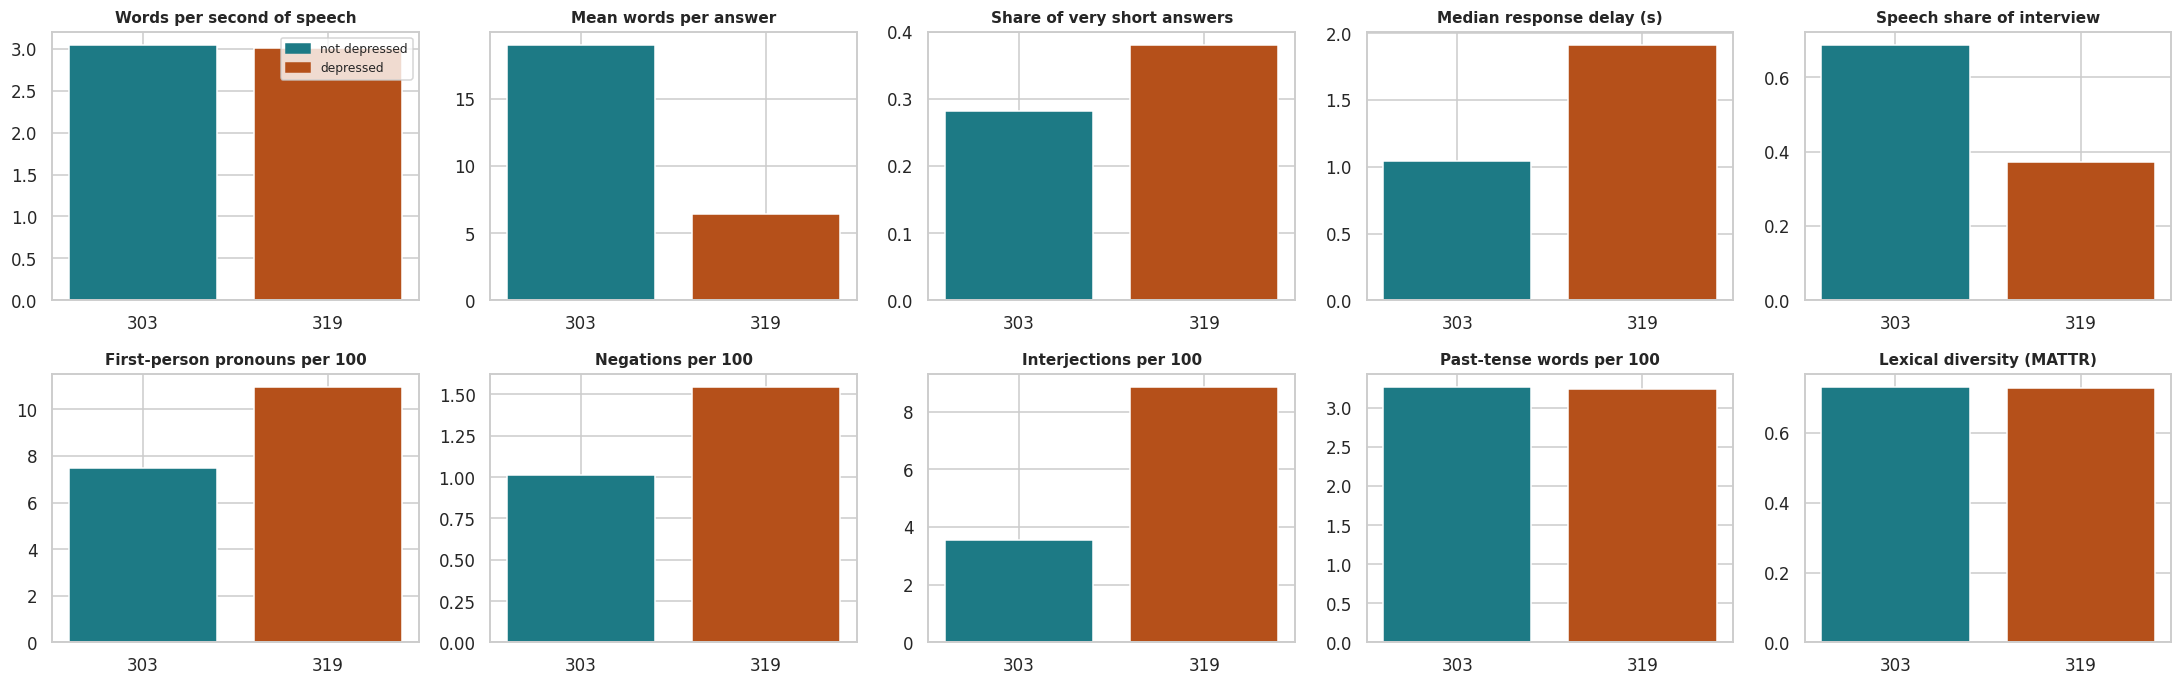

In [18]:
# BEHAVIOUR AND LANGUAGE-STRUCTURE FEATURES
require("DATA")
import spacy

MATTR_WINDOW = 50
MATTR_STRIDE = 5

try:
    nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])


def mattr(tokens, window=MATTR_WINDOW, stride=MATTR_STRIDE):
    if len(tokens) <= window:
        return len(set(tokens)) / max(len(tokens), 1)
    return float(np.mean([len(set(tokens[i:i + window])) / window for i in range(0, len(tokens) - window + 1, stride)]))


def grammar_counts(texts):
    tokens, first_person, negation, interjection, past = [], 0, 0, 0, 0
    for doc in nlp.pipe(texts, batch_size=64):
        for t in doc:
            if t.is_punct or t.is_space:
                continue
            tokens.append(t.text)
            first_person += int(t.pos_ == "PRON" and "1" in t.morph.get("Person"))
            negation += int(t.dep_ == "neg")
            interjection += int(t.pos_ == "INTJ")
            past += int("Past" in t.morph.get("Tense"))
    return tokens, first_person, negation, interjection, past


for sid, d in DATA.items():
    turns = d["turns"]
    latency = (turns["start_time"] - turns["prev_q_stop"]).clip(lower=0)
    latency = latency[latency <= LATENCY_MAX_SEC]
    speak = turns["duration"].sum()
    tokens, fp, neg, intj, past = grammar_counts(turns["clean"].tolist())
    n = max(len(tokens), 1)
    FEATURES[sid].update({
        "beh_words_per_second": turns["n_words"].sum() / max(speak, 1e-6),
        "beh_mean_turn_words": turns["n_words"].mean(),
        "beh_short_answer_share": (turns["n_words"] <= SHORT_TURN_WORDS).mean(),
        "beh_median_response_delay_sec": latency.median(),
        "beh_speech_share_of_interview": speak / (d["transcript"]["stop_time"].max() - d["transcript"]["start_time"].min()),
        "beh_first_person_per_100": 100 * fp / n,
        "beh_negation_per_100": 100 * neg / n,
        "beh_interjection_per_100": 100 * intj / n,
        "beh_past_tense_per_100": 100 * past / n,
        "beh_lexical_diversity": mattr([w.lower() for w in tokens]),
    })

BEH_COLS = ["beh_words_per_second", "beh_mean_turn_words", "beh_short_answer_share", "beh_median_response_delay_sec",
            "beh_speech_share_of_interview", "beh_first_person_per_100", "beh_negation_per_100",
            "beh_interjection_per_100", "beh_past_tense_per_100", "beh_lexical_diversity"]
display(feature_table()[["label"] + BEH_COLS].round(3).T)


@figure("01_behaviour")
def _fig_behaviour():
    grouped_bars(feature_table(), BEH_COLS, ncols=5, titles={
        "beh_words_per_second": "Words per second of speech", "beh_mean_turn_words": "Mean words per answer",
        "beh_short_answer_share": "Share of very short answers", "beh_median_response_delay_sec": "Median response delay (s)",
        "beh_speech_share_of_interview": "Speech share of interview", "beh_first_person_per_100": "First-person pronouns per 100",
        "beh_negation_per_100": "Negations per 100", "beh_interjection_per_100": "Interjections per 100",
        "beh_past_tense_per_100": "Past-tense words per 100", "beh_lexical_diversity": "Lexical diversity (MATTR)"})


FIG_FUNCS["01_behaviour"]()

## 3.2 Every question Ellie asks, with the answer, ranked by PHQ-8 relevance
Each question is matched to the closest PHQ-8 item (or to "small talk") by a zero-shot language model. Nothing is searched by keyword, so a rephrased question is still found. The table shows the best-matching questions per item, per session, and the question counts show which questions are scripted across sessions.

In [19]:
# QUESTION AND ANSWER PAIRS, MATCHED TO PHQ-8 ITEMS BY A LANGUAGE MODEL
require("DATA", "PHQ8_ITEMS")
import torch
from transformers import pipeline

QUESTION_MIN_WORDS = 4
QA_PER_ITEM = 2
zs_q = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=0 if torch.cuda.is_available() else -1)
labels = list(PHQ8_ITEMS.values()) + [OTHER_LABEL]

frames = []
for sid, d in DATA.items():
    t = d["turns"].dropna(subset=["prev_question"])
    qa = (t.groupby(["prev_q_stop", "prev_question"])
           .agg(answer=("clean", " ".join), answer_words=("n_words", "sum")).reset_index())
    qa = qa[qa["prev_question"].str.split().str.len() >= QUESTION_MIN_WORDS].reset_index(drop=True)
    res = zs_q(qa["prev_question"].tolist(), candidate_labels=labels,
               hypothesis_template="This question asks about {}.", batch_size=8)
    qa["topic"] = [ITEM_BY_TEXT[r["labels"][0]] for r in res]
    qa["match"] = [r["scores"][0] for r in res]
    qa.insert(0, "session", sid)
    frames.append(qa)
QA = pd.concat(frames, ignore_index=True)

pd.set_option("display.max_colwidth", 150)
for sid in SESSIONS:
    sub = QA[(QA["session"] == sid) & (QA["topic"] != "other")]
    best = sub.sort_values("match", ascending=False).groupby("topic").head(QA_PER_ITEM).sort_values(["topic", "match"], ascending=[True, False])
    print(f"\n{sess_label(sid)}: best PHQ-8 matches ({len(sub)} of {int((QA['session'] == sid).sum())} questions matched an item)")
    display(best[["topic", "match", "prev_question", "answer"]].round(2).reset_index(drop=True))

repeated = QA.groupby("prev_question").agg(sessions=("session", "nunique"), times=("session", "size"), topic=("topic", "first"))
repeated = repeated[repeated["sessions"] > 1].sort_values("times", ascending=False)
print("\nQuestions asked in more than one session (the scripted core of the interview):")
display(repeated.head(15).reset_index())

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

... (4 outputs left out)


319 (depressed): best PHQ-8 matches (27 of 48 questions matched an item)


,topic,match,prev_question,answer
0,fatigue,0.49,what are you like when you don't sleep well,irritable cranky
1,fatigue,0.27,what were your symptoms,well you know i was always tired and not excited about things anymore and kinda lethargic you know laying around and just not feeling myself
2,low interest,0.72,what are some things you don't really like about l_a,so spread out so hard to get places
3,low interest,0.70,what do you do when you're annoyed,mm um i try to remove myself from that situation that's annoying me
4,low mood,0.53,what got you to seek help,um recognizing that there were some things in me that that were wrong
5,low mood,0.46,have you been diagnosed with depression,yes
6,self-blame,0.65,is there anything you regret,no i have many regrets too many to name and number but um you know it's you know you have the the benefit of hindsight and yeah i have a lot of re...
7,self-blame,0.40,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself



Questions asked in more than one session (the scripted core of the interview):


,prev_question,sessions,times,topic
0,what's the hardest thing about being a parent,2,3,self-blame
1,have you been diagnosed with depression,2,2,low mood
2,have you ever served in the military,2,2,self-blame
3,how are you at controlling your temper,2,2,self-blame
4,do you find it easy to be a parent,2,2,low interest
5,how did you feel in that moment,2,2,other
6,tell me more about that,2,2,other
7,what advice would you give yourself ten or twenty years ago,2,2,other
8,thanks for sharing your thoughts with me,2,2,low mood
9,what are some things you really like about l_a,2,2,other


## 3.3 Text chunks for the classifiers
Participant speech only, cut into fixed-length windows, with the same cleaning as your training text.

In [20]:
# PARTICIPANT TEXT CHUNKS
require("DATA")
rows = []
for sid, d in DATA.items():
    words, times = [], []
    for _, r in d["turns"].iterrows():
        for w in normalise(r["clean"]).split():
            words.append(w)
            times.append(r["start_time"])
    k = 0
    for s in range(0, len(words), CHUNK_WORDS):
        piece = words[s:s + CHUNK_WORDS]
        if len(piece) < MIN_CHUNK_WORDS:
            continue
        rows.append({"session": sid, "chunk": k, "start_sec": times[s], "text": " ".join(piece)})
        k += 1
CHUNKS = pd.DataFrame(rows)
display(CHUNKS.groupby("session").agg(chunks=("chunk", "size"), first_sec=("start_sec", "min"), last_sec=("start_sec", "max")).round(0))

,chunks,first_sec,last_sec
session,,,
303,33,51.0,931.0
319,12,71.0,611.0


# 4. Text analysis
Three views, none with a hand-written lexicon: the tone of each answer (a sentiment model), the words and phrases that set each session apart (a statistical comparison), and PHQ-8 symptom evidence (zero-shot, with the answers that triggered it shown for reading).

## 4.1 Tone of each answer
One RoBERTa sentiment score per answer, nothing truncated, stop words kept. Shares are counted on the model's own label, so neutral is never counted as positive.

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

... (5 outputs left out)

,start_time,tone,prev_question,clean
69,723.64,-0.85,how hard is that,it's very frustrating because it's like i'm talking to a wall and she's not hearing me and i'm like it seem like it's taking forever for her to ch...
77,816.81,-0.83,what are you like when you don't sleep well,what am i like irritated tired um lazy
12,173.24,-0.77,do you consider yourself an introvert,what do you mean i'm sorry



319 (depressed): most negative answers


,start_time,tone,prev_question,clean
97,586.40,-0.89,is there anything you regret,no i have many regrets too many to name and number
23,193.28,-0.82,what do you do when you're annoyed,um i try to remove myself from that situation that's annoying me
59,384.57,-0.81,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself


,label,text_tone_mean,text_tone_word_weighted,text_negative_turn_share,text_neutral_turn_share,text_positive_turn_share,text_most_negative_tone
session,,,,,,,
303,0,0.131,0.194,0.162,0.541,0.297,-0.855
319,1,0.045,0.033,0.262,0.492,0.246,-0.894


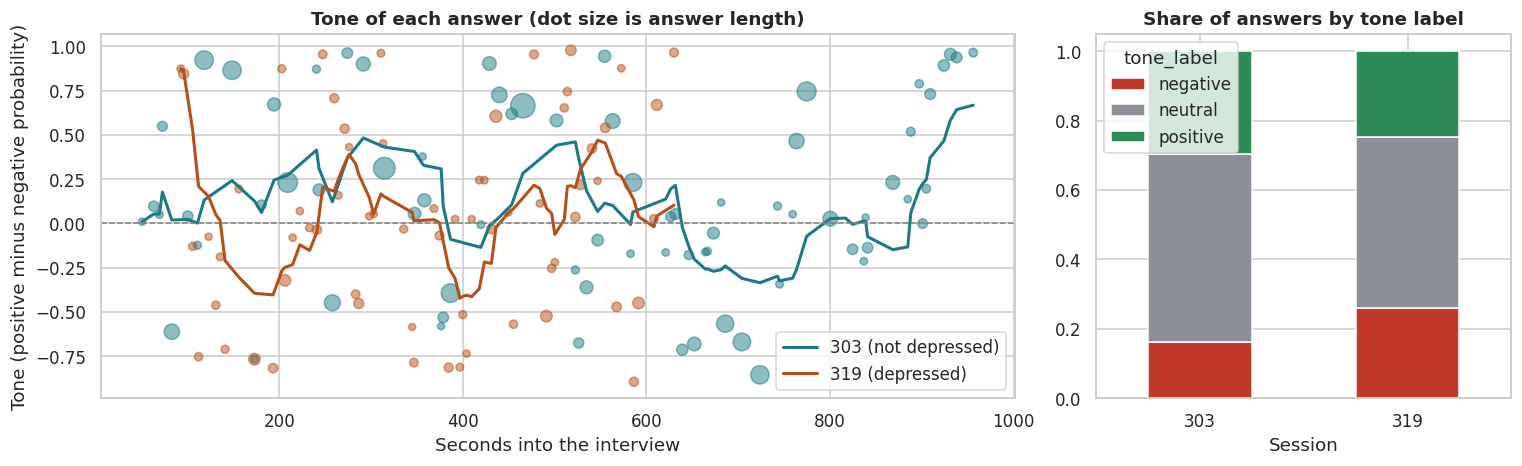

In [21]:
# TONE PER ANSWER
require("DATA")
import torch
from transformers import pipeline

HF_DEVICE = 0 if torch.cuda.is_available() else -1
tone_pipe = pipeline("text-classification", model="cardiffnlp/twitter-roberta-base-sentiment-latest", top_k=None, device=HF_DEVICE)

TURN_TONE = {}
for sid, d in DATA.items():
    t = d["turns"][d["turns"]["n_words"] >= TONE_MIN_WORDS].copy()
    outs = tone_pipe(t["clean"].tolist(), batch_size=16, truncation=True, max_length=256)
    probs = pd.DataFrame([{o["label"].lower(): o["score"] for o in out} for out in outs], index=t.index)
    t = t.join(probs[["negative", "neutral", "positive"]])
    t["tone"] = t["positive"] - t["negative"]
    t["tone_label"] = probs[["negative", "neutral", "positive"]].idxmax(axis=1)
    TURN_TONE[sid] = t
    FEATURES[sid].update({
        "text_tone_mean": t["tone"].mean(),
        "text_tone_word_weighted": np.average(t["tone"], weights=t["n_words"]),
        "text_negative_turn_share": (t["tone_label"] == "negative").mean(),
        "text_neutral_turn_share": (t["tone_label"] == "neutral").mean(),
        "text_positive_turn_share": (t["tone_label"] == "positive").mean(),
        "text_most_negative_tone": t["tone"].min(),
    })
    print(f"\n{sess_label(sid)}: most negative answers")
    display(t.nsmallest(3, "tone")[["start_time", "tone", "prev_question", "clean"]].round(2))

TEXT_COLS = ["text_tone_mean", "text_tone_word_weighted", "text_negative_turn_share", "text_neutral_turn_share",
             "text_positive_turn_share", "text_most_negative_tone"]
display(feature_table()[["label"] + TEXT_COLS].round(3))


@figure("02_tone")
def _fig_tone():
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2.2, 1]})
    for sid, t in TURN_TONE.items():
        c = LABEL_COLORS[SESSIONS[sid]]
        axes[0].scatter(t["start_time"], t["tone"], s=14 + 2 * t["n_words"], alpha=0.5, color=c)
        axes[0].plot(t["start_time"], t["tone"].rolling(7, min_periods=1).mean(), color=c, lw=2, label=sess_label(sid))
    axes[0].axhline(0, color="grey", lw=1, ls="--")
    axes[0].set_xlabel("Seconds into the interview")
    axes[0].set_ylabel("Tone (positive minus negative probability)")
    axes[0].set_title("Tone of each answer (dot size is answer length)")
    axes[0].legend()
    share = pd.DataFrame({sid: t["tone_label"].value_counts(normalize=True) for sid, t in TURN_TONE.items()}).T
    share = share.reindex(columns=["negative", "neutral", "positive"]).fillna(0)
    share.index = [str(s) for s in share.index]
    share.plot(kind="bar", stacked=True, ax=axes[1], color=["#C0392B", "#8A8F98", "#2E8B57"])
    axes[1].set_title("Share of answers by tone label")
    axes[1].set_xlabel("Session")
    axes[1].tick_params(axis="x", rotation=0)


FIG_FUNCS["02_tone"]()

## 4.2 Words and phrases that set each session apart
No word list. Every word and two-word phrase is compared between a session and all other sessions with a weighted log-odds score, which discounts common words and small counts. Stop words stay in, so pronoun and negation patterns can show up on their own. With only a few sessions this describes what people talked about as much as how they felt, so read it as exploration.


303 (not depressed): terms used more here than in the other sessions


,term,z,count_here,count_in_others
0,you,2.25,117.0,23.0
1,they,1.93,17.0,0.0
2,like,1.80,33.0,4.0
3,kinda like,1.40,9.0,0.0
4,with,1.35,13.0,1.0
5,so i,1.32,8.0,0.0
6,feel,1.32,8.0,0.0
7,probably,1.32,8.0,0.0
8,what,1.32,8.0,0.0
9,go,1.32,8.0,0.0



319 (depressed): terms used more here than in the other sessions


,term,z,count_here,count_in_others
0,mm,2.94,9.0,0.0
1,about,2.62,8.0,4.0
2,that's,2.28,10.0,9.0
3,well,2.23,11.0,11.0
4,um,2.21,21.0,30.0
5,hmm,2.19,5.0,0.0
6,say,2.19,5.0,2.0
7,'em,2.08,4.0,1.0
8,i don't,2.08,4.0,1.0
9,um i,2.05,6.0,4.0


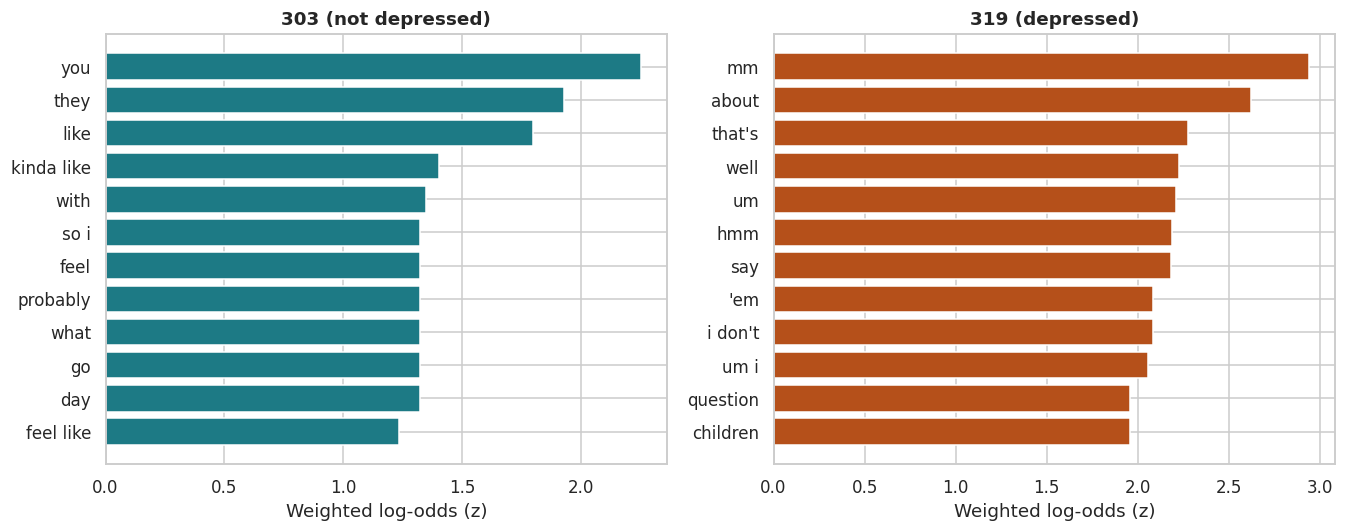

In [22]:
# DISTINCTIVE WORDS AND PHRASES PER SESSION (WEIGHTED LOG-ODDS)
require("DATA")
from sklearn.feature_extraction.text import CountVectorizer

KEYNESS_PRIOR_MASS = 500.0
KEYNESS_MIN_COUNT = 3
KEYNESS_TOP = 12

if len(DATA) < 2:
    raise RuntimeError("Distinctive wording needs at least two sessions to compare.")

sids = list(DATA)
docs = [" ".join(normalise(x) for x in DATA[s]["turns"]["clean"]) for s in sids]
cv = CountVectorizer(ngram_range=(1, 2), token_pattern=r"[a-z']+")
X = cv.fit_transform(docs).toarray().astype(float)
terms = np.array(cv.get_feature_names_out())
prior = X.sum(axis=0)
prior = prior / prior.sum() * KEYNESS_PRIOR_MASS
a0 = prior.sum()

KEYNESS = {}
for i, sid in enumerate(sids):
    a = X[i]
    b = X.sum(axis=0) - a
    la = np.log((a + prior) / (a.sum() + a0 - a - prior))
    lb = np.log((b + prior) / (b.sum() + a0 - b - prior))
    z = (la - lb) / np.sqrt(1 / (a + prior) + 1 / (b + prior))
    table = pd.DataFrame({"term": terms, "z": z, "count_here": a, "count_in_others": b})
    table = table[table["count_here"] >= KEYNESS_MIN_COUNT].sort_values("z", ascending=False)
    KEYNESS[sid] = table.head(KEYNESS_TOP).reset_index(drop=True)
    print(f"\n{sess_label(sid)}: terms used more here than in the other sessions")
    display(KEYNESS[sid].round(2))


@figure("03_keyness")
def _fig_keyness():
    fig, axes = plt.subplots(1, len(KEYNESS), figsize=(6.2 * len(KEYNESS), 5), squeeze=False)
    for ax, (sid, tbl) in zip(axes[0], KEYNESS.items()):
        tbl = tbl.iloc[::-1]
        ax.barh(tbl["term"], tbl["z"], color=LABEL_COLORS[SESSIONS[sid]])
        ax.set_title(sess_label(sid))
        ax.set_xlabel("Weighted log-odds (z)")


FIG_FUNCS["03_keyness"]()

## 4.3 PHQ-8 symptom evidence (experimental)
Each answer is scored against the eight PHQ-8 items with a zero-shot model. The scores are not calibrated, so compare the same symptom between sessions, never one symptom against another. The answers that scored highest are printed with Ellie's question so you can judge the evidence yourself.

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

,303,319
low interest,0.149,0.239
low mood,0.438,0.412
sleep problems,0.213,0.165
fatigue,0.505,0.496
appetite change,0.065,0.056
self-blame,0.479,0.497
poor concentration,0.371,0.329
slowed or restless,0.546,0.633



303 (not depressed): highest-scoring answers per symptom


,symptom,score,time,question,answer
0,low interest,1.00,817,what are you like when you don't sleep well,what am i like irritated tired um lazy
1,low interest,1.00,547,what advice would you give yourself ten or twenty years ago,rather i probably would've stayed in school and probably have a part time job or something just i just feel like um
2,low mood,1.00,547,what advice would you give yourself ten or twenty years ago,rather i probably would've stayed in school and probably have a part time job or something just i just feel like um
3,low mood,1.00,825,what are you like when you don't sleep well,feel like i wanna lay down probably go to sleep get the rest that i need but
4,sleep problems,0.99,817,what are you like when you don't sleep well,what am i like irritated tired um lazy
5,sleep problems,0.99,825,what are you like when you don't sleep well,feel like i wanna lay down probably go to sleep get the rest that i need but
6,fatigue,1.00,825,what are you like when you don't sleep well,feel like i wanna lay down probably go to sleep get the rest that i need but
7,fatigue,1.00,817,what are you like when you don't sleep well,what am i like irritated tired um lazy
8,appetite change,0.37,825,what are you like when you don't sleep well,feel like i wanna lay down probably go to sleep get the rest that i need but
9,appetite change,0.34,704,mhm,and now she's she regretting it you know 'cause she's like my mom told me this you know mom i'm doing the opposite so i guess she gotta bump her h...



319 (depressed): highest-scoring answers per symptom


,symptom,score,time,question,answer
0,low interest,0.99,385,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself
1,low interest,0.97,347,why,i don't have the funds to do that anymore
2,low mood,1.00,385,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself
3,low mood,0.98,491,could you say a little more about that,well there's been a lot going on in my life you know i just lost my parent my dad my last parent
4,sleep problems,0.76,385,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself
5,sleep problems,0.75,283,what's the hardest thing about being a parent,you worry all the time you worry for 'em
6,fatigue,0.99,112,what are some things you don't really like about l_a,so spread out so hard to get places
7,fatigue,0.99,385,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself
8,appetite change,0.33,431,can you tell me about that,well it's you know it's you know i see a psychologist and um
9,appetite change,0.20,385,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself


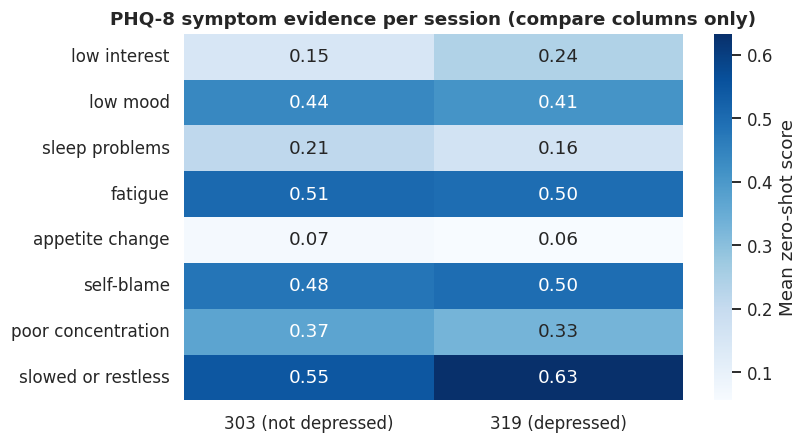

In [23]:
# ZERO-SHOT PHQ-8 SYMPTOMS PER ANSWER, WITH THE EVIDENCE
require("DATA", "PHQ8_ITEMS")
if not RUN_SYMPTOMS:
    print("RUN_SYMPTOMS is off.")
else:
    import torch
    from transformers import pipeline
    EVIDENCE_TOP = 2
    zs = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=0 if torch.cuda.is_available() else -1)
    item_texts = list(PHQ8_ITEMS.values())
    SYMPTOM_TURNS, SYMPTOM_MEANS = {}, {}
    for sid, d in DATA.items():
        t = d["turns"][d["turns"]["n_words"] >= SYMPTOM_MIN_WORDS].reset_index(drop=True)
        res = zs(t["clean"].tolist(), candidate_labels=item_texts, multi_label=True,
                 hypothesis_template="The speaker talks about {}.", batch_size=4)
        scores = pd.DataFrame([{ITEM_BY_TEXT[l]: s for l, s in zip(r["labels"], r["scores"])} for r in res])[list(PHQ8_ITEMS)]
        SYMPTOM_TURNS[sid] = pd.concat([t[["start_time", "prev_question", "clean"]], scores], axis=1)
        SYMPTOM_MEANS[sid] = scores.mean()
        for name in PHQ8_ITEMS:
            FEATURES[sid][f"text_symptom_{name.replace(' ', '_').replace('-', '_')}"] = scores[name].mean()
    SYMPTOM_TABLE = pd.DataFrame(SYMPTOM_MEANS)
    display(SYMPTOM_TABLE.round(3))

    for sid, tt in SYMPTOM_TURNS.items():
        rows = []
        for name in PHQ8_ITEMS:
            for _, r in tt.nlargest(EVIDENCE_TOP, name).iterrows():
                rows.append({"symptom": name, "score": r[name], "time": round(r["start_time"]),
                             "question": str(r["prev_question"])[:70], "answer": r["clean"][:150]})
        print(f"\n{sess_label(sid)}: highest-scoring answers per symptom")
        display(pd.DataFrame(rows).round(2))

    @figure("03_symptoms")
    def _fig_symptoms():
        T = SYMPTOM_TABLE.copy()
        T.columns = [sess_label(c) for c in T.columns]
        fig, ax = plt.subplots(figsize=(1.8 * len(T.columns) + 4, 4.2))
        sns.heatmap(T, annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar_kws={"label": "Mean zero-shot score"})
        ax.set_title("PHQ-8 symptom evidence per session (compare columns only)")

    FIG_FUNCS["03_symptoms"]()

# 5. Voice
Column names follow the AVEC documentation: F0, VUV, NAQ, QOQ, H1H2, PSP, MDQ, peakSlope, Rd, Rd_conf, then MCEP, HMPDM and HMPDD. Only participant speech is used. Frames where the file is scrubbed (all zeros) are treated as missing.

## 5.1 Voice descriptors

session,303,319
label,0.000,1.000
voice_voiced_share,0.658,0.641
voice_f0_mean_hz,192.968,103.658
voice_f0_std_hz,36.175,24.400
voice_f0_range_hz,104.500,74.500
voice_NAQ_median,0.124,0.094
voice_QOQ_median,0.471,0.286
voice_H1H2_median,6.661,-0.659
voice_PSP_median,0.234,0.160
voice_MDQ_median,0.111,0.119


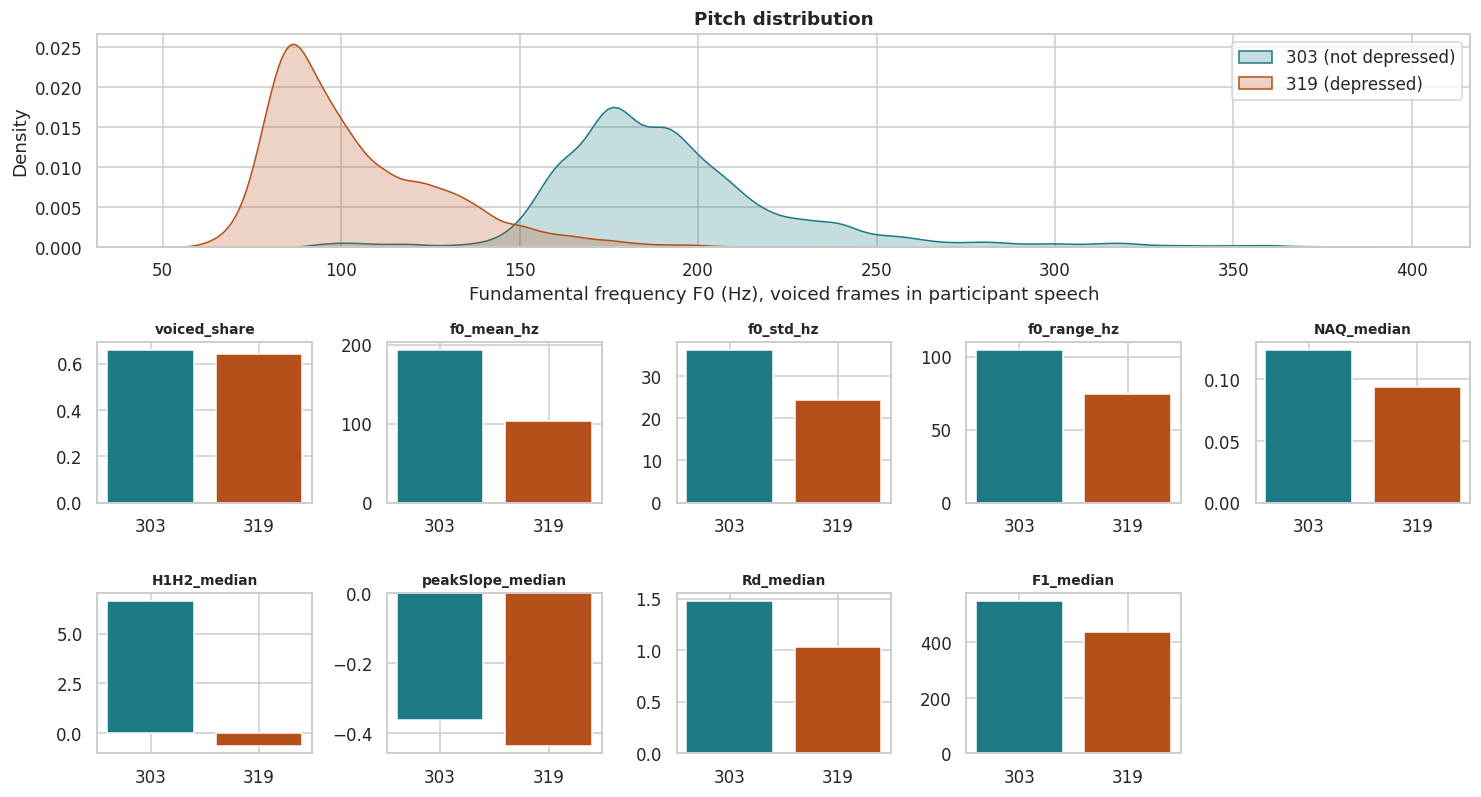

In [24]:
# COVAREP AND FORMANT DESCRIPTORS DURING PARTICIPANT SPEECH
require("DATA")
COV_NAMES = ["F0", "VUV", "NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd", "Rd_conf"]
VOICE_KEYS = ["NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd"]
VOICE = {}
for sid, d in DATA.items():
    cov = pd.read_csv(path_of(sid, "covarep"), header=None, usecols=range(len(COV_NAMES)))
    cov.columns = COV_NAMES
    fmt = pd.read_csv(path_of(sid, "formant"), header=None, names=["F1", "F2", "F3", "F4", "F5"])
    n = min(len(cov), len(fmt))
    v = pd.concat([cov.iloc[:n].reset_index(drop=True), fmt.iloc[:n].reset_index(drop=True)], axis=1)
    v["time"] = np.arange(n) * 0.01
    v = v[in_turns(v["time"], d["turns"])]
    speech_frames = len(v)
    v = v[(v["VUV"] == 1) & (v["F0"] >= F0_MIN) & (v["F0"] <= F0_MAX)].copy()
    for c in VOICE_KEYS + ["F1", "F2", "F3"]:
        v.loc[v[c] == 0, c] = np.nan
    VOICE[sid] = v
    FEATURES[sid].update({
        "voice_voiced_share": len(v) / max(speech_frames, 1),
        "voice_f0_mean_hz": v["F0"].mean(),
        "voice_f0_std_hz": v["F0"].std(),
        "voice_f0_range_hz": v["F0"].quantile(0.95) - v["F0"].quantile(0.05),
        **{f"voice_{c}_median": v[c].median() for c in VOICE_KEYS},
        **{f"voice_{c}_median": v[c].median() for c in ["F1", "F2", "F3"]},
    })

VOICE_COLS = ["voice_voiced_share", "voice_f0_mean_hz", "voice_f0_std_hz", "voice_f0_range_hz", "voice_NAQ_median",
              "voice_H1H2_median", "voice_peakSlope_median", "voice_Rd_median", "voice_F1_median"]
display(feature_table()[["label"] + [c for c in feature_table().columns if c.startswith("voice_")]].round(3).T)


@figure("04_voice")
def _fig_voice():
    fig = plt.figure(figsize=(14, 7.2))
    gs = fig.add_gridspec(2, 1, height_ratios=[1, 1.5])
    ax = fig.add_subplot(gs[0])
    for sid, v in VOICE.items():
        sns.kdeplot(v["F0"], ax=ax, color=LABEL_COLORS[SESSIONS[sid]], fill=True, alpha=0.25, label=sess_label(sid), common_norm=False)
    ax.set_xlabel("Fundamental frequency F0 (Hz), voiced frames in participant speech")
    ax.set_title("Pitch distribution")
    ax.legend()
    t = feature_table()
    cols = [c for c in VOICE_COLS if c in t.columns]
    sub = fig.add_subfigure(gs[1])
    axes = sub.subplots(2, 5)
    axes = axes.ravel()
    for a, col in zip(axes, cols):
        a.bar([str(s) for s in t.index], t[col].astype(float), color=[LABEL_COLORS[SESSIONS[s]] for s in t.index])
        a.set_title(col.replace("voice_", ""), fontsize=9)
    for a in axes[len(cols):]:
        a.axis("off")


FIG_FUNCS["04_voice"]()

## 5.2 Speech emotion (optional, slow)
The wav2vec2 model was trained on acted four-class speech. Treat its labels as a description of delivery, not as depression evidence. Turn off with `RUN_SPEECH_EMOTION = False` in Section 1.

In [25]:
# SPEECH EMOTION ON PARTICIPANT TURNS
require("DATA")
if not RUN_SPEECH_EMOTION:
    print("RUN_SPEECH_EMOTION is off.")
else:
    import torch
    from scipy.io import wavfile
    from transformers import pipeline
    emo = pipeline("audio-classification", model="superb/wav2vec2-base-superb-er", top_k=None, device=0 if torch.cuda.is_available() else -1)
    SEGMENT_SEC = 12.0
    EMOTION = {}
    for sid, d in DATA.items():
        sr, wav = wavfile.read(path_of(sid, "audio"))
        wav = wav.astype(np.float32)
        wav = wav.mean(axis=1) if wav.ndim > 1 else wav
        wav = wav / max(np.abs(wav).max(), 1.0)
        if sr != 16000:
            print(f"WARNING: sampling rate is {sr}, the model expects 16000.")
        totals, weight = Counter(), 0.0
        for _, r in d["turns"].iterrows():
            a, b = int(r["start_time"] * sr), int(r["stop_time"] * sr)
            for s in range(a, b, int(SEGMENT_SEC * sr)):
                seg = wav[s:min(s + int(SEGMENT_SEC * sr), b)]
                if len(seg) < sr or np.abs(seg).max() < 1e-4:
                    continue
                out = emo({"raw": seg, "sampling_rate": sr})
                w = len(seg) / sr
                for o in out:
                    totals[o["label"]] += o["score"] * w
                weight += w
        EMOTION[sid] = {k: v / max(weight, 1e-6) for k, v in totals.items()}
        for k, v in EMOTION[sid].items():
            FEATURES[sid][f"voice_emotion_{k}"] = v
    display(pd.DataFrame(EMOTION).round(3))

config.json:   0%|          | 0.00/2.15k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/216 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

,303,319
neu,0.261,0.334
hap,0.522,0.611
ang,0.174,0.000
sad,0.042,0.055


# 6. Face
Action units from the CLNF tracker. Frames count only when tracking succeeded with confidence above the threshold and the participant was speaking. AUs that mostly move with speech (AU10, 14, 17, 20, 25, 26) are left out.

session,303,319
label,0.000,1.000
face_AU01_r_mean,0.765,0.462
face_AU02_r_mean,0.287,0.222
face_AU04_r_mean,0.886,0.442
face_AU05_r_mean,0.289,0.258
face_AU06_r_mean,0.106,0.541
face_AU09_r_mean,0.430,0.484
face_AU12_r_mean,0.289,0.303
face_AU15_r_mean,0.172,0.143
face_smile_share,0.088,0.117


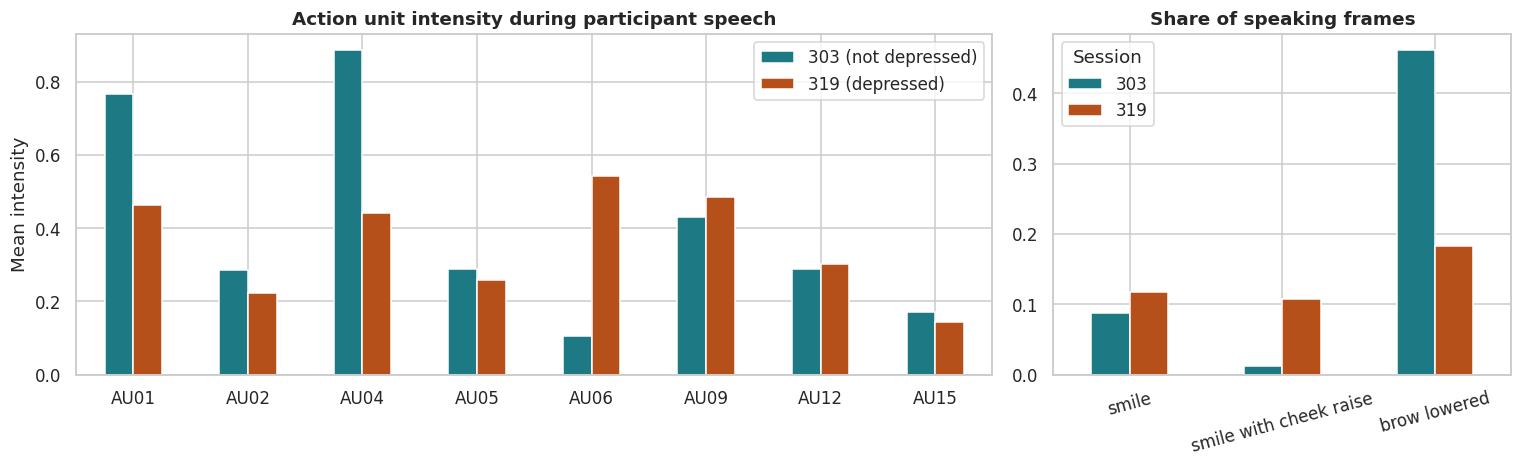

In [26]:
# ACTION UNITS DURING PARTICIPANT SPEECH
require("DATA")


def read_clnf(path):
    df = pd.read_csv(path, skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    return df


FACE = {}
for sid, d in DATA.items():
    au = read_clnf(path_of(sid, "aus"))
    speaking = in_turns(au["timestamp"], d["turns"])
    ok = (au["success"] == 1) & (au["confidence"] >= FACE_CONF_MIN) & speaking
    f = au.loc[ok, ["timestamp"] + AU_KEEP].reset_index(drop=True)
    FACE[sid] = f
    FEATURES[sid].update({f"face_{c}_mean": f[c].mean() for c in AU_KEEP})
    FEATURES[sid].update({
        "face_smile_share": (f["AU12_r"] >= AU_ON).mean(),
        "face_duchenne_share": ((f["AU12_r"] >= AU_ON) & (f["AU06_r"] >= AU_ON)).mean(),
        "face_brow_lowered_share": (f["AU04_r"] >= AU_ON).mean(),
        "face_valid_share_of_speech": ok.sum() / max(speaking.sum(), 1),
    })

FACE_COLS = [f"face_{c}_mean" for c in AU_KEEP] + ["face_smile_share", "face_duchenne_share", "face_brow_lowered_share", "face_valid_share_of_speech"]
display(feature_table()[["label"] + FACE_COLS].round(3).T)


@figure("05_face")
def _fig_face():
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2, 1]})
    mean_au = pd.DataFrame({sid: f[AU_KEEP].mean() for sid, f in FACE.items()})
    mean_au.index = [c.replace("_r", "") for c in mean_au.index]
    mean_au.columns = [sess_label(c) for c in mean_au.columns]
    mean_au.plot(kind="bar", ax=axes[0], color=[LABEL_COLORS[SESSIONS[s]] for s in FACE])
    axes[0].set_ylabel("Mean intensity")
    axes[0].set_title("Action unit intensity during participant speech")
    axes[0].tick_params(axis="x", rotation=0)
    t = feature_table()
    shares = t[["face_smile_share", "face_duchenne_share", "face_brow_lowered_share"]]
    shares.index = [str(s) for s in shares.index]
    shares.columns = ["smile", "smile with cheek raise", "brow lowered"]
    shares.T.plot(kind="bar", ax=axes[1], color=[LABEL_COLORS[SESSIONS[s]] for s in t.index])
    axes[1].set_title("Share of speaking frames")
    axes[1].tick_params(axis="x", rotation=15)
    axes[1].legend(title="Session")


FIG_FUNCS["05_face"]()

# 7. Gaze and head movement
Eye vectors become yaw and pitch angles in degrees. Head angles are unwrapped before differencing and speeds are computed only between consecutive frames, so tracker gaps and angle wrap-around do not create fake spikes.

session,303,319
label,0.000,1.000
gaze_yaw_std_deg,2.964,3.040
gaze_pitch_std_deg,2.159,5.169
gaze_frontal_share,0.982,0.207
gaze_speed_median_deg_s,33.579,30.381
head_speed_median_deg_s,21.082,14.460
head_speed_p90_deg_s,57.331,36.484
head_pitch_std_deg,3.562,8.677
head_yaw_std_deg,5.317,3.470


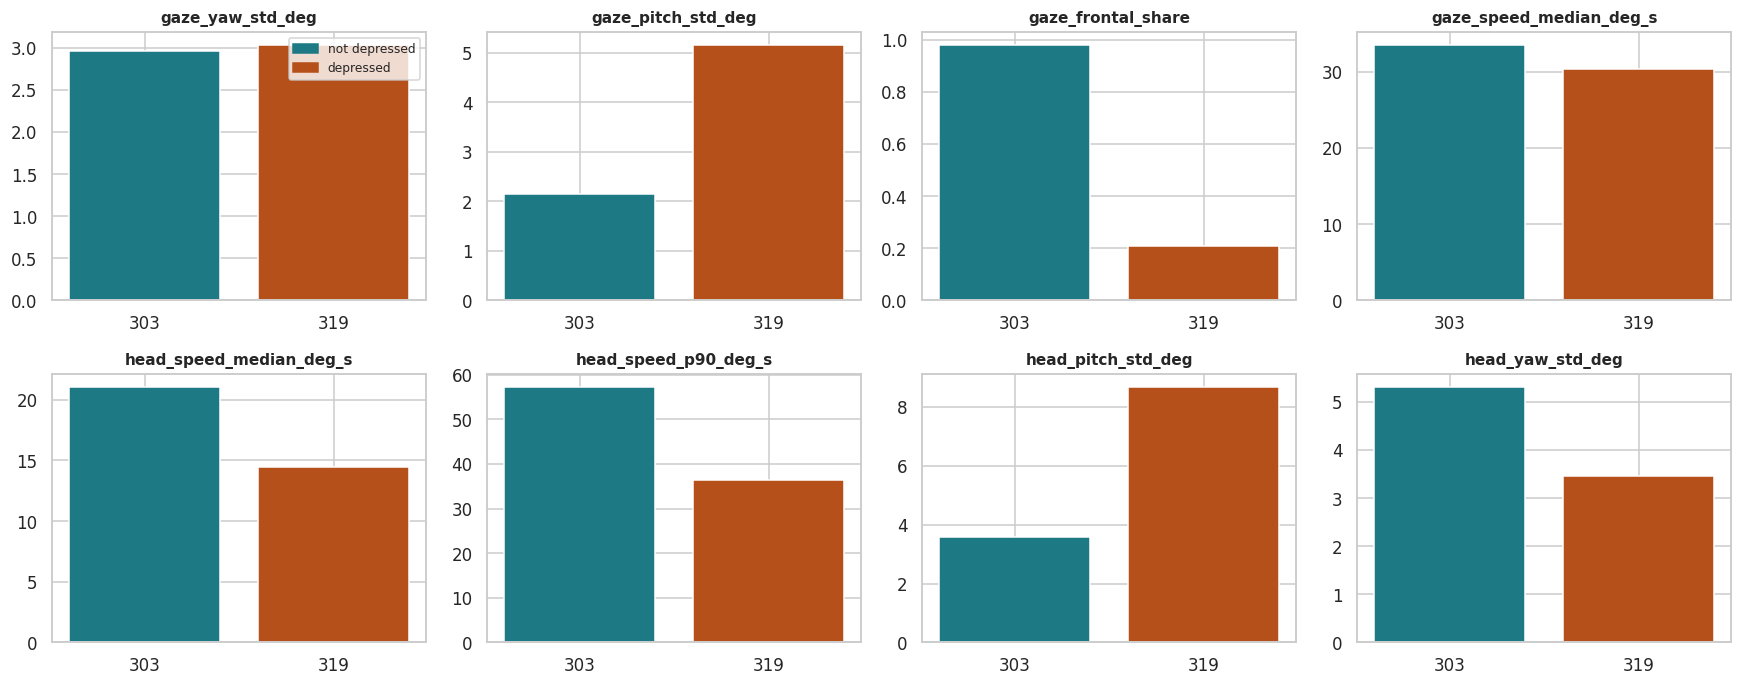

In [27]:
# GAZE AND HEAD MOTION DURING PARTICIPANT SPEECH
require("DATA")


def read_clnf(path):
    df = pd.read_csv(path, skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    return df


def speed_between_frames(time, *signals):
    dt = np.diff(time, prepend=np.nan)
    delta = np.sqrt(sum(np.diff(s, prepend=np.nan) ** 2 for s in signals))
    speed = delta / dt
    speed[~((dt > 0) & (dt <= FRAME_GAP_MAX))] = np.nan
    return speed


GAZE, HEAD = {}, {}
for sid, d in DATA.items():
    g = read_clnf(path_of(sid, "gaze"))
    g = g[(g["success"] == 1) & (g["confidence"] >= FACE_CONF_MIN)].reset_index(drop=True)
    vec = (g[["x_0", "y_0", "z_0"]].to_numpy() + g[["x_1", "y_1", "z_1"]].to_numpy()) / 2
    gz = pd.DataFrame({"time": g["timestamp"].to_numpy(),
                       "yaw": np.degrees(np.arctan2(vec[:, 0], -vec[:, 2])),
                       "pitch": np.degrees(np.arctan2(vec[:, 1], -vec[:, 2]))})
    gz["speed"] = speed_between_frames(gz["time"].to_numpy(), gz["yaw"].to_numpy(), gz["pitch"].to_numpy())
    gz = gz[in_turns(gz["time"], d["turns"])]

    p = read_clnf(path_of(sid, "pose"))
    p = p[(p["success"] == 1) & (p["confidence"] >= FACE_CONF_MIN)].reset_index(drop=True)
    ang = np.degrees(np.unwrap(p[["Rx", "Ry", "Rz"]].to_numpy(), axis=0))
    hd = pd.DataFrame({"time": p["timestamp"].to_numpy(), "pitch": ang[:, 0], "yaw": ang[:, 1], "roll": ang[:, 2]})
    hd["speed"] = speed_between_frames(hd["time"].to_numpy(), hd["pitch"].to_numpy(), hd["yaw"].to_numpy(), hd["roll"].to_numpy())
    hd = hd[in_turns(hd["time"], d["turns"])]
    GAZE[sid], HEAD[sid] = gz, hd
    FEATURES[sid].update({
        "gaze_yaw_std_deg": gz["yaw"].std(),
        "gaze_pitch_std_deg": gz["pitch"].std(),
        "gaze_frontal_share": ((gz["yaw"].abs() < FRONTAL_DEG) & (gz["pitch"].abs() < FRONTAL_DEG)).mean(),
        "gaze_speed_median_deg_s": gz["speed"].median(),
        "head_speed_median_deg_s": hd["speed"].median(),
        "head_speed_p90_deg_s": hd["speed"].quantile(0.9),
        "head_pitch_std_deg": hd["pitch"].std(),
        "head_yaw_std_deg": hd["yaw"].std(),
    })

GAZE_COLS = [c for c in feature_table().columns if c.startswith(("gaze_", "head_"))]
display(feature_table()[["label"] + GAZE_COLS].round(3).T)


@figure("06_gaze_head")
def _fig_gaze():
    t = feature_table()
    grouped_bars(t, GAZE_COLS, ncols=4)


FIG_FUNCS["06_gaze_head"]()

# 8. Fusion
Fusion here means putting the streams side by side on one timeline and in one table, in real units. No feature is standardised inside a single interview, because that removes the difference between people that you want to see. With two sessions this is description, not a statistical test.

session,303,319
label,0.000,1.000
phq8_score,0.000,13.000
beh_words_per_second,3.049,3.006
beh_mean_turn_words,19.029,6.400
beh_short_answer_share,0.282,0.381
...,...,...
gaze_speed_median_deg_s,33.579,30.381
head_speed_median_deg_s,21.082,14.460
head_speed_p90_deg_s,57.331,36.484
head_pitch_std_deg,3.562,8.677


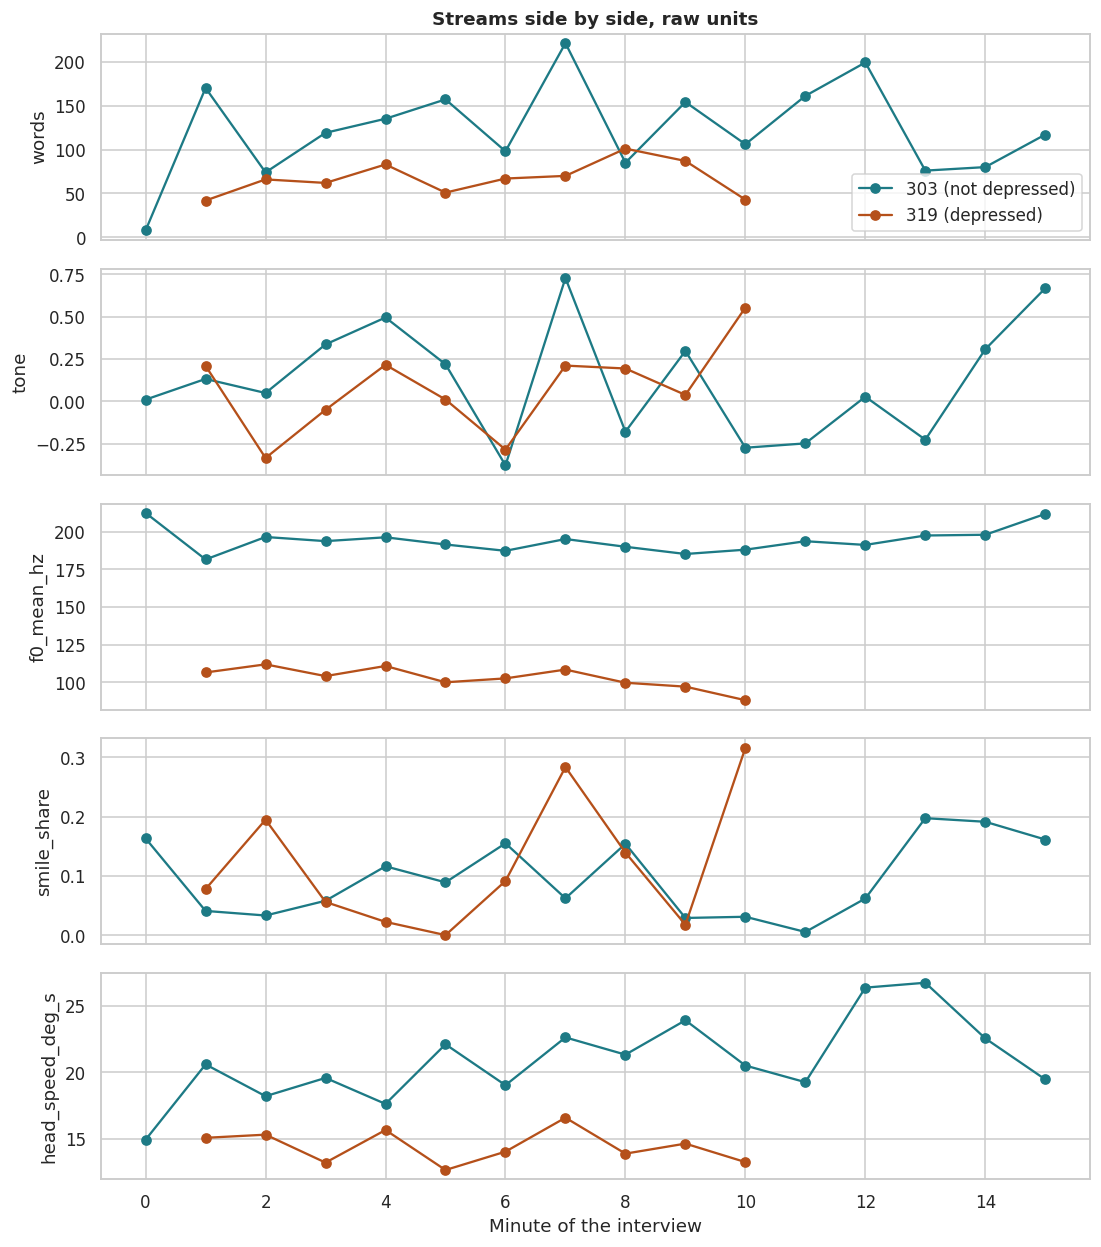

In [28]:
# PER-MINUTE TIMELINE AND ALL-SESSION FEATURE TABLE
require("DATA")
WINDOWS = {}
for sid, d in DATA.items():
    parts = {}
    parts["words"] = d["turns"].groupby((d["turns"]["start_time"] // WINDOW_SEC).astype(int))["n_words"].sum()
    if "TURN_TONE" in globals() and sid in TURN_TONE:
        t = TURN_TONE[sid]
        parts["tone"] = t.groupby((t["start_time"] // WINDOW_SEC).astype(int))["tone"].mean()
    if "VOICE" in globals() and sid in VOICE:
        v = VOICE[sid]
        parts["f0_mean_hz"] = v.groupby((v["time"] // WINDOW_SEC).astype(int))["F0"].mean()
    if "FACE" in globals() and sid in FACE:
        f = FACE[sid]
        parts["smile_share"] = (f["AU12_r"] >= AU_ON).groupby((f["timestamp"] // WINDOW_SEC).astype(int)).mean()
    if "HEAD" in globals() and sid in HEAD:
        h = HEAD[sid]
        parts["head_speed_deg_s"] = h.groupby((h["time"] // WINDOW_SEC).astype(int))["speed"].median()
    WINDOWS[sid] = pd.concat(parts, axis=1)
    WINDOWS[sid].index.name = "minute"
    # A last window that covers less than half a window is too short to compare, so it is dropped.
    end = d["transcript"]["stop_time"].max()
    last = int(end // WINDOW_SEC)
    if end - last * WINDOW_SEC < WINDOW_SEC / 2 and last in WINDOWS[sid].index:
        WINDOWS[sid] = WINDOWS[sid].drop(index=last)

ALL_FEATURES = feature_table()
display(ALL_FEATURES.round(3).T)


@figure("07_timeline")
def _fig_timeline():
    cols = [c for c in ["words", "tone", "f0_mean_hz", "smile_share", "head_speed_deg_s"] if any(c in w.columns for w in WINDOWS.values())]
    fig, axes = plt.subplots(len(cols), 1, figsize=(10, 2.3 * len(cols)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, col in zip(axes, cols):
        for sid, w in WINDOWS.items():
            if col in w.columns:
                ax.plot(w.index, w[col], marker="o", color=LABEL_COLORS[SESSIONS[sid]], label=sess_label(sid))
        ax.set_ylabel(col)
    axes[0].legend()
    axes[-1].set_xlabel("Minute of the interview")
    axes[0].set_title("Streams side by side, raw units")


FIG_FUNCS["07_timeline"]()

# 9. Cohort, labels and the 80/10/10 split
From here the notebook works on a whole cohort of DAIC-WOZ sessions, not on one participant. The unit of the label is the **session**: one PHQ-8 binary value per interview, taken from the AVEC split files. Nothing a pretrained model outputs is ever used as a label or as a training feature.

The split is done **by session**, stratified by label, so every session lands in exactly one of train, validation or test, and all three contain both classes. Sessions 303 and 319 stay outside the cohort as untouched case studies.

## 9.0 Cohort settings
Reads the sessions and label files from `TRAIN_SOURCES` in Section 1.

In [29]:
# COHORT SETTINGS FROM TRAIN_SOURCES
cohort_cfgs = [s for s in TRAIN_SOURCES if "daic_ids" in s]
if not cohort_cfgs:
    raise ValueError("Put at least one {'daic_dir': ..., 'daic_ids': [...], 'label_files': [...]} entry in TRAIN_SOURCES (Section 1).")

DAIC_DIR = Path(cohort_cfgs[0]["daic_dir"])
ZIP_DIR = Path("/content/drive/MyDrive/Multimodal_CEDS")
COHORT_IDS = sorted(set(i for s in cohort_cfgs for i in s["daic_ids"]) - set(SESSIONS))
LABEL_FILES_ALL = sorted(set(str(p) for s in cohort_cfgs for p in s["label_files"]))
NEEDED_KEYS = ["transcript", "covarep", "formant", "aus", "gaze", "pose"]


def file_of(sid, key):
    return DAIC_DIR / f"{sid}_P" / FILE_PATTERNS[key].format(sid=sid)


print("Cohort sessions:", len(COHORT_IDS), "| case-study sessions:", list(SESSIONS))

Cohort sessions: 30 | case-study sessions: [303, 319]


## 9.1 Unzip only the files this notebook needs
Skips audio, HOG and landmark files, which are most of each zip. Safe to re-run: files that already exist are left alone.

In [30]:
# SELECTIVE UNZIP FROM DRIVE TO THE COLAB DISK
require("COHORT_IDS")
import zipfile, shutil

suffixes = tuple(Path(FILE_PATTERNS[k].format(sid="0")).name[1:] for k in NEEDED_KEYS)
for sid in sorted(set(COHORT_IDS) | set(SESSIONS)):
    zpath = ZIP_DIR / f"{sid}_P.zip"
    if not zpath.exists():
        print("Missing zip:", zpath.name)
        continue
    target = DAIC_DIR / f"{sid}_P"
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zpath) as zf:
        for name in zf.namelist():
            base = Path(name).name
            if base.endswith(suffixes) and not (target / base).exists():
                with zf.open(name) as src, open(target / base, "wb") as dst:
                    shutil.copyfileobj(src, dst)
    print("Ready:", target.name, f"({len(list(target.iterdir()))} files)")

Ready: 303_P (10 files)
Ready: 319_P (10 files)
Ready: 320_P (10 files)
Ready: 321_P (10 files)
Ready: 325_P (10 files)
Ready: 330_P (10 files)
Ready: 338_P (10 files)
Ready: 339_P (10 files)
Ready: 344_P (10 files)
Ready: 345_P (10 files)
Ready: 347_P (10 files)
Ready: 348_P (10 files)
Ready: 350_P (10 files)
Ready: 351_P (10 files)
Ready: 352_P (10 files)
Ready: 353_P (10 files)
Ready: 355_P (10 files)
Ready: 457_P (10 files)
Ready: 463_P (10 files)
Ready: 464_P (10 files)
Missing zip: 468_P.zip
Missing zip: 471_P.zip
Ready: 473_P (10 files)
Missing zip: 474_P.zip
Missing zip: 475_P.zip
Missing zip: 478_P.zip
Missing zip: 479_P.zip
Ready: 485_P (10 files)
Ready: 486_P (10 files)
Ready: 487_P (11 files)
Ready: 488_P (10 files)
Ready: 491_P (10 files)


## 9.2 Labels and the stratified session split
Each cohort session is looked up in the label files. The 80/10/10 split is made inside each class separately, so train, validation and test keep the same depressed share as far as the numbers allow.

In [31]:
# LABELS AND STRATIFIED 80/10/10 SPLIT BY SESSION
require("COHORT_IDS", "file_of")
labels = pd.concat([pd.read_csv(p).rename(columns={"PHQ_Binary": "PHQ8_Binary", "PHQ_Score": "PHQ8_Score"}) for p in LABEL_FILES_ALL], ignore_index=True)
keep = [c for c in ["Participant_ID", "PHQ8_Binary", "PHQ8_Score", "Gender"] if c in labels.columns]
labels = labels[keep].drop_duplicates("Participant_ID").set_index("Participant_ID")

no_label = [i for i in COHORT_IDS if i not in labels.index]
no_files = [i for i in COHORT_IDS if i in labels.index and not all(file_of(i, k).exists() for k in NEEDED_KEYS)]
if no_label:
    print("No label found, dropped:", no_label)
if no_files:
    print("Files missing, dropped:", no_files)
COHORT = labels.loc[[i for i in COHORT_IDS if i in labels.index and i not in no_files]].copy()
COHORT["PHQ8_Binary"] = COHORT["PHQ8_Binary"].astype(int)

SPLIT_SEED = SEED
FRAC_VAL, FRAC_TEST = 0.10, 0.10


def stratified_session_split(cohort, seed=SPLIT_SEED):
    rng = np.random.default_rng(seed)
    role = {}
    for cls in (0, 1):
        ids = cohort.index[cohort["PHQ8_Binary"] == cls].to_numpy().copy()
        if len(ids) < 3:
            raise ValueError(f"Only {len(ids)} sessions have label {cls}. Each class needs at least three sessions.")
        rng.shuffle(ids)
        n_val = max(1, int(round(FRAC_VAL * len(ids))))
        n_test = max(1, int(round(FRAC_TEST * len(ids))))
        for k, i in enumerate(ids):
            role[i] = "val" if k < n_val else ("test" if k < n_val + n_test else "train")
    return pd.Series(role)


COHORT["role"] = stratified_session_split(COHORT)
assert COHORT["role"].notna().all() and not (set(COHORT.index) & set(SESSIONS))

summary = pd.crosstab(COHORT["role"], COHORT["PHQ8_Binary"]).reindex(["train", "val", "test"])
summary.columns = ["not depressed", "depressed"]
summary["sessions"] = summary.sum(axis=1)
display(summary)
if "PHQ8_Score" in COHORT.columns:
    display(COHORT.groupby("role")["PHQ8_Score"].describe().round(1).reindex(["train", "val", "test"]))
for sid, lab in SESSIONS.items():
    if sid in labels.index and int(labels.loc[sid, "PHQ8_Binary"]) != lab:
        print(f"WARNING: case session {sid} is {lab} in SESSIONS but {int(labels.loc[sid, 'PHQ8_Binary'])} in the label files.")
ROLE_OF = {**COHORT["role"].to_dict(), **{sid: "case" for sid in SESSIONS}}
LABEL_OF = {**COHORT["PHQ8_Binary"].to_dict(), **SESSIONS}

Files missing, dropped: [468, 471, 474, 475, 478, 479]


,not depressed,depressed,sessions
role,,,
train,7,11,18
val,1,2,3
test,1,2,3


,count,mean,std,min,25%,50%,75%,max
role,,,,,,,,
train,18.0,8.8,6.5,0.0,2.5,10.5,11.8,20.0
val,3.0,8.7,7.8,0.0,5.5,11.0,13.0,15.0
test,3.0,9.7,6.5,3.0,6.5,10.0,13.0,16.0


# 10. Text data and the three input representations
The data are the participant's own words, cleaned the same way for every session (lowercase, no punctuation, no stop-word removal, so negation and pronouns survive). Each session is cut into fixed windows of words. A window carries its **session's** questionnaire label, so one interview gives many training examples. Windows of one session never cross a split, and the final judgement is always made per session.

The same two recurrent models (LSTM and BiLSTM) read the text in three forms, to show what the model gets from the text alone:
1. **Raw tokens.** Word ids with an embedding layer learned from scratch.
2. **Word2Vec.** Embeddings learned by Word2Vec on the training text only, then frozen.
3. **Word2Vec with positional encoding.** The same vectors plus sinusoidal position signals, so order is explicit.

Everything that learns from text (the vocabulary, Word2Vec, the models) is fitted inside the training data of each run, never on validation, test or held-out sessions.

## 10.1 Participant text windows for every session

In [32]:
# WINDOWS OF PARTICIPANT TEXT FOR EVERY COHORT AND CASE SESSION
require("COHORT", "ROLE_OF")


def participant_windows(sid):
    tr = pd.read_csv(file_of(sid, "transcript"), sep="\t")
    tr = tr[tr["speaker"] == "Participant"].sort_values("start_time")
    words, times = [], []
    for _, r in tr.iterrows():
        for w in normalise(r["value"]).split():
            if w in ("xxx", "scrubbed_entry", "synch"):
                continue
            words.append(w)
            times.append(r["start_time"])
    rows = []
    for s in range(0, len(words), CHUNK_WORDS):
        piece = words[s:s + CHUNK_WORDS]
        if len(piece) >= MIN_CHUNK_WORDS:
            rows.append({"session": sid, "start_sec": times[s], "text": " ".join(piece)})
    return pd.DataFrame(rows)


CHUNK_TABLE = pd.concat([participant_windows(s) for s in list(COHORT.index) + list(SESSIONS)], ignore_index=True)
CHUNK_TABLE["role"] = CHUNK_TABLE["session"].map(ROLE_OF)
CHUNK_TABLE["label"] = CHUNK_TABLE["session"].map(LABEL_OF).astype(int)

TRAIN_CHUNKS = CHUNK_TABLE[CHUNK_TABLE["role"] == "train"]
VAL_CHUNKS = CHUNK_TABLE[CHUNK_TABLE["role"] == "val"]
TEST_CHUNKS = CHUNK_TABLE[CHUNK_TABLE["role"] == "test"]
overview = CHUNK_TABLE.groupby("role").agg(sessions=("session", "nunique"), windows=("text", "size"), depressed_share=("label", "mean")).reindex(["train", "val", "test", "case"])
display(overview.round(3))
assert not (set(TRAIN_CHUNKS["session"]) & set(VAL_CHUNKS["session"])) and not (set(TRAIN_CHUNKS["session"]) & set(TEST_CHUNKS["session"])) and not (set(VAL_CHUNKS["session"]) & set(TEST_CHUNKS["session"]))

,sessions,windows,depressed_share
role,,,
train,18,358,0.587
val,3,44,0.864
test,3,60,0.633
case,2,45,0.267


## 10.2 Representations and models
Defines the three representations, the two recurrent models, the training loop and a bag-of-words reference model. Nothing runs here except definitions.

In [34]:
# REPRESENTATIONS, MODELS AND TRAINING LOOP
!pip install -q gensim
require("CHUNK_TABLE")
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from gensim.models import Word2Vec
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEXT_DIM = 100
HIDDEN = 64
DROPOUT = 0.4
WEIGHT_DECAY = 1e-4
W2V_WINDOW = 5
W2V_EPOCHS = 30
MIN_COUNT = 2
MAX_EPOCHS = 25
TEXT_PATIENCE = 5
MAX_TOKENS = 80
BATCH_SIZE = 64
LEARNING_RATE = 1e-3


def build_vocab(texts):
    counts = Counter(w for t in texts for w in t.split())
    itos = ["<pad>", "<unk>"] + [w for w, c in counts.most_common() if c >= MIN_COUNT]
    return itos, {w: i for i, w in enumerate(itos)}


def word2vec_matrix(texts, itos):
    """Word2Vec fitted on the given training texts only, standardised so positional signals are comparable in size."""
    w2v = Word2Vec(sentences=[t.split() for t in texts], vector_size=TEXT_DIM, window=W2V_WINDOW, min_count=1,
                   sg=1, workers=1, seed=SEED, epochs=W2V_EPOCHS)
    m = np.zeros((len(itos), TEXT_DIM), dtype=np.float32)
    for i, w in enumerate(itos):
        if i >= 2 and w in w2v.wv:
            m[i] = w2v.wv[w]
    body = m[2:]
    m[2:] = (body - body.mean()) / (body.std() + 1e-8)
    return m, w2v


def positional_encoding(length, dim):
    pos = np.arange(length)[:, None]
    i = np.arange(dim)[None, :]
    angle = pos / np.power(10000.0, (2 * (i // 2)) / dim)
    pe = np.zeros((length, dim))
    pe[:, 0::2] = np.sin(angle[:, 0::2])
    pe[:, 1::2] = np.cos(angle[:, 1::2])
    return torch.tensor(pe, dtype=torch.float)


def encode(text, stoi):
    ids = [stoi.get(w, 1) for w in text.split()][:MAX_TOKENS]
    return ids if ids else [1]


def make_batches(texts, stoi, labels=None, shuffle=False):
    order = np.random.permutation(len(texts)) if shuffle else np.arange(len(texts))
    for s in range(0, len(order), BATCH_SIZE):
        idx = order[s:s + BATCH_SIZE]
        seqs = [encode(texts[i], stoi) for i in idx]
        lengths = torch.tensor([len(q) for q in seqs])
        x = torch.zeros(len(seqs), int(lengths.max()), dtype=torch.long)
        for r, q in enumerate(seqs):
            x[r, :len(q)] = torch.tensor(q)
        y = None if labels is None else torch.tensor([labels[i] for i in idx], dtype=torch.float)
        yield x.to(DEVICE), lengths, (None if y is None else y.to(DEVICE))


class TextRNN(nn.Module):
    """kind is raw, w2v or w2v_pe. bidirectional=False gives the LSTM, True gives the BiLSTM."""
    def __init__(self, vocab_size, kind, bidirectional, matrix=None):
        super().__init__()
        self.kind, self.bi = kind, bidirectional
        if kind == "raw":
            self.embed = nn.Embedding(vocab_size, TEXT_DIM, padding_idx=0)
        else:
            self.embed = nn.Embedding.from_pretrained(torch.tensor(matrix), freeze=True, padding_idx=0)
        if kind == "w2v_pe":
            self.register_buffer("pe", positional_encoding(MAX_TOKENS, TEXT_DIM))
        self.rnn = nn.LSTM(TEXT_DIM, HIDDEN, batch_first=True, bidirectional=bidirectional)
        self.drop = nn.Dropout(DROPOUT)
        self.fc = nn.Linear(HIDDEN * (2 if bidirectional else 1), 1)

    def forward(self, x, lengths):
        e = self.embed(x)
        if self.kind == "w2v_pe":
            e = e + self.pe[:x.size(1)].unsqueeze(0)
        packed = pack_padded_sequence(self.drop(e), lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.rnn(packed)
        feat = torch.cat([h[-2], h[-1]], dim=1) if self.bi else h[-1]
        return self.fc(self.drop(feat)).squeeze(1)


class FittedText:
    def __init__(self, model, stoi):
        self.model, self.stoi = model, stoi

    @torch.no_grad()
    def predict_proba(self, texts):
        self.model.eval()
        out = [torch.sigmoid(self.model(x, l)).cpu().numpy() for x, l, _ in make_batches(list(texts), self.stoi)]
        return np.concatenate(out)


def fit_text_model(train_df, val_df, kind, bidirectional, seed=SEED):
    """Everything learned from text (vocabulary, Word2Vec, weights) comes from train_df only. val_df only picks the stopping epoch."""
    set_seed(seed)
    itos, stoi = build_vocab(train_df["text"])
    matrix = word2vec_matrix(train_df["text"].tolist(), itos)[0] if kind != "raw" else None
    model = TextRNN(len(itos), kind, bidirectional, matrix).to(DEVICE)
    n_pos = max(int(train_df["label"].sum()), 1)
    n_neg = max(len(train_df) - n_pos, 1)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(n_neg / n_pos, device=DEVICE))
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    texts, labels = train_df["text"].tolist(), train_df["label"].tolist()
    best, state, wait, history = -1.0, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total = 0.0
        for x, lengths, y in make_batches(texts, stoi, labels, shuffle=True):
            opt.zero_grad()
            loss = loss_fn(model(x, lengths), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(y)
        val_prob = FittedText(model, stoi).predict_proba(val_df["text"])
        val_auc = roc_auc_score(val_df["label"], val_prob)
        history.append({"epoch": epoch, "train_loss": total / len(texts), "val_auc": val_auc})
        if val_auc > best:
            best, wait = val_auc, 0
            state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= TEXT_PATIENCE:
                break
    model.load_state_dict(state)
    return FittedText(model, stoi), history


class TfidfModel:
    def __init__(self, vec, clf):
        self.vec, self.clf = vec, clf

    def predict_proba(self, texts):
        return self.clf.predict_proba(self.vec.transform(list(texts)))[:, 1]


def fit_tfidf(train_df, val_df=None, **_):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    clf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000).fit(vec.fit_transform(train_df["text"]), train_df["label"])
    return TfidfModel(vec, clf), []


REPS = {"raw": "Raw tokens", "w2v": "Word2Vec", "w2v_pe": "Word2Vec + positional"}
NEURAL = {f"{REPS[k]} + {arch}": (lambda tr, va, k=k, b=b: fit_text_model(tr, va, k, b))
          for k in REPS for arch, b in [("LSTM", False), ("BiLSTM", True)]}
REFERENCE = {"TF-IDF + logistic regression (reference)": fit_tfidf}
print("Neural models:", list(NEURAL))

Neural models: ['Raw tokens + LSTM', 'Raw tokens + BiLSTM', 'Word2Vec + LSTM', 'Word2Vec + BiLSTM', 'Word2Vec + positional + LSTM', 'Word2Vec + positional + BiLSTM']


## 10.3 Look at the encoded data
What the models actually receive: the vocabulary built from training text only, and the neighbours Word2Vec learned for the most frequent content words. If the neighbours look meaningless, the embeddings carry little, which is expected with a few dozen interviews.

In [35]:
# INSPECT THE REPRESENTATIONS (TRAINING TEXT ONLY)
require("TRAIN_CHUNKS", "word2vec_matrix")
itos_demo, stoi_demo = build_vocab(TRAIN_CHUNKS["text"])
matrix_demo, w2v_demo = word2vec_matrix(TRAIN_CHUNKS["text"].tolist(), itos_demo)
print("Vocabulary size:", len(itos_demo), "| training windows:", len(TRAIN_CHUNKS))
sample = TRAIN_CHUNKS["text"].iloc[0]
print("\nRaw text   :", sample[:160])
print("Token ids  :", encode(sample, stoi_demo)[:20])
print("Vector size per token:", TEXT_DIM, "| positional encoding shape:", tuple(positional_encoding(MAX_TOKENS, TEXT_DIM).shape))
frequent = [w for w in itos_demo[2:40] if len(w) > 3][:6]
for w in frequent:
    print(f"{w:>12}:", ", ".join(x for x, _ in w2v_demo.wv.most_similar(w, topn=5)))

Vocabulary size: 1111 | training windows: 358

Raw text   : syncing yes i'm a little nervous mm this is different california yes i like the beach um the weather mm mm so many people laughter yeah what do you mean what do
Token ids  : [1, 58, 18, 6, 74, 448, 75, 96, 45, 69, 291, 58, 2, 8, 7, 227, 4, 7, 183, 75]
Vector size per token: 100 | positional encoding shape: (80, 100)
        like: tattoos, balanced, should've, completed, cage
        that: handful, waited, else, shouldn't, lows
        just: smiling, count, minute, shut, faith
        know: answer, drug, ignore, abuse, they'll
        it's: newness, wore, requires, technology, cope
      really: afraid, eeks, bothers, handful, anyone


# 11. Train and evaluate the text models
Six neural models (three representations times LSTM and BiLSTM) and one bag-of-words reference.

Each model is evaluated three ways:
- **Out-of-fold on the training sessions.** Stratified K-fold by session inside the training set. Every training session is scored by a model that never saw it. This is the main yardstick for choosing the best model, because it uses all training sessions and not the handful in validation.
- **Validation and test sessions.** Scored by a model fitted on all training sessions. Validation sessions only decide when training stops. Test sessions are never used for any decision.
- **Case sessions 303 and 319.** Scored by the same final models, reported separately.

A score for a session is the mean probability over its windows, and a session is called depressed at 0.5. Chunk-level numbers are shown too, but chunks of one session are not independent, so session-level numbers are the honest ones.

In [36]:
# FIT EVERY MODEL: OUT-OF-FOLD ON TRAIN, THEN FULL FIT FOR VAL, TEST AND CASE SESSIONS
require("CHUNK_TABLE", "NEURAL", "REFERENCE")
from sklearn.model_selection import StratifiedKFold
import time

CV_FOLDS = 5
train_sessions = COHORT.index[COHORT["role"] == "train"].to_numpy()
train_labels = COHORT.loc[train_sessions, "PHQ8_Binary"].to_numpy()
K = int(min(CV_FOLDS, np.bincount(train_labels).min()))
if K < 2:
    raise ValueError("Not enough sessions per class in the training set for cross-validation.")
skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
FOLDS = [(train_sessions[a], train_sessions[b]) for a, b in skf.split(train_sessions, train_labels)]
for k, (a, b) in enumerate(FOLDS):
    assert not (set(a) & set(b))
print("Folds:", K, "| training sessions per fold:", len(FOLDS[0][0]), "| held-out sessions per fold:", len(FOLDS[0][1]))

HISTORIES, FULL_MODELS = {}, {}


def run_config(name, fit_fn):
    start = time.time()
    col = pd.Series(np.nan, index=CHUNK_TABLE.index)
    for fit_sessions, held_sessions in FOLDS:
        fitted, _ = fit_fn(CHUNK_TABLE[CHUNK_TABLE["session"].isin(fit_sessions)], VAL_CHUNKS)
        idx = CHUNK_TABLE.index[CHUNK_TABLE["session"].isin(held_sessions)]
        col.loc[idx] = fitted.predict_proba(CHUNK_TABLE.loc[idx, "text"])
    full, hist = fit_fn(TRAIN_CHUNKS, VAL_CHUNKS)
    other = CHUNK_TABLE.index[CHUNK_TABLE["role"] != "train"]
    col.loc[other] = full.predict_proba(CHUNK_TABLE.loc[other, "text"])
    CHUNK_TABLE[name] = col
    HISTORIES[name], FULL_MODELS[name] = hist, full
    print(f"{name}: done in {time.time() - start:.0f}s, epochs run {len(hist)}")


for name, fit_fn in {**NEURAL, **REFERENCE}.items():
    run_config(name, fit_fn)

Folds: 5 | training sessions per fold: 14 | held-out sessions per fold: 4
Raw tokens + LSTM: done in 147s, epochs run 7
Raw tokens + BiLSTM: done in 122s, epochs run 25
Word2Vec + LSTM: done in 47s, epochs run 9
Word2Vec + BiLSTM: done in 57s, epochs run 11
Word2Vec + positional + LSTM: done in 51s, epochs run 16
Word2Vec + positional + BiLSTM: done in 79s, epochs run 25
TF-IDF + logistic regression (reference): done in 1s, epochs run 0


In [37]:
# EVALUATION TABLE AND SELECTION OF THE BEST TEXT MODEL
require("CHUNK_TABLE", "HISTORIES")


def eval_scores(df, col):
    y, p = df["label"].to_numpy(), df[col].to_numpy()
    s = df.groupby("session").agg(p=(col, "mean"), y=("label", "first"))
    return {"chunk_auc": roc_auc_score(y, p) if len(set(y)) > 1 else np.nan,
            "chunk_macro_f1": f1_score(y, (p >= 0.5).astype(int), average="macro"),
            "session_auc": roc_auc_score(s["y"], s["p"]) if s["y"].nunique() > 1 else np.nan,
            "session_acc": accuracy_score(s["y"], (s["p"] >= 0.5).astype(int))}


rows = []
for name in list(NEURAL) + list(REFERENCE):
    row = {"model": name}
    for role, label in [("train", "oof"), ("val", "val"), ("test", "test")]:
        res = eval_scores(CHUNK_TABLE[CHUNK_TABLE["role"] == role], name)
        row.update({f"{label}_{k}": v for k, v in res.items()})
    case = CHUNK_TABLE[CHUNK_TABLE["role"] == "case"].groupby("session")[name].mean()
    row.update({f"case_{sid}_score": case.get(sid, np.nan) for sid in SESSIONS})
    rows.append(row)
TEXT_TABLE = pd.DataFrame(rows).set_index("model")

show = ["oof_session_auc", "oof_chunk_auc", "val_session_auc", "test_session_auc", "test_session_acc", "test_chunk_auc", "test_chunk_macro_f1"] + [f"case_{s}_score" for s in SESSIONS]
display(TEXT_TABLE[show].sort_values("oof_session_auc", ascending=False).round(3))

# Selection uses only the out-of-fold score on training sessions. Test and case sessions play no part.
neural_rank = TEXT_TABLE.loc[list(NEURAL)].sort_values(["oof_session_auc", "oof_chunk_auc"], ascending=False)
BEST = neural_rank.index[0]
print("\nBest neural text model by out-of-fold session AUC:", BEST)
print("Reference TF-IDF model, same measure:", round(TEXT_TABLE.loc[list(REFERENCE)[0], "oof_session_auc"], 3))
print("Chance level for AUC is 0.5. With a few dozen sessions, differences of a few hundredths are not meaningful.")

,oof_session_auc,oof_chunk_auc,val_session_auc,test_session_auc,test_session_acc,test_chunk_auc,test_chunk_macro_f1,case_303_score,case_319_score
model,,,,,,,,,
Raw tokens + BiLSTM,0.545,0.476,0.5,0.0,0.667,0.366,0.405,0.508,0.563
Word2Vec + positional + LSTM,0.468,0.420,0.0,0.5,0.667,0.482,0.471,0.502,0.502
Raw tokens + LSTM,0.455,0.491,0.5,0.0,0.667,0.354,0.436,0.521,0.511
Word2Vec + positional + BiLSTM,0.429,0.457,0.5,1.0,1.000,0.727,0.617,0.175,0.339
Word2Vec + BiLSTM,0.364,0.442,0.0,0.5,0.333,0.488,0.513,0.467,0.512
TF-IDF + logistic regression (reference),0.325,0.393,0.5,1.0,1.000,0.758,0.642,0.485,0.516
Word2Vec + LSTM,0.273,0.415,0.0,0.0,0.333,0.415,0.433,0.491,0.493



Best neural text model by out-of-fold session AUC: Raw tokens + BiLSTM
Reference TF-IDF model, same measure: 0.325
Chance level for AUC is 0.5. With a few dozen sessions, differences of a few hundredths are not meaningful.


## 11.1 Sanity check: shuffled labels
Trains the best configuration again with the session labels shuffled among the training sessions. If it still scores well on validation and test sessions with real labels, the pipeline is finding structure that is not depression, for example the speaker or the interview length. A result near chance is what a leak-free pipeline should give.

In [38]:
# SHUFFLED-LABEL CONTROL FOR THE BEST CONFIGURATION
require("BEST", "NEURAL")
N_CONTROL = 3
vt = CHUNK_TABLE[CHUNK_TABLE["role"].isin(["val", "test"])]
sess_lab = COHORT.loc[train_sessions, "PHQ8_Binary"]
rows = []
for r in range(N_CONTROL):
    rng = np.random.default_rng(SEED + r)
    shuffled = pd.Series(rng.permutation(sess_lab.values), index=sess_lab.index)
    val_sess = VAL_CHUNKS.groupby("session")["label"].first()
    val_shuffled = pd.Series(rng.permutation(val_sess.values), index=val_sess.index)
    tr = TRAIN_CHUNKS.copy()
    tr["label"] = tr["session"].map(shuffled)
    va = VAL_CHUNKS.copy()
    va["label"] = va["session"].map(val_shuffled)
    if tr["label"].nunique() < 2 or va["label"].nunique() < 2:
        continue
    fitted, _ = NEURAL[BEST](tr, va)
    p = fitted.predict_proba(vt["text"])
    tmp = vt.assign(control=p)
    rows.append(eval_scores(tmp, "control"))
control = pd.DataFrame(rows)
real = eval_scores(vt, BEST)
print(f"Real labels, validation and test sessions together: chunk AUC {real['chunk_auc']:.3f}, session AUC {real['session_auc']:.3f}")
print("Shuffled labels, same evaluation:")
display(control.round(3))
print("Mean shuffled chunk AUC:", round(control["chunk_auc"].mean(), 3), "| mean shuffled session AUC:", round(control["session_auc"].mean(), 3))

Real labels, validation and test sessions together: chunk AUC 0.402, session AUC 0.250
Shuffled labels, same evaluation:


,chunk_auc,chunk_macro_f1,session_auc,session_acc
0,0.402,0.425,0.250,0.667
1,0.475,0.512,0.625,0.667
2,0.400,0.414,0.375,0.667


Mean shuffled chunk AUC: 0.425 | mean shuffled session AUC: 0.417


# 12. Multimodal features for every session
Numeric descriptors of behaviour, voice, face, gaze and head movement, computed the same way for every cohort and case session, during participant speech only. These come straight from the recorded signals. No pretrained model and no word list is involved. Tracker frames with low confidence, scrubbed audio and speech-driven action units are excluded.

In [39]:
# MULTIMODAL FEATURES FOR ALL SESSIONS
require("COHORT", "file_of")
COV_NAMES = ["F0", "VUV", "NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd", "Rd_conf"]
VOICE_KEYS = ["NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd"]


def read_clnf(path):
    df = pd.read_csv(path, skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    return df


def load_turns(sid):
    tr = pd.read_csv(file_of(sid, "transcript"), sep="\t")
    tr["value"] = tr["value"].fillna("").astype(str)
    tr["clean"] = (tr["value"].str.lower().str.replace(r"<[^>]*>", " ", regex=True)
                   .str.replace(r"\b(scrubbed_entry|xxx|synch)\b", " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip())
    tr["duration"] = tr["stop_time"] - tr["start_time"]
    tr["n_words"] = tr["clean"].str.split().str.len().fillna(0).astype(int)
    tr = tr.sort_values("start_time").reset_index(drop=True)
    turns = tr[(tr["speaker"] == "Participant") & (tr["n_words"] > 0)].copy()
    ellie = tr[tr["speaker"] == "Ellie"][["stop_time"]].rename(columns={"stop_time": "prev_q_stop"}).sort_values("prev_q_stop")
    turns = pd.merge_asof(turns.sort_values("start_time"), ellie, left_on="start_time", right_on="prev_q_stop", direction="backward")
    return tr, turns.reset_index(drop=True)


def mattr(tokens, window=50, stride=5):
    if len(tokens) <= window:
        return len(set(tokens)) / max(len(tokens), 1)
    return float(np.mean([len(set(tokens[i:i + window])) / window for i in range(0, len(tokens) - window + 1, stride)]))


def speed_between_frames(time, *signals):
    dt = np.diff(time, prepend=np.nan)
    delta = np.sqrt(sum(np.diff(s, prepend=np.nan) ** 2 for s in signals))
    speed = delta / dt
    speed[~((dt > 0) & (dt <= FRAME_GAP_MAX))] = np.nan
    return speed


def extract_session(sid):
    tr, turns = load_turns(sid)
    f = {}
    # behaviour from the transcript
    latency = (turns["start_time"] - turns["prev_q_stop"]).clip(lower=0)
    latency = latency[latency <= LATENCY_MAX_SEC]
    speak = turns["duration"].sum()
    tokens = re.findall(r"[a-z']+", " ".join(turns["clean"]))
    f.update({"beh_words_per_second": turns["n_words"].sum() / max(speak, 1e-6),
              "beh_mean_turn_words": turns["n_words"].mean(),
              "beh_short_answer_share": (turns["n_words"] <= SHORT_TURN_WORDS).mean(),
              "beh_median_response_delay_sec": latency.median(),
              "beh_speech_share": speak / (tr["stop_time"].max() - tr["start_time"].min()),
              "beh_lexical_diversity": mattr(tokens)})
    # voice from COVAREP and formants
    cov = pd.read_csv(file_of(sid, "covarep"), header=None, usecols=range(len(COV_NAMES)))
    cov.columns = COV_NAMES
    fmt = pd.read_csv(file_of(sid, "formant"), header=None, names=["F1", "F2", "F3", "F4", "F5"])
    n = min(len(cov), len(fmt))
    v = pd.concat([cov.iloc[:n].reset_index(drop=True), fmt.iloc[:n].reset_index(drop=True)], axis=1)
    v["time"] = np.arange(n) * 0.01
    v = v[in_turns(v["time"], turns)]
    speech_frames = len(v)
    v = v[(v["VUV"] == 1) & (v["F0"] >= F0_MIN) & (v["F0"] <= F0_MAX)].copy()
    for c in VOICE_KEYS + ["F1", "F2", "F3"]:
        v.loc[v[c] == 0, c] = np.nan
    f.update({"voice_voiced_share": len(v) / max(speech_frames, 1), "voice_f0_mean": v["F0"].mean(), "voice_f0_std": v["F0"].std(),
              "voice_f0_range": v["F0"].quantile(0.95) - v["F0"].quantile(0.05)})
    f.update({f"voice_{c}_median": v[c].median() for c in VOICE_KEYS + ["F1", "F2", "F3"]})
    # face from action units
    au = read_clnf(file_of(sid, "aus"))
    ok = (au["success"] == 1) & (au["confidence"] >= FACE_CONF_MIN) & in_turns(au["timestamp"], turns)
    fa = au.loc[ok]
    f.update({f"face_{c}_mean": fa[c].mean() for c in AU_KEEP})
    f.update({"face_smile_share": (fa["AU12_r"] >= AU_ON).mean(),
              "face_duchenne_share": ((fa["AU12_r"] >= AU_ON) & (fa["AU06_r"] >= AU_ON)).mean(),
              "face_brow_lowered_share": (fa["AU04_r"] >= AU_ON).mean()})
    # gaze and head
    g = read_clnf(file_of(sid, "gaze"))
    g = g[(g["success"] == 1) & (g["confidence"] >= FACE_CONF_MIN)].reset_index(drop=True)
    vec = (g[["x_0", "y_0", "z_0"]].to_numpy() + g[["x_1", "y_1", "z_1"]].to_numpy()) / 2
    gz = pd.DataFrame({"time": g["timestamp"].to_numpy(), "yaw": np.degrees(np.arctan2(vec[:, 0], -vec[:, 2])),
                       "pitch": np.degrees(np.arctan2(vec[:, 1], -vec[:, 2]))})
    gz["speed"] = speed_between_frames(gz["time"].to_numpy(), gz["yaw"].to_numpy(), gz["pitch"].to_numpy())
    gz = gz[in_turns(gz["time"], turns)]
    p = read_clnf(file_of(sid, "pose"))
    p = p[(p["success"] == 1) & (p["confidence"] >= FACE_CONF_MIN)].reset_index(drop=True)
    ang = np.degrees(np.unwrap(p[["Rx", "Ry", "Rz"]].to_numpy(), axis=0))
    hd = pd.DataFrame({"time": p["timestamp"].to_numpy(), "pitch": ang[:, 0], "yaw": ang[:, 1], "roll": ang[:, 2]})
    hd["speed"] = speed_between_frames(hd["time"].to_numpy(), hd["pitch"].to_numpy(), hd["yaw"].to_numpy(), hd["roll"].to_numpy())
    hd = hd[in_turns(hd["time"], turns)]
    f.update({"gaze_yaw_std": gz["yaw"].std(), "gaze_pitch_std": gz["pitch"].std(),
              "gaze_frontal_share": ((gz["yaw"].abs() < FRONTAL_DEG) & (gz["pitch"].abs() < FRONTAL_DEG)).mean(),
              "gaze_speed_median": gz["speed"].median(), "head_speed_median": hd["speed"].median(),
              "head_speed_p90": hd["speed"].quantile(0.9), "head_pitch_std": hd["pitch"].std(), "head_yaw_std": hd["yaw"].std()})
    return f


rows, failed = {}, []
for sid in list(COHORT.index) + list(SESSIONS):
    try:
        rows[sid] = extract_session(sid)
    except Exception as e:
        failed.append((sid, str(e)[:80]))
MM = pd.DataFrame(rows).T
MM.index.name = "session"
MM_COLS = list(MM.columns)
print("Sessions with features:", len(MM), "| failed:", failed if failed else "none")
print("Feature count:", len(MM_COLS), "| share of missing values:", round(float(MM.isna().mean().mean()), 4))
display(MM.groupby(MM.index.map(ROLE_OF)).median().T.round(3))

Sessions with features: 26 | failed: none
Feature count: 39 | share of missing values: 0.0


session,case,test,train,val
beh_words_per_second,3.027,3.423,3.043,3.124
beh_mean_turn_words,12.715,7.552,8.279,11.833
beh_short_answer_share,0.331,0.259,0.343,0.300
beh_median_response_delay_sec,1.477,1.830,1.455,1.343
beh_speech_share,0.531,0.463,0.512,0.505
beh_lexical_diversity,0.752,0.752,0.742,0.746
voice_voiced_share,0.650,0.636,0.660,0.680
voice_f0_mean,148.313,105.489,169.964,172.152
voice_f0_std,30.287,17.480,30.330,30.531
voice_f0_range,89.500,54.000,92.000,94.500


# 13. Fusion: text score plus the other modalities
The text score of the best model is combined with the multimodal features in a standard scikit-learn pipeline (median imputation, scaling, then logistic regression or a shallow random forest). All fitting happens inside the training sessions.

- Training sessions carry their **out-of-fold** text score, produced by a model that never saw them. Using in-sample scores here would let the fusion model trust a text score that is too good, which is the classic stacking leak.
- Validation, test and case sessions carry the score of the model fitted on all training sessions.
- Which feature set and which classifier to use is decided by repeated stratified cross-validation inside the training sessions only.
- The imputer and scaler are fitted inside each fold, never on all rows.

Ablations are included (text only, each modality alone, all modalities, text plus all) so you can see what each part adds.

In [40]:
# FUSION MODEL: CHOOSE BY CROSS-VALIDATION ON TRAIN, THEN EVALUATE ON VAL, TEST AND CASE SESSIONS
require("MM", "BEST", "CHUNK_TABLE")
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix

text_score = CHUNK_TABLE.groupby("session")[BEST].mean().rename("text_score")
FUSION = MM.join(text_score)
FUSION["label"] = FUSION.index.map(LABEL_OF)
FUSION["role"] = FUSION.index.map(ROLE_OF)

groups = {"voice": "voice_", "face": "face_", "gaze and head": ("gaze_", "head_"), "behaviour": "beh_"}
FEATURE_SETS = {"Text score only": ["text_score"]}
for g, pre in groups.items():
    FEATURE_SETS[f"{g.capitalize()} only"] = [c for c in MM_COLS if c.startswith(pre)]
FEATURE_SETS["All non-text modalities"] = list(MM_COLS)
FEATURE_SETS["Text + all modalities"] = ["text_score"] + list(MM_COLS)


def make_model(kind):
    if kind == "Logistic regression":
        clf = LogisticRegression(C=0.3, class_weight="balanced", max_iter=5000)
    else:
        clf = RandomForestClassifier(n_estimators=300, max_depth=3, min_samples_leaf=2, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("clf", clf)])


MODEL_KINDS = ["Logistic regression", "Random forest"]
train_f = FUSION[FUSION["role"] == "train"]
y_tr = train_f["label"].to_numpy().astype(int)
n_splits = int(min(5, np.bincount(y_tr).min()))
N_REPEATS = 5

rows = []
for fs_name, cols in FEATURE_SETS.items():
    for kind in MODEL_KINDS:
        aucs, f1s = [], []
        for rep in range(N_REPEATS):
            cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED + rep)
            prob = cross_val_predict(make_model(kind), train_f[cols], y_tr, cv=cv, method="predict_proba")[:, 1]
            aucs.append(roc_auc_score(y_tr, prob))
            f1s.append(f1_score(y_tr, (prob >= 0.5).astype(int), average="macro"))
        rows.append({"feature_set": fs_name, "model": kind, "n_features": len(cols), "cv_auc": np.mean(aucs), "cv_auc_sd": np.std(aucs), "cv_macro_f1": np.mean(f1s)})
FUSION_CV = pd.DataFrame(rows).sort_values("cv_auc", ascending=False).reset_index(drop=True)
display(FUSION_CV.round(3))

best_row = FUSION_CV.iloc[0]
BEST_FUSION = (best_row["feature_set"], best_row["model"])
print("\nChosen by cross-validation on training sessions only:", BEST_FUSION)

,feature_set,model,n_features,cv_auc,cv_auc_sd,cv_macro_f1
0,Behaviour only,Logistic regression,6,0.961,0.023,0.884
1,Behaviour only,Random forest,6,0.865,0.051,0.749
2,All non-text modalities,Logistic regression,39,0.699,0.086,0.579
3,Text + all modalities,Logistic regression,40,0.652,0.075,0.581
4,Gaze and head only,Logistic regression,8,0.535,0.089,0.488
5,Face only,Random forest,11,0.400,0.068,0.434
6,Text score only,Random forest,1,0.394,0.114,0.351
7,Face only,Logistic regression,11,0.369,0.033,0.424
8,Gaze and head only,Random forest,8,0.369,0.062,0.429
9,Text + all modalities,Random forest,40,0.366,0.127,0.403



Chosen by cross-validation on training sessions only: ('Behaviour only', 'Logistic regression')


In [41]:
# FINAL FUSION MODEL: FIT ON TRAIN SESSIONS, REPORT VAL, TEST AND CASE SESSIONS
require("BEST_FUSION", "FUSION")
fs_name, kind = BEST_FUSION
cols = FEATURE_SETS[fs_name]
final_model = make_model(kind).fit(train_f[cols], y_tr)

OUT = FUSION[["role", "label", "text_score"]].copy()
OUT["fusion_prob"] = final_model.predict_proba(FUSION[cols])[:, 1]
OUT["prediction"] = np.where(OUT["fusion_prob"] >= 0.5, "Depressed", "Not depressed")
OUT["actual"] = np.where(OUT["label"] == 1, "Depressed", "Not depressed")
OUT["correct"] = OUT["prediction"] == OUT["actual"]

held = OUT[OUT["role"].isin(["val", "test"])]
print(f"Fusion model: {fs_name} with {kind}")
for role in ["val", "test"]:
    sub = OUT[OUT["role"] == role]
    auc = roc_auc_score(sub["label"], sub["fusion_prob"]) if sub["label"].nunique() > 1 else np.nan
    print(f"{role}: {int(sub['correct'].sum())} of {len(sub)} sessions correct | AUC {auc:.3f}")
print("\nTraining sessions are not reported here, because the model has seen them. Their cross-validated score is in the table above.\n")
display(OUT[OUT["role"].isin(["val", "test", "case"])].sort_values(["role", "label"]).round(3))

if hasattr(final_model.named_steps["clf"], "coef_"):
    imp = pd.Series(final_model.named_steps["clf"].coef_[0], index=cols)
else:
    imp = pd.Series(final_model.named_steps["clf"].feature_importances_, index=cols)
IMPORTANCE = imp.reindex(imp.abs().sort_values(ascending=False).index)
print("\nLargest contributions (standardised features):")
display(IMPORTANCE.head(12).round(3).to_frame("weight"))

Fusion model: Behaviour only with Logistic regression
val: 3 of 3 sessions correct | AUC 1.000
test: 2 of 3 sessions correct | AUC 1.000

Training sessions are not reported here, because the model has seen them. Their cross-validated score is in the table above.



,role,label,text_score,fusion_prob,prediction,actual,correct
session,,,,,,,
303,case,0,0.508,0.861,Depressed,Not depressed,False
319,case,1,0.563,0.484,Not depressed,Depressed,False
457,test,0,0.733,0.195,Not depressed,Not depressed,True
325,test,1,0.605,0.579,Depressed,Depressed,True
347,test,1,0.703,0.318,Not depressed,Depressed,False
473,val,0,0.662,0.352,Not depressed,Not depressed,True
338,val,1,0.614,0.782,Depressed,Depressed,True
350,val,1,0.718,0.595,Depressed,Depressed,True



Largest contributions (standardised features):


,weight
beh_median_response_delay_sec,-0.872
beh_lexical_diversity,-0.484
beh_words_per_second,-0.312
beh_mean_turn_words,0.279
beh_short_answer_share,0.236
beh_speech_share,0.118


# 14. Report figures for the modelling stages
Registered here so the final cell in Section 15 can redraw them with all the earlier figures.

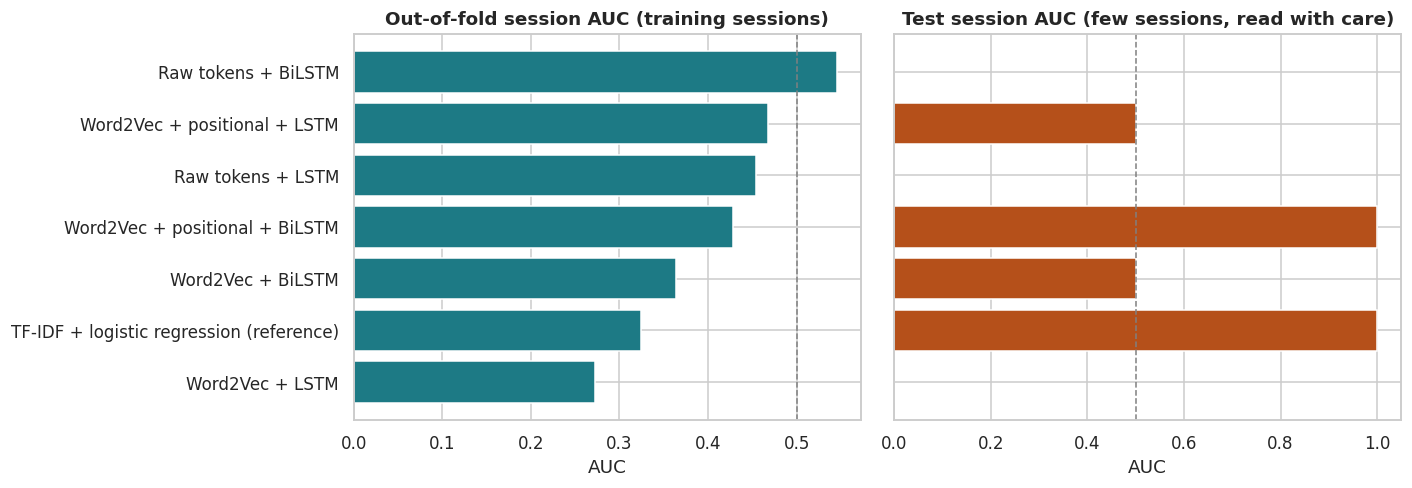

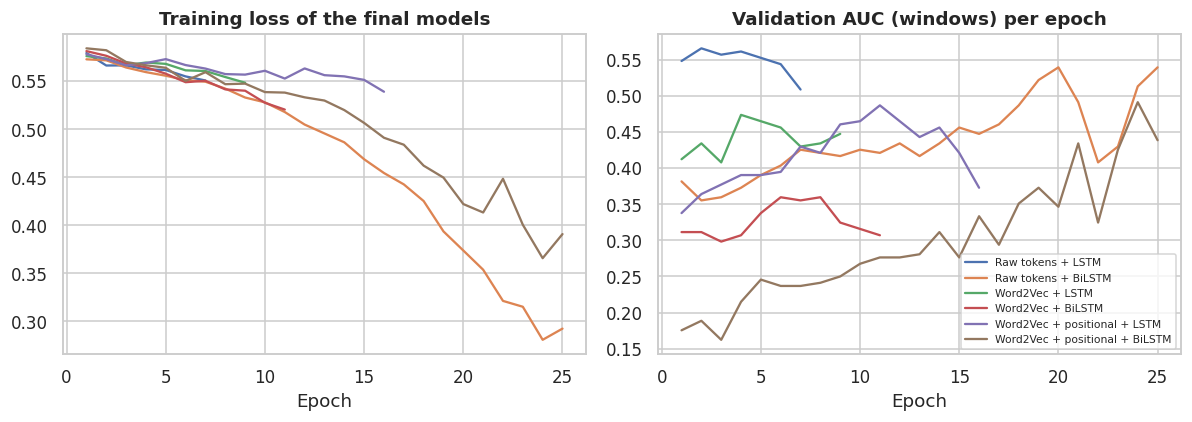

In [42]:
# REGISTER THE MODELLING FIGURES
require("TEXT_TABLE")


@figure("20_text_models")
def _fig_text_models():
    t = TEXT_TABLE.sort_values("oof_session_auc")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
    axes[0].barh(t.index, t["oof_session_auc"], color="#1D7A85")
    axes[0].axvline(0.5, color="grey", ls="--", lw=1)
    axes[0].set_title("Out-of-fold session AUC (training sessions)")
    axes[0].set_xlabel("AUC")
    axes[1].barh(t.index, t["test_session_auc"].fillna(0), color="#B5501A")
    axes[1].axvline(0.5, color="grey", ls="--", lw=1)
    axes[1].set_title("Test session AUC (few sessions, read with care)")
    axes[1].set_xlabel("AUC")


@figure("21_training_curves")
def _fig_curves():
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name in NEURAL:
        h = pd.DataFrame(HISTORIES[name])
        axes[0].plot(h["epoch"], h["train_loss"], label=name, lw=1.5)
        axes[1].plot(h["epoch"], h["val_auc"], label=name, lw=1.5)
    axes[0].set_title("Training loss of the final models")
    axes[1].set_title("Validation AUC (windows) per epoch")
    for a in axes:
        a.set_xlabel("Epoch")
    axes[1].legend(fontsize=7)


FIG_FUNCS["20_text_models"]()
FIG_FUNCS["21_training_curves"]()

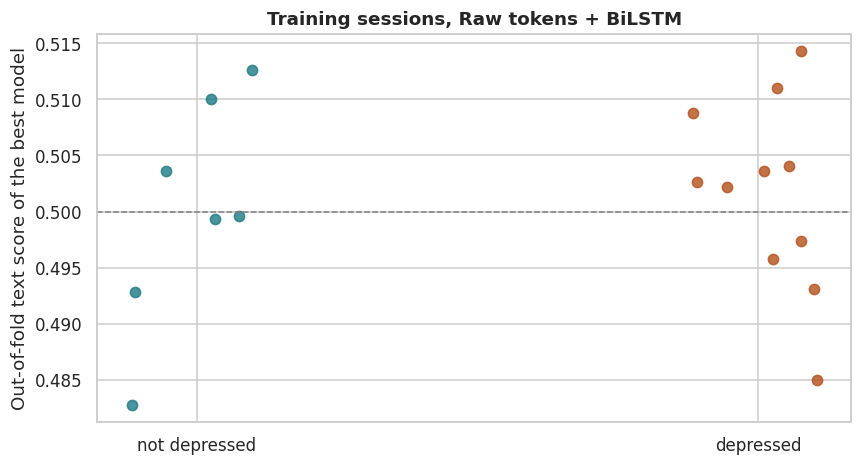

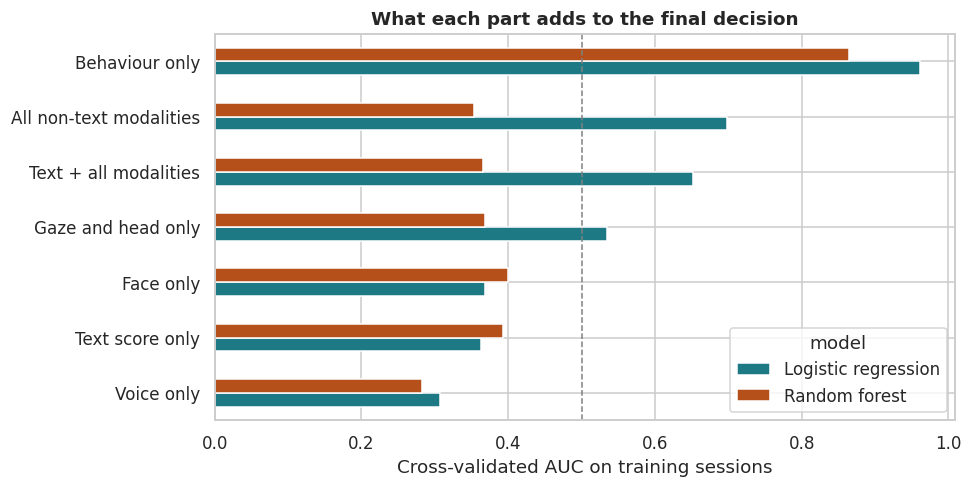

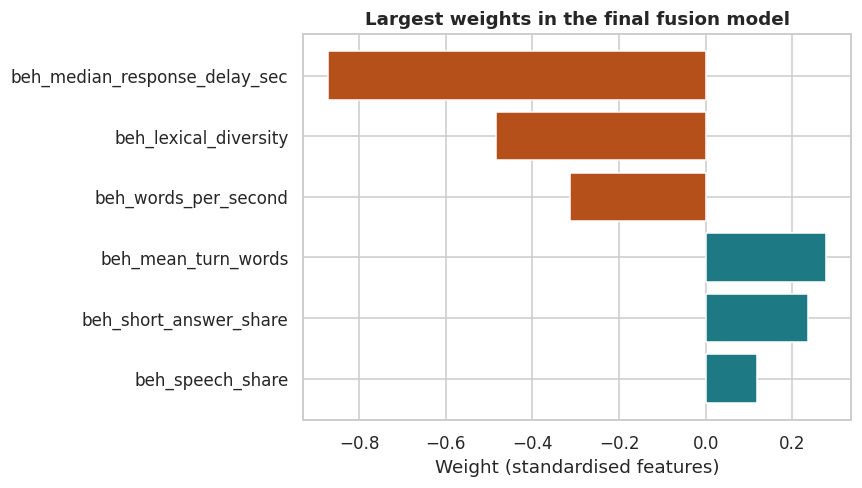

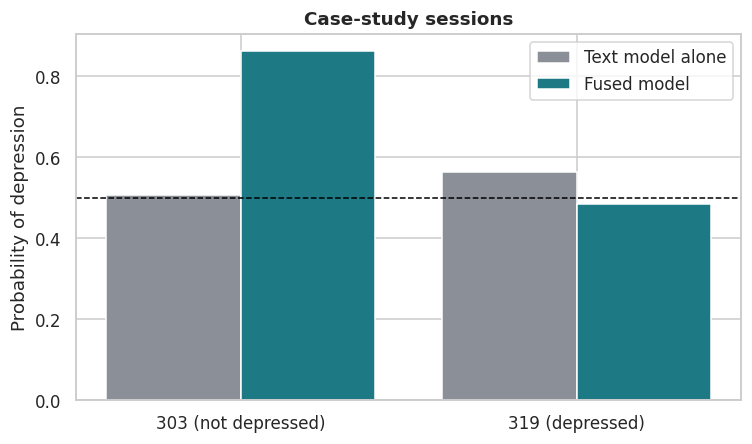

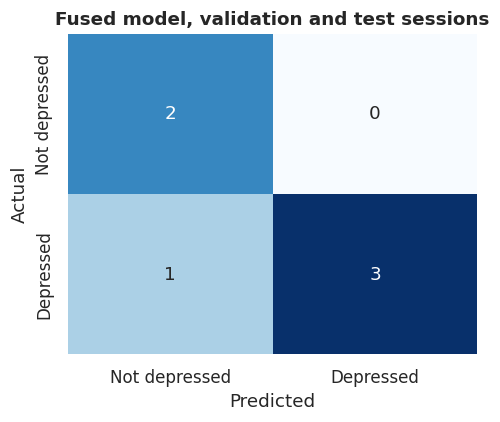

In [43]:
# REGISTER THE FUSION FIGURES
require("FUSION_CV", "OUT")


@figure("23_fusion_ablation")
def _fig_fusion_cv():
    t = FUSION_CV.pivot(index="feature_set", columns="model", values="cv_auc").reindex(FUSION_CV["feature_set"].drop_duplicates()[::-1])
    fig, ax = plt.subplots(figsize=(9, 4.6))
    t.plot(kind="barh", ax=ax, color=["#1D7A85", "#B5501A"])
    ax.axvline(0.5, color="grey", ls="--", lw=1)
    ax.set_xlabel("Cross-validated AUC on training sessions")
    ax.set_title("What each part adds to the final decision")
    ax.set_ylabel("")


@figure("24_fusion_importance")
def _fig_importance():
    imp = IMPORTANCE.head(12)[::-1]
    fig, ax = plt.subplots(figsize=(8, 4.6))
    ax.barh(imp.index, imp.values, color=["#B5501A" if v < 0 else "#1D7A85" for v in imp.values])
    ax.set_title("Largest weights in the final fusion model")
    ax.set_xlabel("Weight (standardised features)")


@figure("22_oof_scores")
def _fig_oof():
    fig, ax = plt.subplots(figsize=(8, 4.4))
    d = FUSION[FUSION["role"] == "train"]
    for lab, c in [(0, "#1D7A85"), (1, "#B5501A")]:
        v = d.loc[d["label"] == lab, "text_score"]
        ax.scatter(np.full(len(v), lab) + np.random.default_rng(0).uniform(-0.12, 0.12, len(v)), v, color=c, s=45, alpha=0.8)
    ax.axhline(0.5, color="grey", ls="--", lw=1)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["not depressed", "depressed"])
    ax.set_ylabel("Out-of-fold text score of the best model")
    ax.set_title(f"Training sessions, {BEST}")


@figure("25_case_sessions")
def _fig_cases():
    c = OUT[OUT["role"] == "case"]
    fig, ax = plt.subplots(figsize=(7, 4.2))
    x = np.arange(len(c))
    ax.bar(x - 0.2, c["text_score"], 0.4, label="Text model alone", color="#8A8F98")
    ax.bar(x + 0.2, c["fusion_prob"], 0.4, label="Fused model", color="#1D7A85")
    ax.axhline(0.5, color="black", ls="--", lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels([sess_label(s) for s in c.index])
    ax.set_ylabel("Probability of depression")
    ax.set_title("Case-study sessions")
    ax.legend()


@figure("26_confusion_heldout")
def _fig_confusion():
    h = OUT[OUT["role"].isin(["val", "test"])]
    cm = confusion_matrix(h["actual"], h["prediction"], labels=["Not depressed", "Depressed"])
    fig, ax = plt.subplots(figsize=(4.6, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["Not depressed", "Depressed"], yticklabels=["Not depressed", "Depressed"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title("Fused model, validation and test sessions")


for k in ["22_oof_scores", "23_fusion_ablation", "24_fusion_importance", "25_case_sessions", "26_confusion_heldout"]:
    FIG_FUNCS[k]()

# 15. Report figures and tables
Draws every figure from the blocks you have run, saves each as a high-resolution PNG, writes the tables as CSV and zips everything for download.

Drawing 01_behaviour


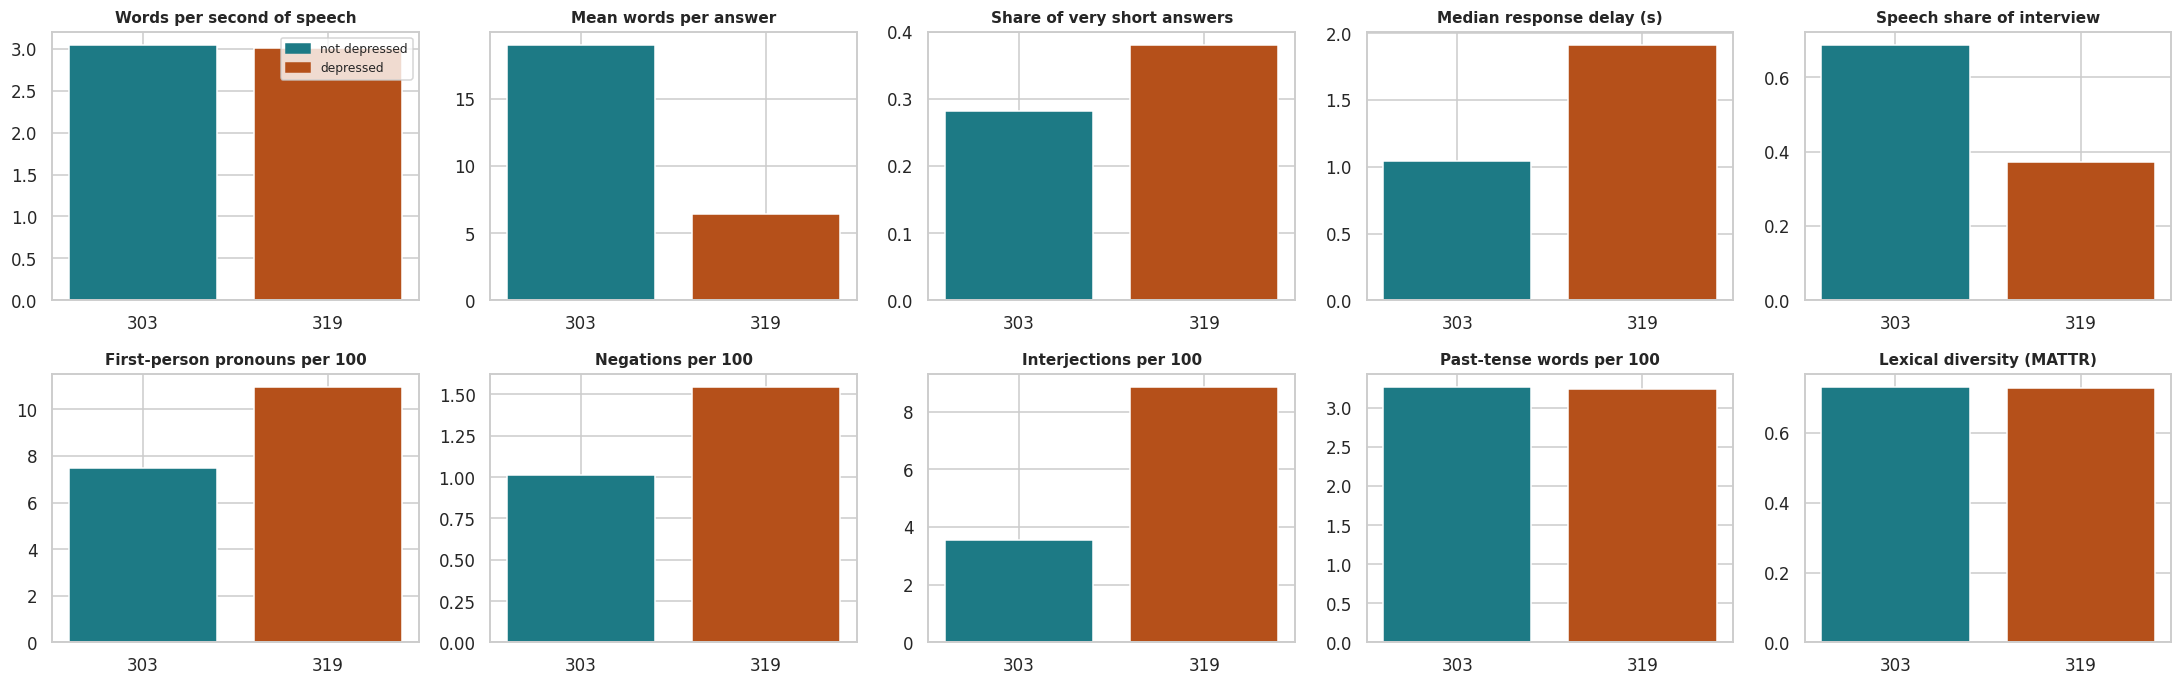

Drawing 02_tone


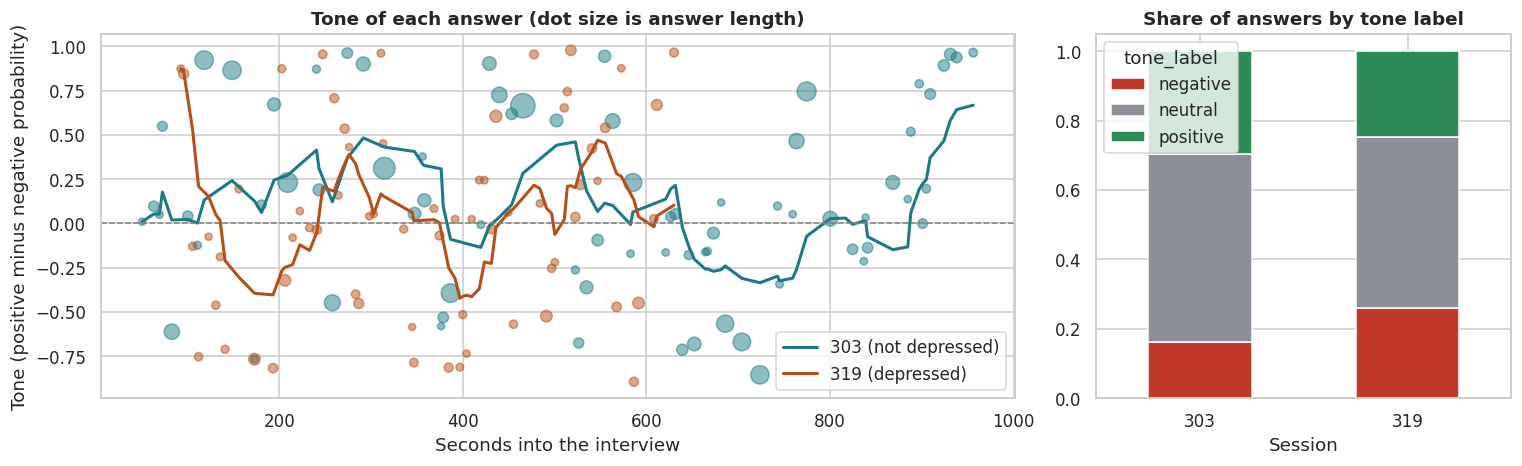

Drawing 03_keyness


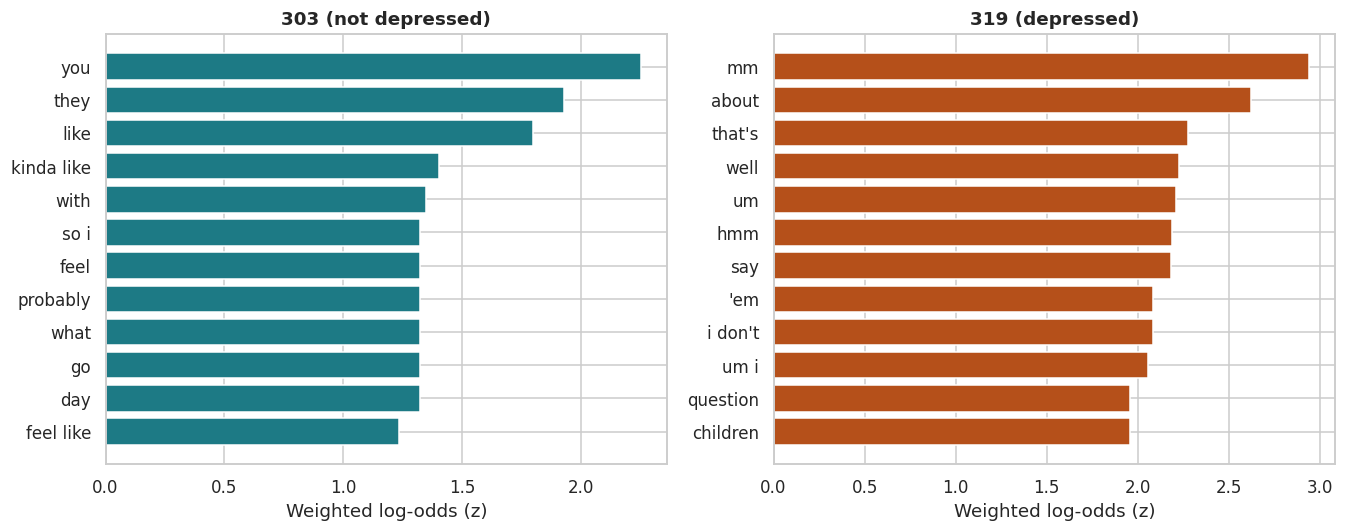

Drawing 03_symptoms


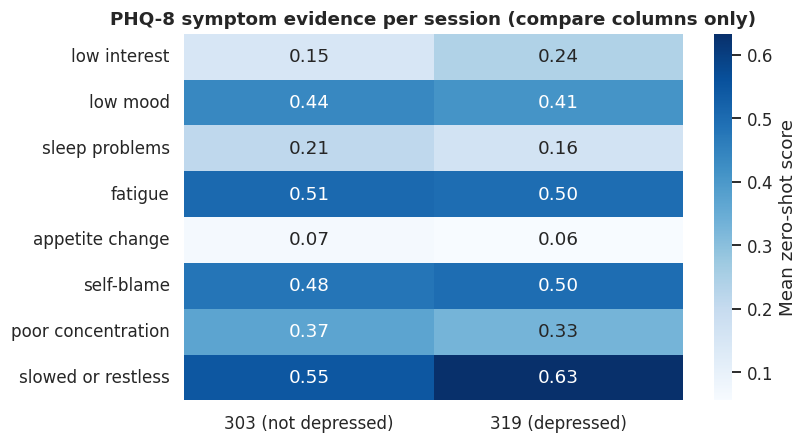

Drawing 04_voice


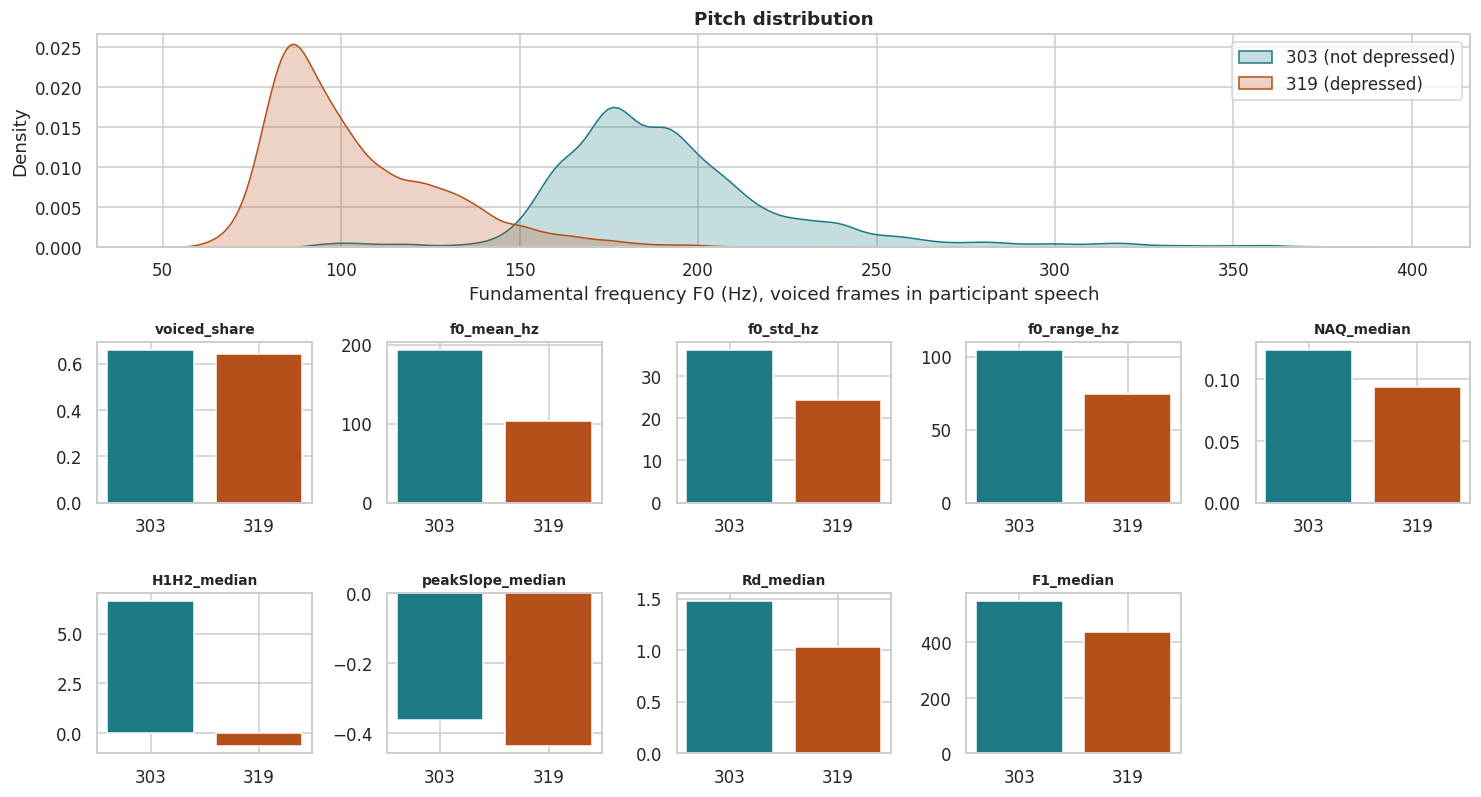

Drawing 05_face


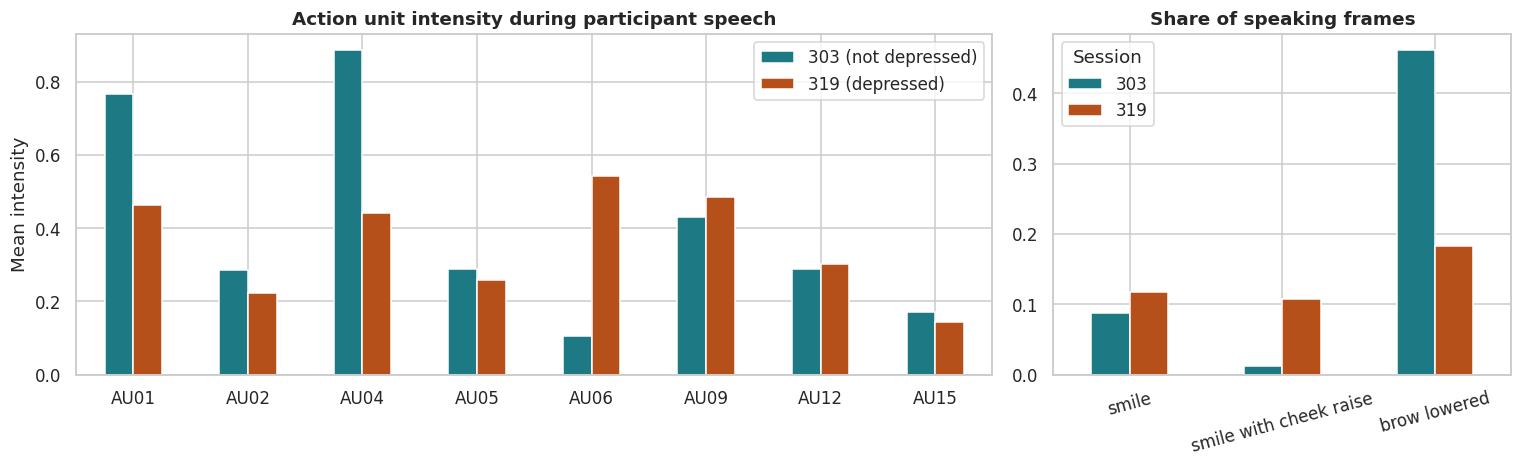

Drawing 06_gaze_head


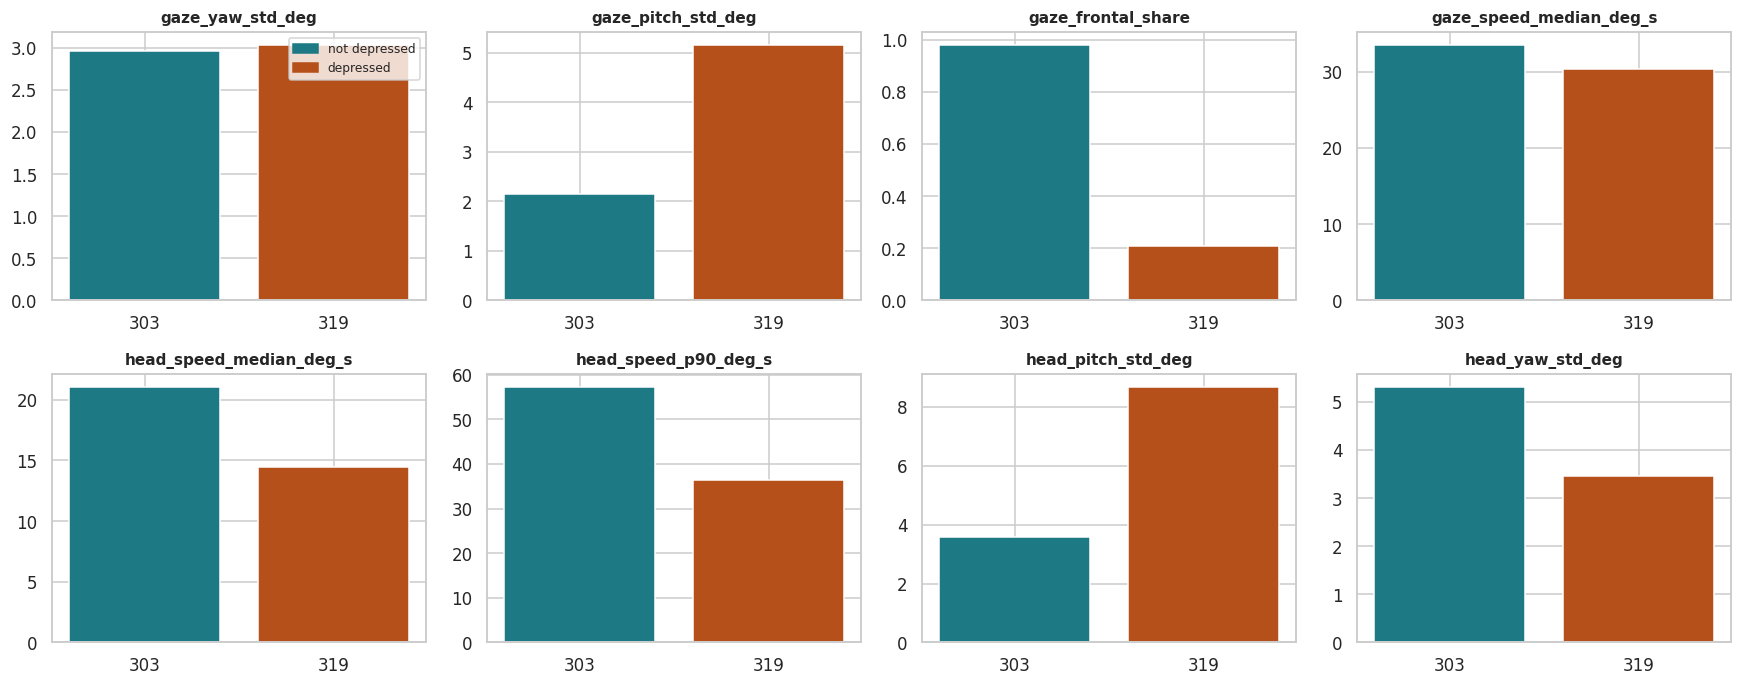

Drawing 07_timeline


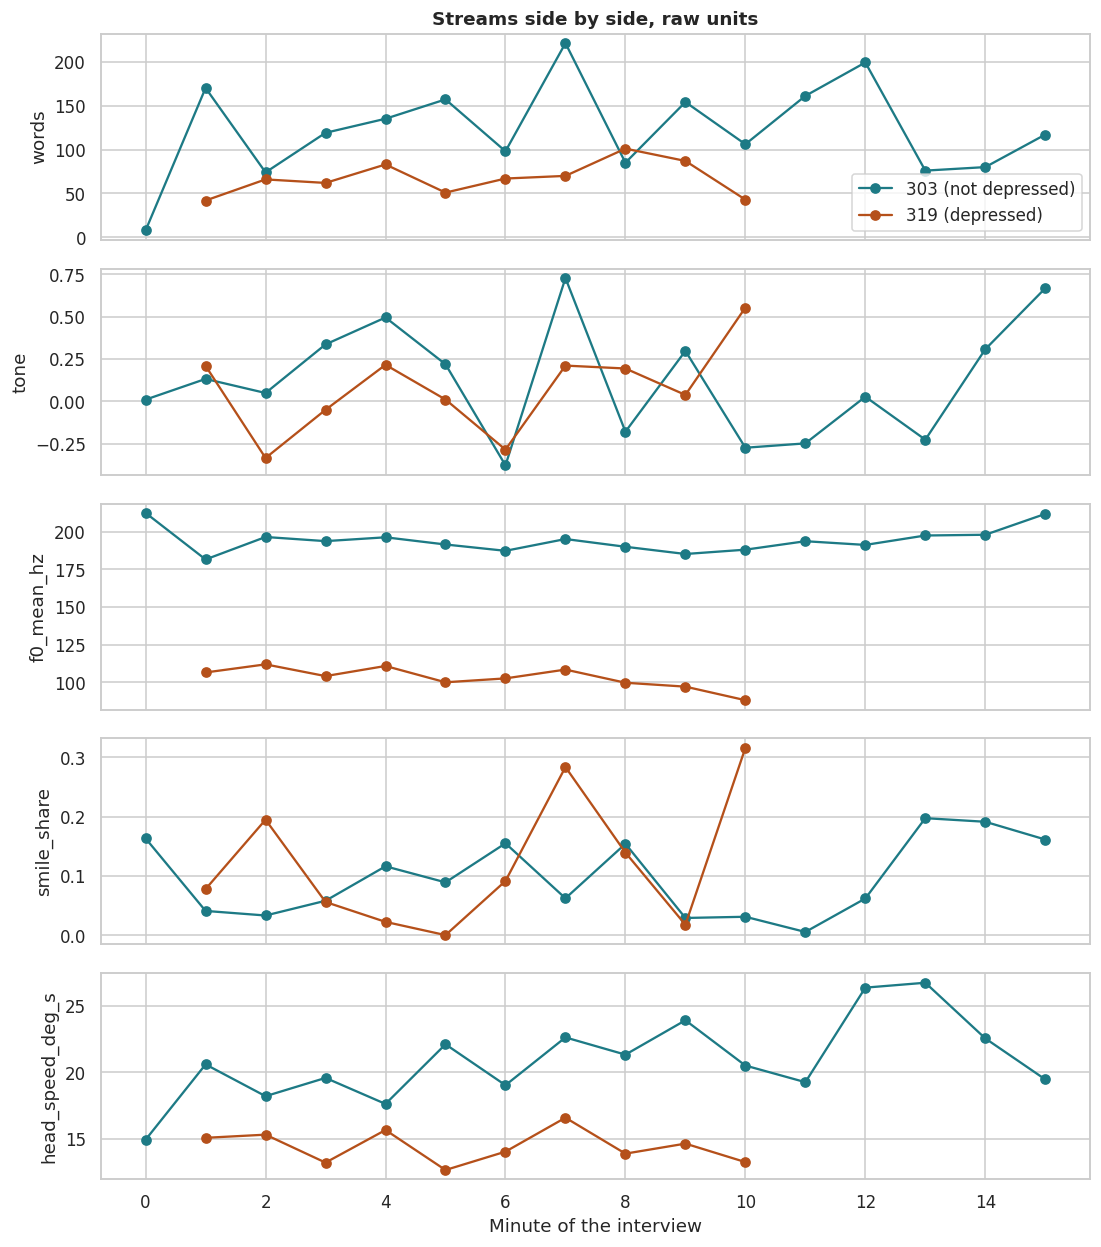

Drawing 20_text_models


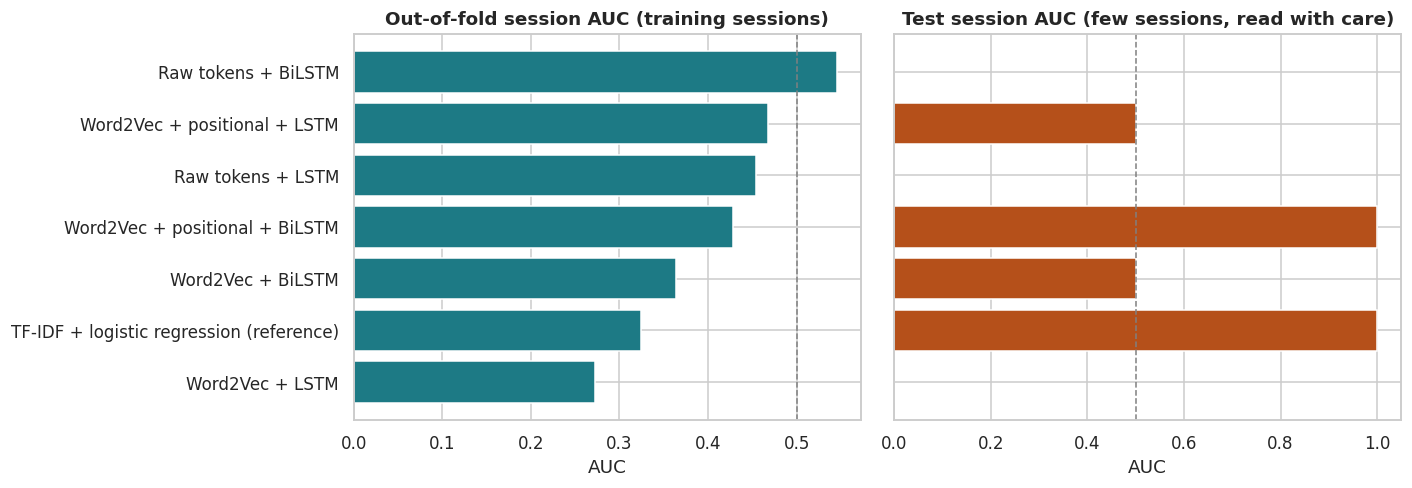

Drawing 21_training_curves


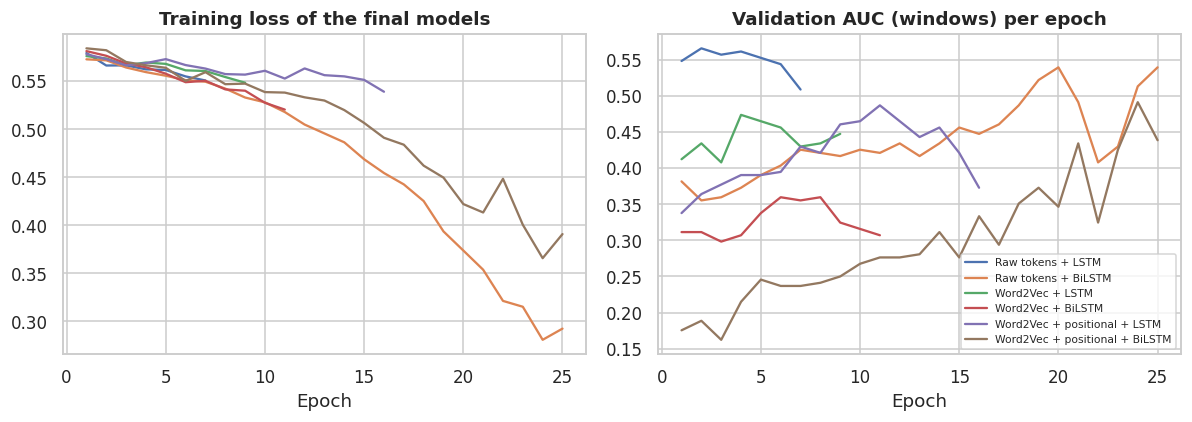

Drawing 22_oof_scores


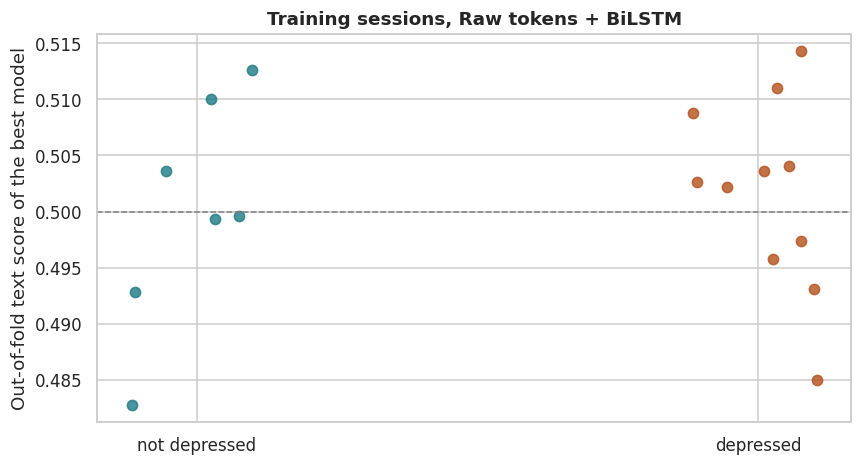

Drawing 23_fusion_ablation


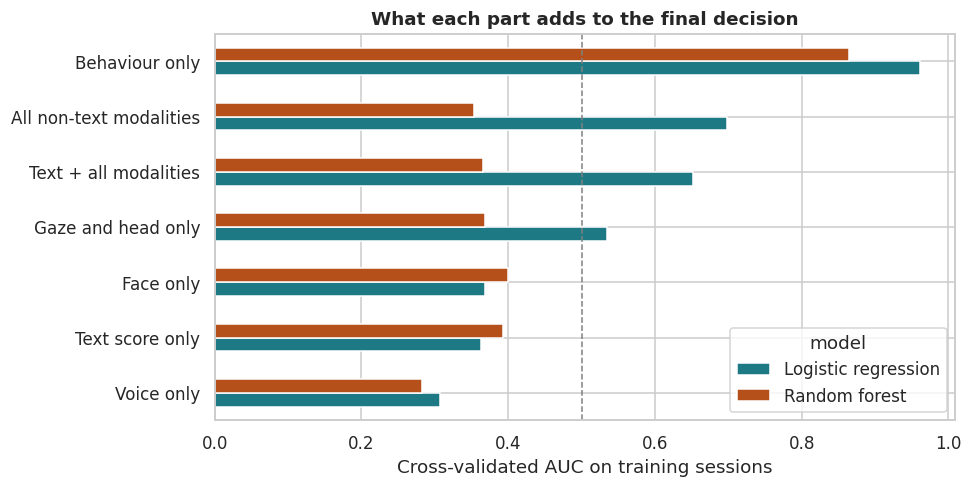

Drawing 24_fusion_importance


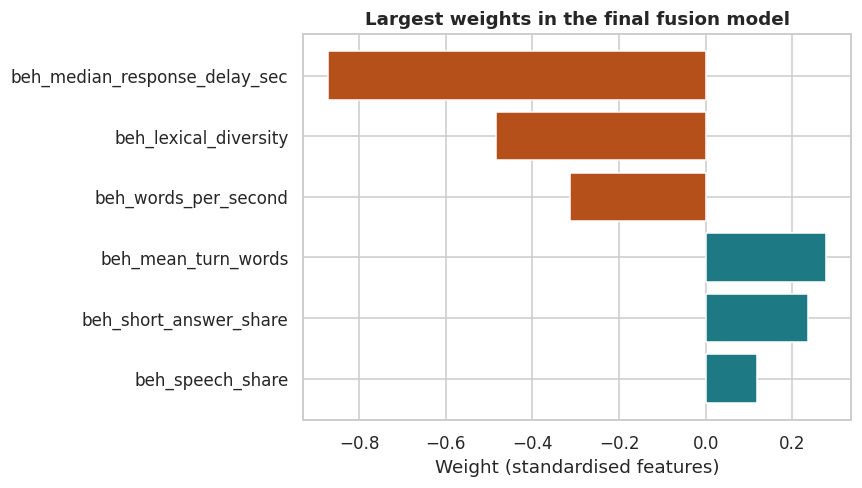

Drawing 25_case_sessions


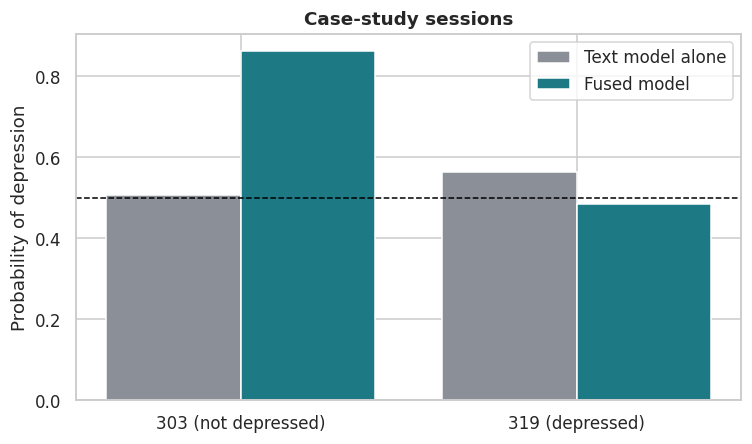

Drawing 26_confusion_heldout


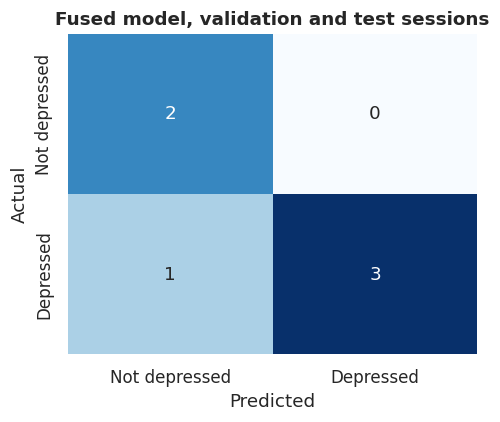

Saved 15 figures and 11 tables to /content/report_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
# REGENERATE ALL REPORT FIGURES, SAVE TABLES, ZIP
if len(FIG_FUNCS) == 0:
    raise RuntimeError("No figures registered yet. Run at least one analysis block first.")

for name in sorted(FIG_FUNCS):
    try:
        print("Drawing", name)
        FIG_FUNCS[name]()
    except Exception as e:
        plt.close("all")
        print("  skipped", name, "->", type(e).__name__, str(e)[:100])

TABLE_DIR = FIG_DIR / "tables"
TABLE_DIR.mkdir(exist_ok=True)
feature_table().round(4).to_csv(TABLE_DIR / "case_session_features.csv")
for name in ["QA", "SYMPTOM_TABLE", "overview", "summary", "TEXT_TABLE", "FUSION_CV", "OUT", "IMPORTANCE", "MM", "COHORT"]:
    obj = globals().get(name)
    if isinstance(obj, (pd.DataFrame, pd.Series)):
        obj.round(4).to_csv(TABLE_DIR / f"{name.lower()}.csv")

zip_path = FIG_DIR.parent / "report_figures.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(FIG_DIR.rglob("*")):
        if p.is_file():
            z.write(p, p.relative_to(FIG_DIR))
print("Saved", len(list(FIG_DIR.glob("*.png"))), "figures and", len(list(TABLE_DIR.glob("*.csv"))), "tables to", zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    pass

# 16. Optional appendix: pretrained models as a reference
Not used for any label, feature or decision above. This only shows how three public models score the two case sessions, for comparison with your own models. They were trained on social media text, so treat their scores as a different kind of evidence.

In [45]:
# PRETRAINED REFERENCE SCORES FOR THE CASE SESSIONS
require("CHUNK_TABLE")
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

case_chunks = CHUNK_TABLE[CHUNK_TABLE["role"] == "case"].copy()
texts = case_chunks["text"].tolist()


@torch.no_grad()
def hf_probs(model_name, texts, target_fn, batch=16):
    tok = AutoTokenizer.from_pretrained(model_name)
    mdl = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEVICE).eval()
    id2label = {int(k): v for k, v in mdl.config.id2label.items()}
    out = []
    for s in range(0, len(texts), batch):
        enc = tok(texts[s:s + batch], padding=True, truncation=True, max_length=256, return_tensors="pt").to(DEVICE)
        out.append(target_fn(torch.softmax(mdl(**enc).logits, dim=-1).cpu().numpy(), id2label))
    del mdl
    return np.concatenate(out)


def not_depression_complement(p, id2label):
    idx = next((i for i, l in id2label.items() if "not" in l.lower()), 0)
    return 1.0 - p[:, idx]


def negative_tone(p, id2label):
    return p[:, next(i for i, l in id2label.items() if "neg" in l.lower())]


case_chunks["DepRoBERTa"] = hf_probs("rafalposwiata/deproberta-large-depression", texts, not_depression_complement)
case_chunks["RoBERTa sentiment (negative)"] = hf_probs("cardiffnlp/twitter-roberta-base-sentiment-latest", texts, negative_tone)
zs_ref = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=0 if DEVICE == "cuda" else -1)
zs_labels = ["depressed and hopeless", "content and doing fine"]
zs_out = zs_ref(texts, candidate_labels=zs_labels, hypothesis_template="The person speaking is {}.", batch_size=8)
case_chunks["BART zero-shot"] = [r["scores"][r["labels"].index(zs_labels[0])] for r in zs_out]
ref_cols = ["DepRoBERTa", "RoBERTa sentiment (negative)", "BART zero-shot"]
display(case_chunks.groupby("session")[ref_cols].mean().round(3))

config.json:   0%|          | 0.00/924 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

,DepRoBERTa,RoBERTa sentiment (negative),BART zero-shot
session,,,
303,0.127,0.170,0.357
319,0.297,0.284,0.502


In [46]:
# PRETRAINED MODELS ON THE SAME WINDOWS AND SESSIONS AS THE TRAINED MODELS
require("CHUNK_TABLE", "TEXT_TABLE", "eval_scores")
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

DEV = "cuda" if torch.cuda.is_available() else "cpu"
texts = CHUNK_TABLE["text"].tolist()


@torch.no_grad()
def hf_probs(model_name, texts, target_fn, batch=16):
    tok = AutoTokenizer.from_pretrained(model_name)
    mdl = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEV).eval()
    id2label = {int(k): v for k, v in mdl.config.id2label.items()}
    print(model_name, "labels:", id2label)
    out = []
    for s in range(0, len(texts), batch):
        enc = tok(texts[s:s + batch], padding=True, truncation=True, max_length=256, return_tensors="pt").to(DEV)
        out.append(target_fn(torch.softmax(mdl(**enc).logits, dim=-1).cpu().numpy(), id2label))
    del mdl
    if DEV == "cuda":
        torch.cuda.empty_cache()
    return np.concatenate(out)


def not_depression_complement(p, id2label):
    idx = next((i for i, l in id2label.items() if "not" in l.lower()), 0)
    return 1.0 - p[:, idx]


def negative_tone(p, id2label):
    return p[:, next(i for i, l in id2label.items() if "neg" in l.lower())]


PRETRAINED_NAMES = ["DepRoBERTa (pretrained)", "RoBERTa sentiment, negative (pretrained)", "BART zero-shot (pretrained)"]
CHUNK_TABLE[PRETRAINED_NAMES[0]] = hf_probs("rafalposwiata/deproberta-large-depression", texts, not_depression_complement)
CHUNK_TABLE[PRETRAINED_NAMES[1]] = hf_probs("cardiffnlp/twitter-roberta-base-sentiment-latest", texts, negative_tone)

zs_ref = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=0 if DEV == "cuda" else -1)
zs_labels = ["depressed and hopeless", "content and doing fine"]
zs_out = zs_ref(texts, candidate_labels=zs_labels, hypothesis_template="The person speaking is {}.", batch_size=8)
CHUNK_TABLE[PRETRAINED_NAMES[2]] = [r["scores"][r["labels"].index(zs_labels[0])] for r in zs_out]
del zs_ref

# Same evaluation as the trained models. Nothing is fitted or tuned, the threshold is fixed at one half,
# and the direction of each score (higher means more depressed) is fixed in advance.
rows = []
for name in PRETRAINED_NAMES:
    row = {"model": name}
    for role, label in [("train", "oof"), ("val", "val"), ("test", "test")]:
        res = eval_scores(CHUNK_TABLE[CHUNK_TABLE["role"] == role], name)
        row.update({f"{label}_{k}": v for k, v in res.items()})
    case = CHUNK_TABLE[CHUNK_TABLE["role"] == "case"].groupby("session")[name].mean()
    row.update({f"case_{sid}_score": case.get(sid, np.nan) for sid in SESSIONS})
    rows.append(row)

TEXT_TABLE = pd.concat([TEXT_TABLE.drop(index=[n for n in PRETRAINED_NAMES if n in TEXT_TABLE.index]),
                        pd.DataFrame(rows).set_index("model")])

show = ["oof_session_auc", "oof_chunk_auc", "val_session_auc", "test_session_auc", "test_session_acc",
        "test_chunk_auc", "test_chunk_macro_f1"] + [f"case_{s}_score" for s in SESSIONS]
display(TEXT_TABLE[show].sort_values("test_session_auc", ascending=False).round(3))
print("Pretrained models are never fitted on the cohort, so their 'oof' column is simply the score on the training sessions.")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

rafalposwiata/deproberta-large-depression labels: {0: 'severe', 1: 'moderate', 2: 'not depression'}


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


cardiffnlp/twitter-roberta-base-sentiment-latest labels: {0: 'negative', 1: 'neutral', 2: 'positive'}


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

,oof_session_auc,oof_chunk_auc,val_session_auc,test_session_auc,test_session_acc,test_chunk_auc,test_chunk_macro_f1,case_303_score,case_319_score
model,,,,,,,,,
"RoBERTa sentiment, negative (pretrained)",0.649,0.539,1.0,1.0,0.333,0.544,0.396,0.170,0.284
Word2Vec + positional + BiLSTM,0.429,0.457,0.5,1.0,1.000,0.727,0.617,0.175,0.339
DepRoBERTa (pretrained),0.701,0.544,1.0,1.0,0.333,0.545,0.426,0.127,0.297
TF-IDF + logistic regression (reference),0.325,0.393,0.5,1.0,1.000,0.758,0.642,0.485,0.516
Word2Vec + BiLSTM,0.364,0.442,0.0,0.5,0.333,0.488,0.513,0.467,0.512
Word2Vec + positional + LSTM,0.468,0.420,0.0,0.5,0.667,0.482,0.471,0.502,0.502
BART zero-shot (pretrained),0.662,0.536,1.0,0.5,0.333,0.495,0.428,0.357,0.502
Raw tokens + LSTM,0.455,0.491,0.5,0.0,0.667,0.354,0.436,0.521,0.511
Raw tokens + BiLSTM,0.545,0.476,0.5,0.0,0.667,0.366,0.405,0.508,0.563


Pretrained models are never fitted on the cohort, so their 'oof' column is simply the score on the training sessions.


,oof_session_auc,val_session_auc,test_session_auc,test_session_acc,test_chunk_auc,test_chunk_macro_f1
model,,,,,,
Raw tokens + LSTM,0.455,0.5,0.0,0.667,0.354,0.436
Word2Vec + LSTM,0.273,0.0,0.0,0.333,0.415,0.433
Word2Vec + positional + LSTM,0.468,0.0,0.5,0.667,0.482,0.471
Raw tokens + BiLSTM,0.545,0.5,0.0,0.667,0.366,0.405
Word2Vec + BiLSTM,0.364,0.0,0.5,0.333,0.488,0.513
Word2Vec + positional + BiLSTM,0.429,0.5,1.0,1.000,0.727,0.617
TF-IDF + logistic regression (reference),0.325,0.5,1.0,1.000,0.758,0.642
DepRoBERTa (pretrained),0.701,1.0,1.0,0.333,0.545,0.426
"RoBERTa sentiment, negative (pretrained)",0.649,1.0,1.0,0.333,0.544,0.396


,sessions,correct,accuracy
Raw tokens + LSTM,8,5,0.625
Word2Vec + LSTM,8,3,0.375
Word2Vec + positional + LSTM,8,4,0.500
Raw tokens + BiLSTM,8,5,0.625
Word2Vec + BiLSTM,8,3,0.375
Word2Vec + positional + BiLSTM,8,6,0.750
TF-IDF + logistic regression (reference),8,6,0.750
DepRoBERTa (pretrained),8,3,0.375
"RoBERTa sentiment, negative (pretrained)",8,3,0.375
BART zero-shot (pretrained),8,4,0.500


Always answering the majority class would be right for 0.62 of these sessions.


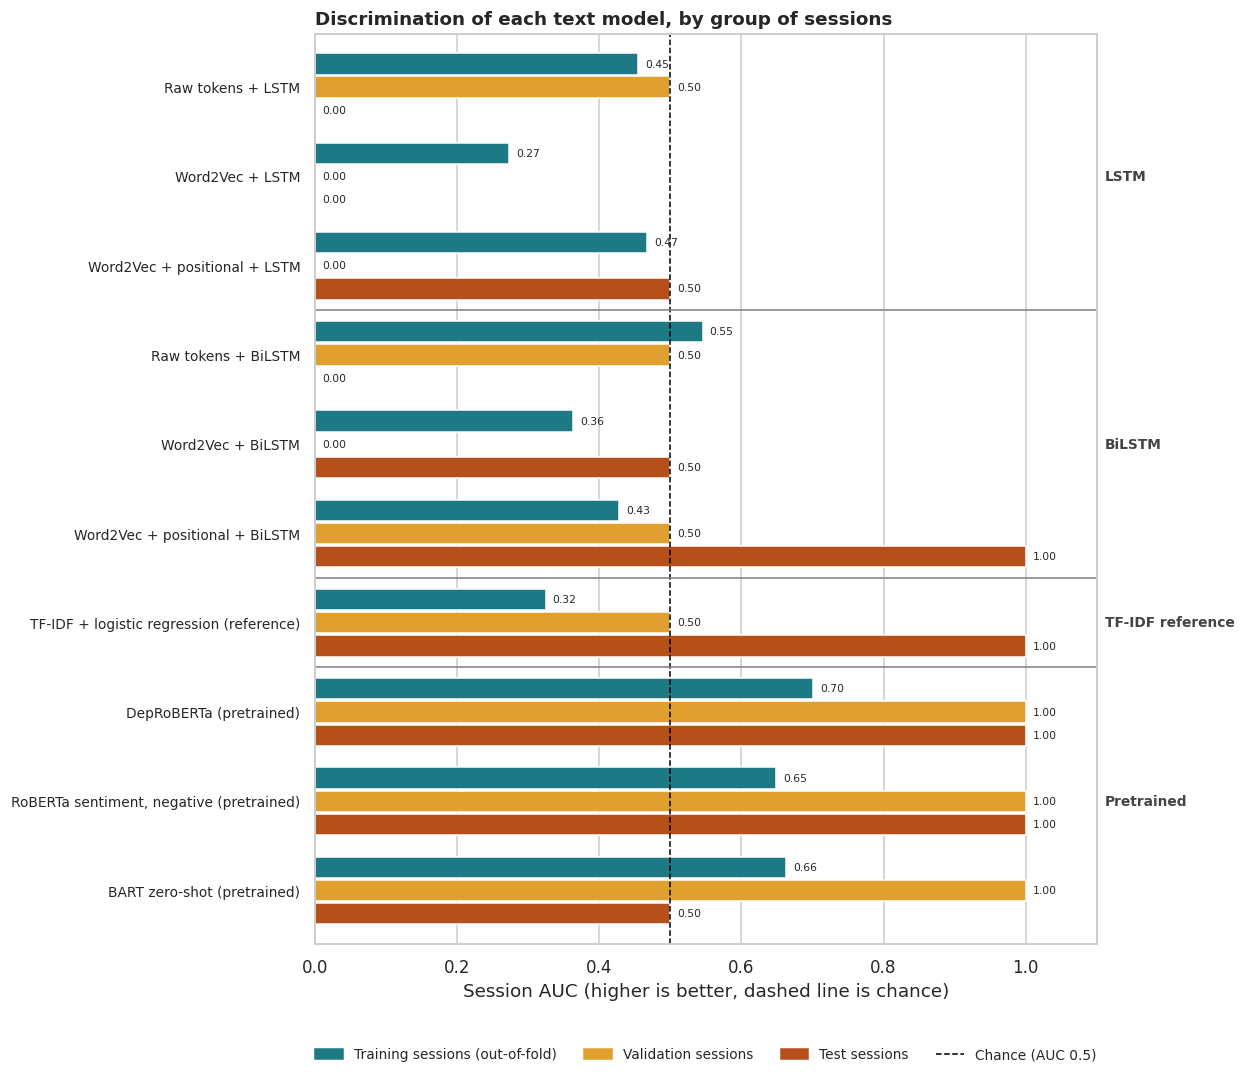

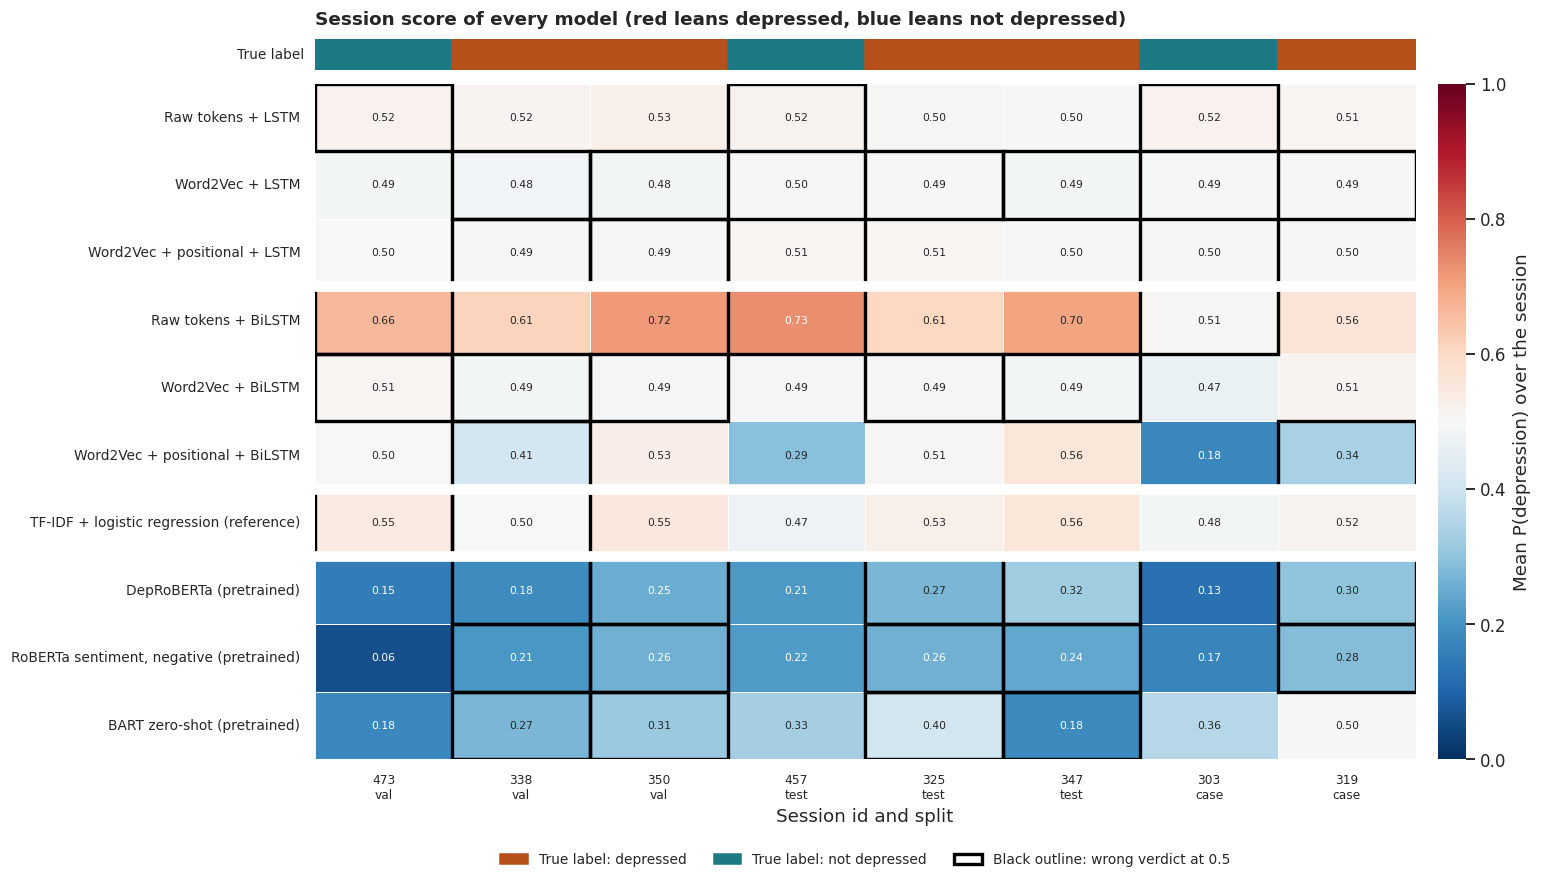

In [51]:
# MODEL COMPARISON: TWO SEPARATE, ORGANISED FIGURES (SELF-CONTAINED)
require("TEXT_TABLE", "CHUNK_TABLE")
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

FIG_FUNCS.pop("27_model_comparison", None)


def family(name):
    if "pretrained" in name:
        return "Pretrained"
    if "reference" in name:
        return "TF-IDF reference"
    return "BiLSTM" if name.endswith("BiLSTM") else "LSTM"


FAMILY_ORDER = ["LSTM", "BiLSTM", "TF-IDF reference", "Pretrained"]
original_order = list(TEXT_TABLE.index)
models = sorted(original_order, key=lambda m: (FAMILY_ORDER.index(family(m)), original_order.index(m)))
fam_of = {m: family(m) for m in models}

# Tables
cols = ["oof_session_auc", "val_session_auc", "test_session_auc", "test_session_acc", "test_chunk_auc", "test_chunk_macro_f1"]
display(TEXT_TABLE.loc[models, cols].round(3))

held = CHUNK_TABLE[CHUNK_TABLE["role"].isin(["val", "test", "case"])]
meta = held.groupby("session").agg(role=("role", "first"), label=("label", "first"))
meta = meta.assign(r=meta["role"].map({"val": 0, "test": 1, "case": 2})).sort_values(["r", "label"]).drop(columns="r")
SESSION_SCORES = held.groupby("session")[models].mean().loc[meta.index]
correct = (SESSION_SCORES >= 0.5).astype(int).eq(meta["label"], axis=0)
display(pd.DataFrame({"sessions": len(meta), "correct": correct.sum(), "accuracy": correct.mean()}).round(3).loc[models])
majority = max(meta["label"].mean(), 1 - meta["label"].mean())
print(f"Always answering the majority class would be right for {majority:.2f} of these sessions.")

SET_STYLE = [("oof_session_auc", "Training sessions (out-of-fold)", "#1D7A85"),
             ("val_session_auc", "Validation sessions", "#E0A030"),
             ("test_session_auc", "Test sessions", "#B5501A")]


def family_boundaries(order):
    return [i for i in range(1, len(order)) if fam_of[order[i]] != fam_of[order[i - 1]]]


@figure("27a_auc_by_model")
def _fig_auc():
    n = len(models)
    fig, ax = plt.subplots(figsize=(11.5, 0.75 * n + 2.4))
    h = 0.26
    for i, m in enumerate(models):
        y = n - 1 - i
        for k, (col, lab, c) in enumerate(SET_STYLE):
            v = TEXT_TABLE.loc[m, col]
            v0 = 0 if pd.isna(v) else v
            ax.barh(y + (1 - k) * h, v0, h * 0.92, color=c)
            ax.text(v0 + 0.01, y + (1 - k) * h, "n/a" if pd.isna(v) else f"{v:.2f}", va="center", fontsize=7)
    ax.axvline(0.5, color="black", ls="--", lw=1)
    for b in family_boundaries(models):
        ax.axhline(n - b - 0.5, color="grey", lw=1)
    ax.set_yticks([n - 1 - i for i in range(n)])
    ax.set_yticklabels(models, fontsize=9)
    ax.set_ylim(-0.6, n - 0.4)
    ax.set_xlim(0, 1.1)
    ax.set_xlabel("Session AUC (higher is better, dashed line is chance)")
    ax.set_title("Discrimination of each text model, by group of sessions", loc="left")
    for fam in FAMILY_ORDER:
        idx = [i for i, m in enumerate(models) if fam_of[m] == fam]
        if idx:
            ax.text(1.01, n - 1 - np.mean(idx), fam, transform=ax.get_yaxis_transform(), va="center", fontsize=9, fontweight="bold", color="#444")
    handles = [Rectangle((0, 0), 1, 1, color=c) for _, _, c in SET_STYLE] + [Line2D([0], [0], color="black", ls="--", lw=1)]
    ax.legend(handles, [lab for _, lab, _ in SET_STYLE] + ["Chance (AUC 0.5)"], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=9, frameon=False)
    ax.grid(axis="y", visible=False)


@figure("27b_session_scores")
def _fig_heat():
    n, m_sessions = len(models), len(meta)
    data = SESSION_SCORES[models].T
    fig = plt.figure(figsize=(1.0 * m_sessions + 5.5, 0.55 * n + 3.0))
    gs = fig.add_gridspec(2, 2, height_ratios=[0.45, n], width_ratios=[40, 1], hspace=0.04, wspace=0.04)
    ax_strip, ax, cax = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
    sns.heatmap(data, ax=ax, cmap="RdBu_r", center=0.5, vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"fontsize": 7},
                cbar_ax=cax, cbar_kws={"label": "Mean P(depression) over the session"}, linewidths=0.5, linecolor="white",
                xticklabels=[f"{s}\n{r}" for s, r in zip(meta.index, meta["role"])], yticklabels=models)
    ax.tick_params(axis="x", labelrotation=0, labelsize=8)
    ax.tick_params(axis="y", labelsize=9)
    ax.set_xlabel("Session id and split")
    wrong = (data >= 0.5).astype(int).ne(meta["label"].to_numpy()[None, :]).to_numpy()
    for r in range(n):
        for c in range(m_sessions):
            if wrong[r, c]:
                ax.add_patch(Rectangle((c, r), 1, 1, fill=False, edgecolor="black", lw=2.2))
    for b in family_boundaries(models):
        ax.axhline(b, color="white", lw=7)
    for c, lab in enumerate(meta["label"]):
        ax_strip.add_patch(Rectangle((c, 0), 1, 1, color=LABEL_COLORS[int(lab)]))
    ax_strip.set_xlim(0, m_sessions)
    ax_strip.set_ylim(0, 1)
    ax_strip.axis("off")
    ax_strip.text(-0.01, 0.5, "True label", ha="right", va="center", transform=ax_strip.transAxes, fontsize=9)
    handles = [Rectangle((0, 0), 1, 1, color=LABEL_COLORS[1]), Rectangle((0, 0), 1, 1, color=LABEL_COLORS[0]),
               Rectangle((0, 0), 1, 1, fill=False, edgecolor="black", lw=2.2)]
    ax.legend(handles, ["True label: depressed", "True label: not depressed", "Black outline: wrong verdict at 0.5"],
              loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=9, frameon=False)
    ax_strip.text(0, 1.35, "Session score of every model (red leans depressed, blue leans not depressed)",
                  transform=ax_strip.transAxes, fontsize=12, fontweight="bold", va="bottom")


FIG_FUNCS["27a_auc_by_model"]()
FIG_FUNCS["27b_session_scores"]()

Models shown (best of each group by training-session AUC):
  Word2Vec + positional + LSTM  (training-session AUC 0.47)
  Raw tokens + BiLSTM  (training-session AUC 0.55)
  DepRoBERTa (pretrained)  (training-session AUC 0.70)
  TF-IDF + logistic regression (reference)  (training-session AUC 0.32)


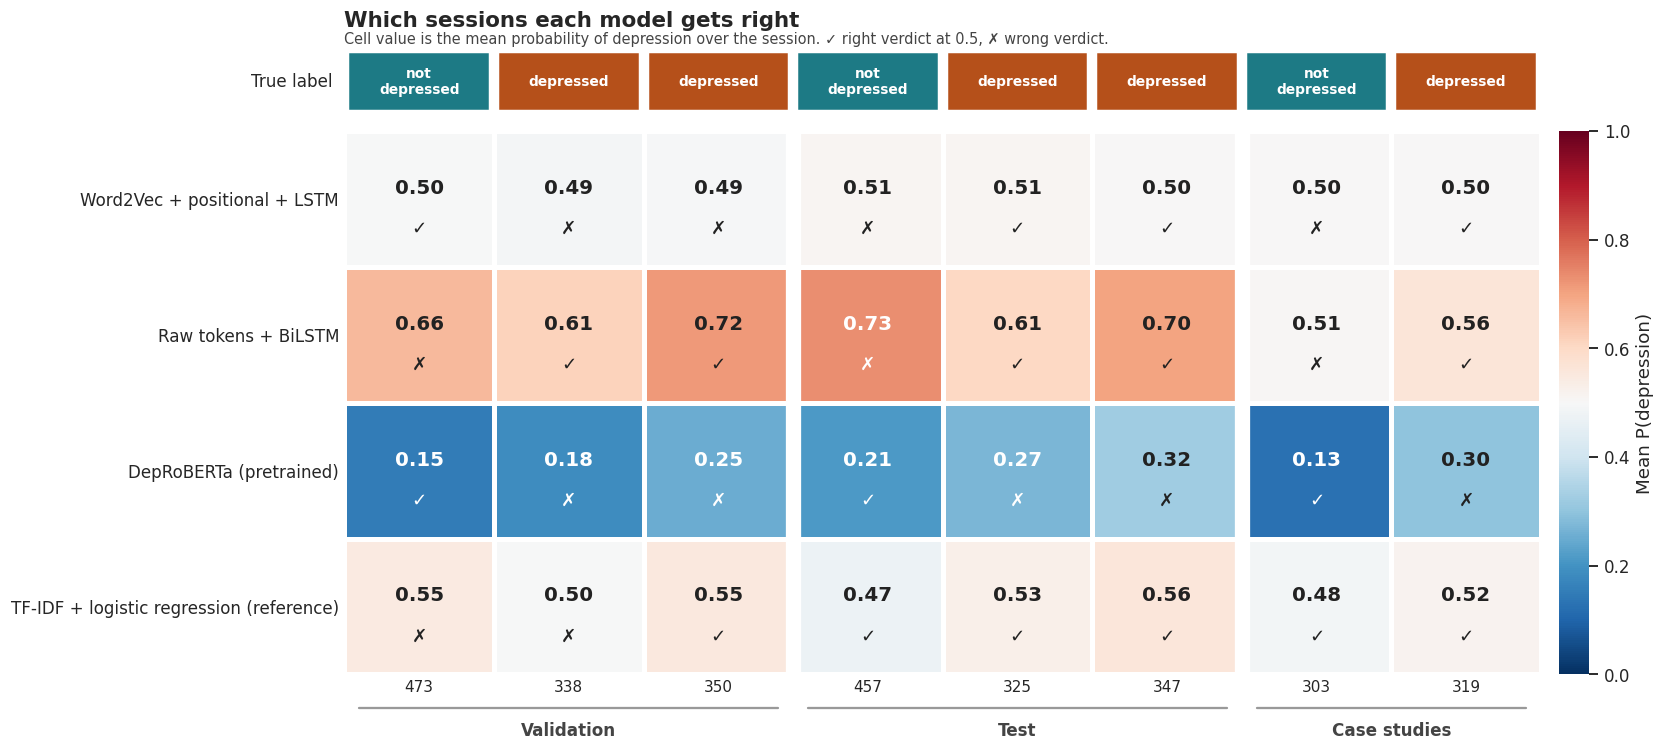

In [52]:
# CLEAN HEATMAP: ONLY THE INFLUENTIAL MODELS (SELF-CONTAINED)
require("TEXT_TABLE", "CHUNK_TABLE")
from matplotlib.patches import Rectangle

FIG_FUNCS.pop("27b_session_scores", None)
INCLUDE_REFERENCE = True


def family(name):
    if "pretrained" in name:
        return "Pretrained"
    if "reference" in name:
        return "TF-IDF reference"
    return "BiLSTM" if name.endswith("BiLSTM") else "LSTM"


# Choose by training-session (out-of-fold or never-fitted) AUC only, so the test sessions play no part in the choice.
fam_series = pd.Series({m: family(m) for m in TEXT_TABLE.index})
chosen = []
for fam in ["LSTM", "BiLSTM", "Pretrained"] + (["TF-IDF reference"] if INCLUDE_REFERENCE else []):
    members = fam_series[fam_series == fam].index
    if len(members):
        chosen.append(TEXT_TABLE.loc[members, "oof_session_auc"].idxmax())
print("Models shown (best of each group by training-session AUC):")
for m in chosen:
    print(f"  {m}  (training-session AUC {TEXT_TABLE.loc[m, 'oof_session_auc']:.2f})")

held = CHUNK_TABLE[CHUNK_TABLE["role"].isin(["val", "test", "case"])]
meta = held.groupby("session").agg(role=("role", "first"), label=("label", "first"))
meta = meta.assign(r=meta["role"].map({"val": 0, "test": 1, "case": 2})).sort_values(["r", "label"]).drop(columns="r")
SHOWN_SCORES = held.groupby("session")[chosen].mean().loc[meta.index]
SPLIT_NAMES = {"val": "Validation", "test": "Test", "case": "Case studies"}


@figure("27b_session_scores")
def _fig_heat():
    n, m = len(chosen), len(meta)
    vals = SHOWN_SCORES[chosen].T.to_numpy()
    fig = plt.figure(figsize=(1.25 * m + 4.6, 1.0 * n + 3.4))
    gs = fig.add_gridspec(2, 2, height_ratios=[0.5, n], width_ratios=[40, 1], hspace=0.05, wspace=0.03)
    ax_top, ax, cax = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])

    mesh = ax.pcolormesh(np.arange(m + 1), np.arange(n + 1), vals, cmap="RdBu_r", vmin=0, vmax=1, edgecolors="white", linewidth=2)
    ax.set_xlim(0, m)
    ax.set_ylim(n, 0)
    for r in range(n):
        for c in range(m):
            v = vals[r, c]
            ok = (v >= 0.5) == bool(meta["label"].iloc[c])
            colour = "white" if abs(v - 0.5) > 0.22 else "#222222"
            ax.text(c + 0.5, r + 0.42, f"{v:.2f}", ha="center", va="center", fontsize=13, fontweight="bold", color=colour)
            ax.text(c + 0.5, r + 0.72, "\u2713" if ok else "\u2717", ha="center", va="center", fontsize=12, color=colour)
    boundaries = [i for i in range(1, m) if meta["role"].iloc[i] != meta["role"].iloc[i - 1]]
    for b in boundaries:
        ax.axvline(b, color="white", lw=10)
    ax.set_yticks(np.arange(n) + 0.5)
    ax.set_yticklabels(chosen, fontsize=11)
    ax.set_xticks(np.arange(m) + 0.5)
    ax.set_xticklabels([str(s) for s in meta.index], fontsize=10)
    ax.tick_params(length=0)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    starts = [0] + boundaries + [m]
    for a, b in zip(starts[:-1], starts[1:]):
        ax.text((a + b) / 2, n + 0.35, SPLIT_NAMES[meta["role"].iloc[a]], ha="center", va="top", fontsize=11, fontweight="bold", color="#444")
        ax.plot([a + 0.1, b - 0.1], [n + 0.25, n + 0.25], color="#999", lw=1.5, clip_on=False)

    for c, lab in enumerate(meta["label"]):
        ax_top.add_patch(Rectangle((c + 0.04, 0.1), 0.92, 0.8, color=LABEL_COLORS[int(lab)]))
        ax_top.text(c + 0.5, 0.5, "depressed" if lab else "not\ndepressed", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    ax_top.set_xlim(0, m)
    ax_top.set_ylim(0, 1)
    ax_top.axis("off")
    ax_top.text(-0.01, 0.5, "True label", ha="right", va="center", transform=ax_top.transAxes, fontsize=11)
    ax_top.text(0, 1.25, "Which sessions each model gets right", transform=ax_top.transAxes, fontsize=14, fontweight="bold", va="bottom")
    ax_top.text(0, 1.02, "Cell value is the mean probability of depression over the session. \u2713 right verdict at 0.5, \u2717 wrong verdict.",
                transform=ax_top.transAxes, fontsize=9.5, va="bottom", color="#444")

    cb = fig.colorbar(mesh, cax=cax)
    cb.set_label("Mean P(depression)")
    cb.outline.set_visible(False)


FIG_FUNCS["27b_session_scores"]()

#Tables

In [53]:
# REPORT TABLES: LaTeX rows for every table in main.tex, plus the numbers for the text (run after the final export cell)
import subprocess, platform, sys, shutil
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

require("TEXT_TABLE", "CHUNK_TABLE", "FUSION_CV", "OUT", "COHORT", "FEATURE_SETS", "FUSION")
TAB_DIR = FIG_DIR / "tables"
TAB_DIR.mkdir(exist_ok=True)


def f3(x):
    return "--" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.3f}"


def emit(name, header, rows):
    """Print LaTeX body rows (paste between \\midrule and \\bottomrule) and save them."""
    body = "\n".join(" & ".join(str(c) for c in r) + r" \\" for r in rows)
    print(f"\n% ===== {name}: {header} =====\n{body}")
    (TAB_DIR / f"{name}.tex").write_text(body)
    pd.DataFrame(rows, columns=header.split(" | ")).to_csv(TAB_DIR / f"{name}.csv", index=False)


def sess_metrics(df, col):
    s = df.groupby("session").agg(p=(col, "mean"), y=("label", "first"))
    y, p = s["y"].astype(int), s["p"]
    pred = (p >= 0.5).astype(int)
    auc = roc_auc_score(y, p) if y.nunique() > 1 else np.nan
    return auc, accuracy_score(y, pred), f1_score(y, pred, zero_division=0), len(s)


# ---------- Table 1: session counts ----------
cnt = pd.crosstab(COHORT["role"], COHORT["PHQ8_Binary"]).reindex(["train", "val", "test"]).fillna(0).astype(int)
for c in (0, 1):
    if c not in cnt.columns:
        cnt[c] = 0
rows = [[nm, int(cnt.loc[r].sum()), int(cnt.loc[r, 1]), int(cnt.loc[r, 0])] for nm, r in [("Training", "train"), ("Validation", "val"), ("Test", "test")]]
rows.append(["Case studies (303, 319)", 2, 1, 1])
emit("table1_split", "Partition | Sessions | Depressed | Not depressed", rows)
print(f"\nCohort total {len(COHORT)} | depressed {int((COHORT['PHQ8_Binary'] == 1).sum())} | not depressed {int((COHORT['PHQ8_Binary'] == 0).sum())}")


# ---------- Table 2: text-model comparison ----------
def family(n):
    if "pretrained" in n:
        return "Pretrained"
    if "reference" in n:
        return "TF-IDF"
    return "BiLSTM" if n.endswith("BiLSTM") else "LSTM"


fam = pd.Series({m: family(m) for m in TEXT_TABLE.index})
test_df = CHUNK_TABLE[CHUNK_TABLE["role"] == "test"]
rows = []
for f in ["LSTM", "BiLSTM", "TF-IDF", "Pretrained"]:
    mem = fam[fam == f].index
    if not len(mem):
        continue
    chosen = [TEXT_TABLE.loc[mem, "oof_session_auc"].idxmax()] if f != "Pretrained" else list(mem)
    for m in chosen:
        auc, acc, f1, n = sess_metrics(test_df, m)
        t = TEXT_TABLE.loc[m]
        rows.append([m, f3(t["oof_session_auc"]), f3(t["val_session_auc"]), f3(auc), f3(acc), f3(f1)])
maj = test_df.groupby("session")["label"].first()
rows.append(["Majority class", "--", "--", "0.500", f3(max(maj.mean(), 1 - maj.mean())), "--"])
emit("table2_text_models", "Model | OOF AUC | Val AUC | Test AUC | Test accuracy | Test F1", rows)
print(f"(test sessions: {len(maj)})")
print("\nAll neural configurations (for the Figure 20 discussion):")
neural = [m for m in TEXT_TABLE.index if family(m) in ("LSTM", "BiLSTM")]
display(TEXT_TABLE.loc[neural, ["oof_session_auc", "val_session_auc", "test_session_auc", "test_session_acc"]].round(3))

# ---------- Table 3: fusion feature sets ----------
trn, tst = FUSION[FUSION["role"] == "train"], FUSION[FUSION["role"] == "test"]
rows = []
for fs_name, cols in FEATURE_SETS.items():
    sub = FUSION_CV[FUSION_CV["feature_set"] == fs_name].sort_values("cv_auc", ascending=False).iloc[0]
    mdl = make_model(sub["model"]).fit(trn[cols], trn["label"].astype(int))
    pr = mdl.predict_proba(tst[cols])[:, 1]
    yt = tst["label"].astype(int).to_numpy()
    auc = roc_auc_score(yt, pr) if len(set(yt)) > 1 else np.nan
    rows.append([fs_name, f3(sub["cv_auc"]), f3(auc), f3(accuracy_score(yt, pr >= 0.5)), f3(f1_score(yt, (pr >= 0.5).astype(int), zero_division=0))])
emit("table3_fusion", "Feature set | CV AUC | Test AUC | Test accuracy | Test F1", rows)
print("\nFusion CV, both classifiers:")
display(FUSION_CV[["feature_set", "model", "n_features", "cv_auc", "cv_auc_sd", "cv_macro_f1"]].round(3))

# ---------- Final fused model: numbers for the abstract, conclusion and confusion matrix ----------
print(f"\nFinal fusion model chosen on training CV: {BEST_FUSION}")
for nm, roles in [("test", ["test"]), ("held-out (val + test)", ["val", "test"])]:
    sub = OUT[OUT["role"].isin(roles)]
    y, p = sub["label"].astype(int), sub["fusion_prob"]
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    auc = roc_auc_score(y, p) if y.nunique() > 1 else np.nan
    print(f"{nm}: n={len(sub)} AUC={f3(auc)} acc={accuracy_score(y, pred):.3f} precision={precision_score(y, pred, zero_division=0):.3f} "
          f"recall={recall_score(y, pred, zero_division=0):.3f} F1={f1_score(y, pred, zero_division=0):.3f} | TP={tp} FP={fp} TN={tn} FN={fn}")
print("Best text model used in fusion:", BEST)
print("Number of non-text summary features:", len(MM_COLS))
if "SHUFFLE_RESULT" in globals():
    print("Shuffled-label control:", SHUFFLE_RESULT)


# ---------- Section 4.2: hardware and software ----------
def sh(cmd):
    try:
        return subprocess.run(cmd, shell=True, capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception:
        return "n/a"


print("\n--- Hardware and software ---")
print("CPU:", sh("lscpu | grep 'Model name' | sed 's/Model name: *//'"))
print("CPU cores:", sh("nproc"))
print("RAM (GB):", sh("free -g | awk '/Mem:/{print $2}'"))
print("GPU:", sh("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader") or "none")
print("OS:", platform.platform())
print("Python:", sys.version.split()[0])
for mod in ["torch", "gensim", "sklearn", "transformers", "pandas", "numpy", "matplotlib"]:
    try:
        print(f"{mod}:", __import__(mod).__version__)
    except Exception:
        print(f"{mod}: not installed")

shutil.make_archive(str(FIG_DIR.parent / "report_tables"), "zip", TAB_DIR)
print("\nSaved LaTeX rows and CSVs in", TAB_DIR, "and zipped to", FIG_DIR.parent / "report_tables.zip")


% ===== table1_split: Partition | Sessions | Depressed | Not depressed =====
Training & 18 & 11 & 7 \\
Validation & 3 & 2 & 1 \\
Test & 3 & 2 & 1 \\
Case studies (303, 319) & 2 & 1 & 1 \\

Cohort total 24 | depressed 15 | not depressed 9

% ===== table2_text_models: Model | OOF AUC | Val AUC | Test AUC | Test accuracy | Test F1 =====
Word2Vec + positional + LSTM & 0.468 & 0.000 & 0.500 & 0.667 & 0.800 \\
Raw tokens + BiLSTM & 0.545 & 0.500 & 0.000 & 0.667 & 0.800 \\
TF-IDF + logistic regression (reference) & 0.325 & 0.500 & 1.000 & 1.000 & 1.000 \\
DepRoBERTa (pretrained) & 0.701 & 1.000 & 1.000 & 0.333 & 0.000 \\
RoBERTa sentiment, negative (pretrained) & 0.649 & 1.000 & 1.000 & 0.333 & 0.000 \\
BART zero-shot (pretrained) & 0.662 & 1.000 & 0.500 & 0.333 & 0.000 \\
Majority class & -- & -- & 0.500 & 0.667 & -- \\
(test sessions: 3)

All neural configurations (for the Figure 20 discussion):


,oof_session_auc,val_session_auc,test_session_auc,test_session_acc
model,,,,
Raw tokens + LSTM,0.455,0.5,0.0,0.667
Raw tokens + BiLSTM,0.545,0.5,0.0,0.667
Word2Vec + LSTM,0.273,0.0,0.0,0.333
Word2Vec + BiLSTM,0.364,0.0,0.5,0.333
Word2Vec + positional + LSTM,0.468,0.0,0.5,0.667
Word2Vec + positional + BiLSTM,0.429,0.5,1.0,1.000



% ===== table3_fusion: Feature set | CV AUC | Test AUC | Test accuracy | Test F1 =====
Text score only & 0.394 & 0.500 & 0.667 & 0.800 \\
Voice only & 0.306 & 0.000 & 0.333 & 0.500 \\
Face only & 0.400 & 1.000 & 0.667 & 0.667 \\
Gaze and head only & 0.535 & 0.500 & 0.667 & 0.800 \\
Behaviour only & 0.961 & 1.000 & 0.667 & 0.667 \\
All non-text modalities & 0.699 & 1.000 & 1.000 & 1.000 \\
Text + all modalities & 0.652 & 1.000 & 0.667 & 0.800 \\

Fusion CV, both classifiers:


,feature_set,model,n_features,cv_auc,cv_auc_sd,cv_macro_f1
0,Behaviour only,Logistic regression,6,0.961,0.023,0.884
1,Behaviour only,Random forest,6,0.865,0.051,0.749
2,All non-text modalities,Logistic regression,39,0.699,0.086,0.579
3,Text + all modalities,Logistic regression,40,0.652,0.075,0.581
4,Gaze and head only,Logistic regression,8,0.535,0.089,0.488
5,Face only,Random forest,11,0.400,0.068,0.434
6,Text score only,Random forest,1,0.394,0.114,0.351
7,Face only,Logistic regression,11,0.369,0.033,0.424
8,Gaze and head only,Random forest,8,0.369,0.062,0.429
9,Text + all modalities,Random forest,40,0.366,0.127,0.403



Final fusion model chosen on training CV: ('Behaviour only', 'Logistic regression')
test: n=3 AUC=1.000 acc=0.667 precision=1.000 recall=0.500 F1=0.667 | TP=1 FP=0 TN=1 FN=1
held-out (val + test): n=6 AUC=0.875 acc=0.833 precision=1.000 recall=0.750 F1=0.857 | TP=3 FP=0 TN=2 FN=1
Best text model used in fusion: Raw tokens + BiLSTM
Number of non-text summary features: 39

--- Hardware and software ---
CPU: Intel(R) Xeon(R) CPU @ 2.20GHz
CPU cores: 2
RAM (GB): 12
GPU: none
OS: Linux-6.6.159+-x86_64-with-glibc2.39
Python: 3.13.18
torch: 2.14.1+cpu
gensim: 4.4.0
sklearn: 1.6.1
transformers: 5.22.1
pandas: 2.2.3
numpy: 2.4.6
matplotlib: 3.10.0

Saved LaTeX rows and CSVs in /content/report_figures/tables and zipped to /content/report_tables.zip
